# Avance 2.8. Ingeniería de características con PTB-XL

Equipo 8 · Cardio AI:

- Clara Janet Rivera Medina A01173512
- José Emiliano Luna López A01551757
- Andre Nicolai Gutierrez Bautista A01793606

Este notebook desarrolla la fase de preparación de los datos del proyecto de detección de cardiopatías con ECG de 12 derivaciones. El conjunto del patrocinador todavía no está disponible, así que seguimos con PTB-XL 1.0.3, el mismo conjunto público del Avance 1. El propósito es transformar los ECG en un conjunto de variables útil para el aprendizaje automático y, al mismo tiempo, reducir el riesgo de características sesgadas y acelerar la convergencia de los algoritmos sensibles a la escala.

Cada integrante preparó una versión propia y esta es la versión del equipo, que reúne lo mejor de las tres. Las versiones individuales están en la misma carpeta (`Avance2.8-ag`, `Avance2.8-el` y `Avance2.8-jr`).

| Parte | Origen |
| --- | --- |
| Estructura general, medición de cada ECG, comprobación contra las lecturas del cardiólogo, atajos en los metadatos, comparación de conjuntos y prueba con 2,000 etiquetas | Andre |
| Recorte de extremos, indicadores de medición fallida, un ECG por paciente con corrección por comparaciones múltiples, PCA y análisis factorial por bloques de derivaciones, normalización de Cornell por sexo | Emiliano (varias también en la versión de Andre) |
| Evaluación con las cinco superclases del Avance 1, precaución sobre el segmento ST en jóvenes, redacción sencilla | Janet |

Cómo se relaciona cada sección con la rúbrica:

| Secciones | Contenido | Criterio de la rúbrica |
| --- | --- | --- |
| 1 a 3 | Configuración, variable objetivo, particiones y metadatos | Punto de partida |
| 4 y 5 | Mediciones desde la señal y características derivadas con criterio clínico | Construcción |
| 6 a 8 | Limpieza, discretización y codificación | Construcción |
| 9 y 10 | Transformación de las distribuciones y escalamiento, con su efecto en la convergencia | Normalización |
| 11 | Filtros: varianza, ANOVA, chi-cuadrado y correlación | Selección |
| 12 y 13 | PCA, análisis factorial y comprobación de la reducción | Extracción |
| 14 y 15 | Archivos de la fase y conclusiones en el contexto de CRISP-ML(Q) | Conclusiones |

El notebook se ejecuta de principio a fin en orden. La primera vez mide los 21,799 ECG en paralelo y guarda las mediciones en `outputs/avance2_fusion/`; las siguientes ejecuciones las leen de ese archivo.

## 1. Configuración

In [1]:
from pathlib import Path
import ast
import hashlib
import inspect
import json
import os
import platform
import time
import warnings
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.ndimage import uniform_filter1d
from scipy.signal import butter, find_peaks, sosfiltfilt, welch
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import VarianceThreshold, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import (
    KBinsDiscretizer, MinMaxScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer, StandardScaler,
)

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").exists()), Path.cwd())
DATA = Path(os.environ.get("PTBXL_DIR", ROOT / "data/raw/ptb-xl/1.0.3"))
OUT = Path(os.environ.get("AVANCE2_OUT", ROOT / "outputs/avance2_fusion"))
if not (DATA / "ptbxl_database.csv").exists():
    raise FileNotFoundError("Abre este notebook desde la carpeta del proyecto o indica la carpeta de PTB-XL 1.0.3 en la variable PTBXL_DIR.")
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
WORKERS = min(16, os.cpu_count())  # procesos para medir los ECG en paralelo
FS = 500
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948",
)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
DIVERGING = LinearSegmentedColormap.from_list("azul_rojo", [BLUE, "#f0efec", RED])
SEQUENTIAL = LinearSegmentedColormap.from_list("azul", ["#ffffff", "#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white", "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelsize": 9.5, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
})
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
VERSIONS = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib"]}
print(f"Python {platform.python_version()} | " + " | ".join(f"{k} {v}" for k, v in VERSIONS.items()))
print("Datos:", DATA.relative_to(ROOT) if DATA.is_relative_to(ROOT) else DATA, "| salidas:", OUT.relative_to(ROOT) if OUT.is_relative_to(ROOT) else OUT)

Python 3.11.13 | numpy 2.4.6 | pandas 3.0.6 | scipy 1.17.1 | scikit-learn 1.9.1 | matplotlib 3.11.2
Datos: data/raw/ptb-xl/1.0.3 | salidas: outputs/avance2_fusion


## 2. Datos: Estructura, variable objetivo y particiones

Antes de construir características recordemos del EDA si todos los registros tienen la misma estructura. Si la frecuencia de muestreo, la duración o el orden de las derivaciones cambiaran entre registros, una misma medición (por ejemplo, "amplitud en V5") significaría cosas distintas en cada ECG.

In [2]:
meta = pd.read_csv(DATA / "ptbxl_database.csv", index_col="ecg_id")
scp = pd.read_csv(DATA / "scp_statements.csv", index_col=0)


def read_header(record: str) -> dict:
    lines = (DATA / f"{record}.hea").read_text().splitlines()
    n_leads, fs, n_samples = (int(v) for v in lines[0].split()[1:4])
    fields = [line.split() for line in lines[1:1 + n_leads]]
    return {
        "derivaciones": n_leads, "frecuencia_hz": fs, "muestras": n_samples,
        "formato": "|".join(sorted({f[1] for f in fields})), "ganancia": "|".join(sorted({f[2] for f in fields})),
        "orden": " ".join(f[-1] for f in fields),
    }


headers = pd.DataFrame([read_header(r) for r in meta.filename_hr], index=meta.index)
print(f"Metadatos: {meta.shape[0]:,} ECG x {meta.shape[1]} columnas | pacientes únicos: {meta.patient_id.nunique():,}")
display(headers.value_counts().rename("ECG").reset_index())

Metadatos: 21,799 ECG x 27 columnas | pacientes únicos: 18,869


,derivaciones,frecuencia_hz,muestras,formato,ganancia,orden,ECG
0,12,500,5000,16,1000.0(0)/mV,I II III AVR AVL AVF V1 V2 V3 V4 V5 V6,21799


Los 21,799 ECG (18,869 pacientes) comparten una sola estructura: 12 derivaciones, 500 Hz, 5,000 muestras (10 s), formato de 16 bits, ganancia de 1,000 unidades por mV y el mismo orden de derivaciones. No hace falta remuestrear, recortar ni reordenar, y la conversión a mV es dividir entre 1,000.

### Variable objetivo y particiones

PTB-XL, como vimos en el EDA, tiene una columna `scp_codes` con los códigos que el cardiólogo asignó a cada ECG, y la tabla `scp_statements.csv` agrupa los códigos diagnósticos en cinco superclases: `NORM` (normal), `MI` (infarto), `STTC` (cambios del segmento ST y la onda T), `CD` (trastornos de conducción) y `HYP` (hipertrofia). En el Avance 1 las tratamos como un objetivo multietiqueta. Aquí las usamos de dos formas:

- Objetivo del proyecto (binario). Clase 1, cardiopatía: el ECG tiene algún código de `MI`, `STTC`, `CD` o `HYP`. Clase 0, normal: solo tiene la superclase `NORM`. Es la pregunta que hará el tamizaje: ¿este ECG necesita seguimiento?
- Etiquetas auxiliares. Las cuatro superclases de enfermedad se conservan como columnas 0/1. En la sección 11 medimos la relevancia de cada característica frente a cada una por separado.

Los ECG sin ningún código diagnóstico no se pueden llamar normales ni asignar a una enfermedad, así que se excluyen, igual que en el Avance 1. También guardamos `dx_group`, que dice a cuál superclase pertenece el ECG cuando tiene una sola (`MIXTA` si tiene varias); sirve para elegir ejemplos y para el perfil de la sección 5.

Para las particiones usamos los diez pliegues que publican los autores (`strat_fold`), que mantienen a cada paciente en un solo pliegue: 1 a 8 para entrenar, 9 para validar y 10 para la prueba final. Dividir al azar por ECG pondría registros del mismo paciente en entrenamiento y validación y haría parecer mejores a las características. Todo lo que se ajusta en este notebook (medianas, límites, exponentes, medias, filtros y componentes) se ajusta solo con entrenamiento.

In [3]:
codes = meta.scp_codes.apply(ast.literal_eval)
diagnostic_class = scp.loc[scp.diagnostic == 1, "diagnostic_class"]
SUPERCLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
PATHOLOGY = SUPERCLASSES[1:]

found = codes.apply(lambda d: {diagnostic_class[c] for c in d if c in diagnostic_class.index})
for name in SUPERCLASSES:
    meta[name] = found.apply(lambda s: name in s).astype(int)
meta["target"] = np.where(meta[PATHOLOGY].any(axis=1), 1.0, np.where(meta.NORM == 1, 0.0, np.nan))
meta["dx_group"] = np.where(meta[SUPERCLASSES].sum(axis=1) == 1, meta[SUPERCLASSES].idxmax(axis=1), "MIXTA")
meta["split"] = np.select([meta.strat_fold <= 8, meta.strat_fold == 9], ["train", "val"], "test")

composition = pd.Series({
    "Solo NORM (clase 0)": int((meta.target == 0).sum()),
    "Alguna de MI, STTC, CD, HYP (clase 1)": int((meta.target == 1).sum()),
    "   de ellos, además con NORM": int(((meta.target == 1) & (meta.NORM == 1)).sum()),
    "   de ellos, con más de una superclase de enfermedad": int((meta[PATHOLOGY].sum(axis=1) > 1).sum()),
    "Sin ninguna superclase diagnóstica (se excluyen)": int(meta.target.isna().sum()),
}, name="ECG").to_frame()
display(composition)
display(pd.DataFrame({"ECG con la superclase": meta[SUPERCLASSES].sum(), "% de los ECG": 100 * meta[SUPERCLASSES].mean()}).T)

by_split = meta.groupby("split")
partition = pd.DataFrame({
    "pliegues": {"train": "1-8", "val": "9", "test": "10"},
    "ECG": by_split.size(), "con_etiqueta": by_split.target.count(),
    "pacientes": by_split.patient_id.nunique(), "cardiopatia_%": 100 * by_split.target.mean(),
}).loc[["train", "val", "test"]]
display(partition)
shared = int(meta.groupby("patient_id").split.nunique().gt(1).sum())
print(f"Pacientes presentes en más de una partición: {shared}")

,ECG
Solo NORM (clase 0),9069
"Alguna de MI, STTC, CD, HYP (clase 1)",12319
"de ellos, además con NORM",445
"de ellos, con más de una superclase de enfermedad",4707
Sin ninguna superclase diagnóstica (se excluyen),411


,NORM,MI,STTC,CD,HYP
ECG con la superclase,9514.000,5469.000,5235.000,4898.000,2649.000
% de los ECG,43.644,25.088,24.015,22.469,12.152


,pliegues,ECG,con_etiqueta,pacientes,cardiopatia_%
train,1-8,17418,17084,15023,57.604
val,9,2183,2146,1942,57.409
test,10,2198,2158,1904,57.739


Pacientes presentes en más de una partición: 0


De esto concluimos que:

- Hay 9,069 ECG normales y 12,319 con cardiopatía. De estos últimos, 445 también llevan el código `NORM` junto a otro hallazgo y se cuentan como cardiopatía, y 4,707 tienen más de una superclase de enfermedad. Se excluyen 411 ECG sin superclase diagnóstica.
- Las superclases se solapan (suman más que el total): `NORM` 9,514 (43.6%), `MI` 5,469 (25.1%), `STTC` 5,235 (24.0%), `CD` 4,898 (22.5%) y `HYP` 2,649 (12.2%).
- La prevalencia de cardiopatía es casi idéntica en las tres particiones (57.6%, 57.4% y 57.7%) y ningún paciente aparece en más de una. Las clases están razonablemente equilibradas, así que no aplicamos remuestreo.

## 3. Predictores candidatos en los metadatos

PTB-XL trae 27 columnas de metadatos. Para cada una nos hacemos dos preguntas: ¿existe en el momento de predecir, antes de que un cardiólogo lea el ECG?, y ¿describe al corazón del paciente o describe cómo se hizo el registro? Cada columna se clasifica en un grupo con su decisión.

In [4]:
ROLES = {
    "Identificador": (["patient_id", "filename_lr", "filename_hr"], "Excluir",
                      "No describe el corazón; patient_id solo se usa para comprobar la partición"),
    "Partición": (["strat_fold"], "Usar para dividir", "Pliegues estratificados por paciente publicados con el dataset"),
    "Demografía": (["age", "sex", "height", "weight"], "Evaluar",
                   "Atributos del paciente disponibles antes de leer el ECG"),
    "Adquisición": (["nurse", "site", "device", "recording_date"], "Excluir",
                    "Describen el hospital y el equipo, no al paciente"),
    "Lectura del cardiólogo": (["report", "scp_codes", "heart_axis", "infarction_stadium1", "infarction_stadium2",
                                "extra_beats", "pacemaker"], "Excluir (fuga de la etiqueta)",
                               "Se escriben al diagnosticar; de scp_codes sale el objetivo"),
    "Proceso de anotación": (["validated_by", "second_opinion", "initial_autogenerated_report", "validated_by_human"],
                             "Excluir", "Describen cómo se etiquetó, no existen al momento de predecir"),
    "Calidad anotada a mano": (["baseline_drift", "static_noise", "burst_noise", "electrodes_problems"], "Excluir",
                               "Anotación humana; la calidad se medirá desde la señal"),
}
roles = pd.DataFrame([
    {"columna": c, "grupo": group, "decisión": decision, "motivo": reason}
    for group, (columns, decision, reason) in ROLES.items() for c in columns
]).set_index("columna")
roles["faltantes_%"] = (100 * meta[roles.index].isna().mean()).round(1)
roles["valores_distintos"] = meta[roles.index].nunique()
assert set(roles.index) == set(pd.read_csv(DATA / "ptbxl_database.csv", nrows=0).columns) - {"ecg_id"}
with pd.option_context("display.max_colwidth", 90):
    display(roles[["grupo", "faltantes_%", "valores_distintos", "decisión", "motivo"]])

,grupo,faltantes_%,valores_distintos,decisión,motivo
columna,,,,,
patient_id,Identificador,0.0,18869,Excluir,No describe el corazón; patient_id solo se usa para comprobar la partición
filename_lr,Identificador,0.0,21799,Excluir,No describe el corazón; patient_id solo se usa para comprobar la partición
filename_hr,Identificador,0.0,21799,Excluir,No describe el corazón; patient_id solo se usa para comprobar la partición
strat_fold,Partición,0.0,10,Usar para dividir,Pliegues estratificados por paciente publicados con el dataset
age,Demografía,0.0,89,Evaluar,Atributos del paciente disponibles antes de leer el ECG
sex,Demografía,0.0,2,Evaluar,Atributos del paciente disponibles antes de leer el ECG
height,Demografía,68.0,77,Evaluar,Atributos del paciente disponibles antes de leer el ECG
weight,Demografía,56.8,127,Evaluar,Atributos del paciente disponibles antes de leer el ECG
nurse,Adquisición,6.8,12,Excluir,"Describen el hospital y el equipo, no al paciente"


Para las columnas candidatas medimos dos cosas. La V de Cramér resume qué tan asociada está una variable categórica con el objetivo: va de 0 (ninguna relación) a 1 (la variable determina la clase). El AUROC mide qué tan bien se separan las dos clases al ordenar los ECG por una puntuación: 0.5 equivale a adivinar y 1.0 a separarlas por completo. Aquí la puntuación es la prevalencia de cardiopatía de cada categoría en entrenamiento, y se mide en validación.

Una columna que no describe al corazón y aun así predice la etiqueta es un atajo: el modelo aprendería cómo trabajaba el hospital, no cardiología.

In [5]:
def cramers_v(a: pd.Series, b: pd.Series) -> dict:
    table = pd.crosstab(a, b)
    chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return {"chi2": chi2, "gl": dof, "p": p, "V_Cramer": v, "esperada_min": expected.min()}


meta["age_90plus"] = meta.age > 89
meta["age"] = meta.age.where(~meta.age_90plus, 90)

labeled = meta.target.notna()
in_train, in_val = labeled & (meta.split == "train"), labeled & (meta.split == "val")
candidates = {
    "sex": meta.sex, "device": meta.device, "site": meta.site.fillna(-1), "nurse": meta.nurse.fillna(-1),
    "validated_by_human": meta.validated_by_human, "initial_autogenerated_report": meta.initial_autogenerated_report,
    "weight registrado": meta.weight.notna(), "height registrado": meta.height.notna(),
    "infarction_stadium1 registrado": meta.infarction_stadium1.notna(),
}
evidence = []
for name, column in candidates.items():
    prevalence = meta.target[in_train].groupby(column[in_train]).mean()
    score = column[in_val].map(prevalence).fillna(meta.target[in_train].mean())
    evidence.append({"columna": name, "categorías": column[in_train].nunique(),
                     "V_Cramer_train": cramers_v(column[in_train], meta.target[in_train])["V_Cramer"],
                     "AUROC_val_solo_esa_columna": roc_auc_score(meta.target[in_val], score)})
evidence.append({"columna": "age", "categorías": meta.age[in_train].nunique(), "V_Cramer_train": np.nan,
                 "AUROC_val_solo_esa_columna": roc_auc_score(meta.target[in_val], meta.age[in_val])})
display(pd.DataFrame(evidence).set_index("columna").sort_values("AUROC_val_solo_esa_columna", ascending=False))

device_table = pd.DataFrame({
    "ECG_train": meta.device[in_train].value_counts(),
    "cardiopatia_%": 100 * meta.target[in_train].groupby(meta.device[in_train]).mean(),
}).sort_values("ECG_train", ascending=False)
display(device_table.head(5))
print(f"Edades sustituidas por 90 (el dataset publica 300 para mayores de 89 años): {int(meta.age_90plus.sum())}")
print(f"Mediana de edad: {meta.age.median():.0f} años | menores de 30 años: {100 * (meta.age < 30).mean():.1f}% de los ECG")
print("ECG validados por un cardiólogo (validated_by_human), % por partición:", (100 * meta.groupby("split").validated_by_human.mean()).round(1).to_dict())
print("Cardiopatía por sexo (0 = hombre, 1 = mujer), % en train:", (100 * meta.target[in_train].groupby(meta.sex[in_train]).mean()).round(1).to_dict(),
      "| en val:", (100 * meta.target[in_val].groupby(meta.sex[in_val]).mean()).round(1).to_dict())

,categorías,V_Cramer_train,AUROC_val_solo_esa_columna
columna,,,
age,89,NaN,0.771
infarction_stadium1 registrado,2,0.506,0.715
device,11,0.306,0.657
weight registrado,2,0.195,0.611
site,51,0.072,0.572
sex,2,0.142,0.510
validated_by_human,2,0.178,0.500
height registrado,2,0.030,0.499
initial_autogenerated_report,2,0.166,0.497


,ECG_train,cardiopatia_%
device,,
CS100 3,5766,70.864
AT-6 C 5.5,3147,54.655
CS-12,2679,58.343
CS-12 E,1980,20.101
AT-6 6,1798,58.065


Edades sustituidas por 90 (el dataset publica 300 para mayores de 89 años): 293
Mediana de edad: 62 años | menores de 30 años: 6.3% de los ECG
ECG validados por un cardiólogo (validated_by_human), % por partición: {'test': 100.0, 'train': 67.0, 'val': 100.0}
Cardiopatía por sexo (0 = hombre, 1 = mujer), % en train: {0: 64.3, 1: 50.3} | en val: {0: 58.3, 1: 56.4}


Conclusiones del análisis

- `device`: saber solo qué electrocardiógrafo se usó da un AUROC de 0.657 (V de Cramér 0.306). Con el modelo `CS-12   E` el 20.1% de los ECG tiene cardiopatía y con el `CS100    3` el 70.9%: los equipos estaban en servicios con pacientes distintos. Se excluye, junto con `site`, `nurse` y `recording_date`, que describen la misma logística.
- Las lecturas del cardiólogo filtran la etiqueta. Que `infarction_stadium1` esté lleno ya separa las clases con AUROC 0.715 (V de Cramér 0.506), porque solo se llena cuando hay infarto. Estas columnas se excluyen como predictores; en la sección 4 las aprovechamos como referencia para comprobar las mediciones.
- El proceso de anotación cambia entre particiones. El 67.0% de los ECG de entrenamiento fue validado por una persona, contra el 100% de validación y prueba. Una columna así no puede ser predictor.
- La edad predice mucho, pero por la composición de PTB-XL. Sola alcanza un AUROC de 0.771. La mediana de edad es 62 años y solo el 6.3% de los ECG son de menores de 30; el proyecto se dirige a una población universitaria, donde ese gradiente de edad casi no existe.
- La asociación con el sexo no es estable. En entrenamiento hay 64.3% de cardiopatía en hombres y 50.3% en mujeres; en validación, 58.3% y 56.4%, y su AUROC cae a 0.510.
- `height` y `weight` se descartan. Faltan en el 68.0% y el 56.8% de los ECG.
- La edad se publica como 300 en los pacientes mayores de 89 años (293 ECG). La sustituimos por 90, la cota inferior que sí conocemos, y más adelante esos pacientes forman su propio grupo de edad.

En resumen, ninguna columna de metadatos entra al conjunto principal. La edad y el sexo se procesan y se guardan en un bloque aparte, `meta_*`, y la sección 13 mide si aportan algo a las características de la señal.

## 4. Características desde la señal

Un ECG de PTB-XL son 60,000 números (12 derivaciones por 5,000 muestras). Las variables de señal del EDA eran resúmenes globales del registro y ninguna decía qué parte del latido cambia, que es lo que distingue a cada enfermedad: el ST y las ondas Q en el infarto, el ST y la onda T en `STTC`, el ancho del QRS y el eje en `CD`, el voltaje en `HYP`. Esta sección convierte la señal en esas mediciones, en cinco pasos:

- Filtrar entre 0.5 y 40 Hz. Por debajo de 0.5 Hz está la deriva de la línea base (respiración, movimiento) y por encima de 40 Hz el ruido muscular y la interferencia de la red eléctrica (50 Hz en Alemania, donde se grabó PTB-XL). El filtro se aplica hacia adelante y hacia atrás (fase cero) para no desplazar ni deformar el segmento ST, que es justo donde se buscan signos de isquemia.
- Detectar los latidos con ocho derivaciones a la vez. Se suma la energía de la pendiente en I, II y V1 a V6. Usar varias derivaciones evita perder latidos cuando el QRS es pequeño en una de ellas. Las otras cuatro (III, aVR, aVL, aVF) se calculan a partir de I y II, así que no se suman en este paso para no contar dos veces la misma información. Esto aplica solo a la detección: las características se miden después en las 12 derivaciones.
- Medir sobre el latido mediano. Se alinean todos los latidos del registro y se toma la mediana muestra a muestra. La mediana ignora un latido con ruido o una extrasístole aislada, así que las mediciones describen el latido típico del paciente.
- Marcar los puntos de referencia. El QRS empieza y termina donde la pendiente cae por debajo del 6% de su máximo durante 16 ms. Las amplitudes se miden respecto al segmento PR (los 20 ms anteriores al QRS), que es la referencia de cero de la práctica clínica. El final de la onda T se obtiene con el método de la tangente. La onda P se busca en la derivación II y solo cuenta si supera 0.05 mV y vuelve al 20% de su amplitud en los 100 ms previos a su pico; su inicio da el intervalo PR. Si no hay una onda P así, el PR queda vacío.
- Descartar lo fisiológicamente imposible. Un PR fuera de 60 a 400 ms, un QRS fuera de 40 a 220 ms o un QT fuera de 200 a 650 ms no puede ser real. Lo tratamos como una medición fallida y lo dejamos como faltante; no lo interpretamos como un hallazgo.

In [6]:
INDEPENDENT = [0, 1, 6, 7, 8, 9, 10, 11]  # I, II, V1-V6
PRE, POST = int(0.35 * FS), int(0.55 * FS)  # ventana del latido: 350 ms antes y 550 ms después del pico R
SOS_CLEAN = butter(3, [0.5, 40], btype="band", fs=FS, output="sos")
SOS_QRS = butter(2, [5, 15], btype="band", fs=FS, output="sos")
PLAUSIBLE = {"pr_ms": (60, 400), "qrs_dur_ms": (40, 220), "qt_ms": (200, 650)}  # fuera de estos rangos, la medición falló


def read_ecg(record_path: Path) -> np.ndarray:
    """Lee un registro WFDB de formato 16 y lo devuelve en mV con forma (muestras, 12)."""
    return np.fromfile(f"{record_path}.dat", dtype="<i2").reshape(-1, 12) / 1000.0


def detect_r_peaks(clean: np.ndarray) -> np.ndarray:
    """Localiza los complejos QRS con la energía de la pendiente sumada en las ocho derivaciones independientes."""
    qrs_band = sosfiltfilt(SOS_QRS, clean[:, INDEPENDENT], axis=0)
    slope_energy = np.sum(np.gradient(qrs_band, axis=0) ** 2, axis=1)
    envelope = np.sqrt(uniform_filter1d(slope_energy, size=int(0.12 * FS)))
    candidates, _ = find_peaks(envelope, height=0.35 * np.percentile(envelope, 98), distance=int(0.25 * FS))
    magnitude = np.sqrt(np.sum(qrs_band ** 2, axis=1))
    half = int(0.06 * FS)
    peaks = np.unique([max(c - half, 0) + int(np.argmax(magnitude[max(c - half, 0): c + half])) for c in candidates])
    edge = int(0.15 * FS)  # un QRS cortado por el borde del registro no se puede ubicar bien
    return peaks[(peaks >= edge) & (peaks < len(clean) - edge)]


def median_beat(clean: np.ndarray, peaks: np.ndarray) -> tuple[np.ndarray, float]:
    """Latido mediano por derivación y parecido medio de cada latido con él."""
    inside = peaks[(peaks - PRE >= 0) & (peaks + POST <= len(clean))]
    if len(inside) < 2:
        return np.full((PRE + POST, 12), np.nan), np.nan
    beats = np.stack([clean[p - PRE: p + POST] for p in inside])
    template = np.median(beats, axis=0)
    core = slice(PRE - 50, PRE + 200)
    reference = template[core][:, INDEPENDENT].ravel()
    similarity = [np.corrcoef(b[core][:, INDEPENDENT].ravel(), reference)[0, 1] for b in beats]
    return template, float(np.mean(similarity))


def delineate(template: np.ndarray, rr_mean_ms: float) -> dict:
    """Marca inicio y fin del QRS, pico y fin de la onda T, y pico e inicio de la onda P en el latido mediano."""
    slope = np.sqrt(np.sum(np.gradient(template[:, INDEPENDENT], axis=0) ** 2, axis=1))
    slope = uniform_filter1d(slope, size=5)
    quiet = slope < 0.06 * slope[PRE - 50: PRE + 50].max()
    onset = next((i for i in range(PRE, PRE - 100, -1) if quiet[i - 8: i].all()), PRE - 100)
    offset = next((i for i in range(PRE, PRE + 125) if quiet[i: i + 8].all()), PRE + 125)
    centered = template - np.median(template[onset - 12: onset - 2], axis=0)
    rms = uniform_filter1d(np.sqrt(np.mean(centered[:, INDEPENDENT] ** 2, axis=1)), size=10)

    t_start = offset + int(0.08 * FS)
    t_stop = min(len(rms) - 1, onset + int(min(0.60, 0.70 * rr_mean_ms / 1000.0) * FS))
    t_stop = max(t_stop, t_start + 20)
    t_peak = t_start + int(np.argmax(rms[t_start: t_stop]))
    tail = min(len(rms) - 1, t_stop + int(0.06 * FS))
    descent = np.gradient(rms)[t_peak: tail]
    t_end = np.nan
    if len(descent) > 2 and descent.min() < 0:
        steepest = t_peak + int(np.argmin(descent))
        t_end = min(steepest + (rms[steepest: tail + 1].min() - rms[steepest]) / descent.min(), tail)

    p_start, p_stop = max(onset - int(0.30 * FS), 0), onset - int(0.04 * FS)
    p_peak = p_start + int(np.argmax(rms[p_start: p_stop]))
    # Onda P en II: solo cuenta si supera 0.05 mV y vuelve al 20% de su amplitud en los 100 ms previos a su pico
    p_wave = centered[p_start: p_stop, 1] - np.median(centered[p_start: p_stop, 1])
    p_index = int(np.argmax(np.abs(p_wave)))
    p_amp, p_onset = float(p_wave[p_index]), np.nan
    if abs(p_amp) >= 0.05 and p_index > int(0.02 * FS):
        search = max(p_index - int(0.10 * FS), 0)
        returned = np.flatnonzero(np.abs(p_wave[search: p_index]) < 0.2 * abs(p_amp))
        if len(returned):
            p_onset = p_start + search + int(returned[-1])
    return {"onset": onset, "offset": offset, "centered": centered, "rms": rms, "t_start": t_start, "t_stop": t_stop,
            "t_peak": t_peak, "t_end": t_end, "p_start": p_start, "p_stop": p_stop, "p_peak": p_peak,
            "p_amp": p_amp, "p_onset": p_onset}


def beat_of(ecg_id: int) -> tuple[np.ndarray, np.ndarray, np.ndarray, dict]:
    """Señal cruda, señal filtrada, latidos detectados y marcas del latido mediano de un ECG."""
    raw = read_ecg(DATA / meta.filename_hr[ecg_id])
    clean = sosfiltfilt(SOS_CLEAN, raw, axis=0)
    peaks = detect_r_peaks(clean)
    template, _ = median_beat(clean, peaks)
    return raw, clean, peaks, delineate(template, np.diff(peaks).mean() / FS * 1000.0)

Aplicamos la cadena a un ECG normal con deriva de línea base anotada, para ver que el filtro la quita y que las marcas caen donde un lector humano las pondría.

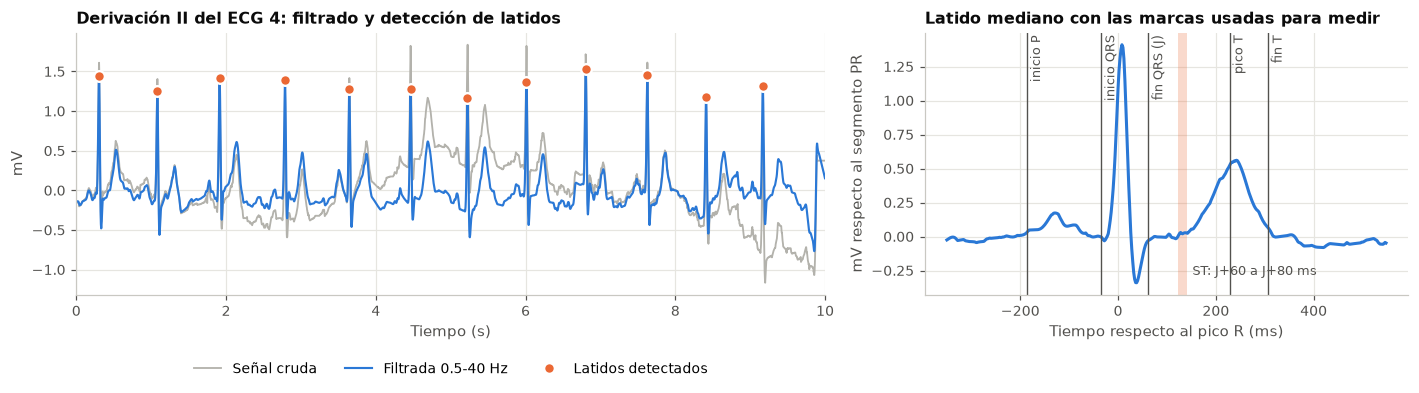

Latidos detectados: 12 en 10 s | PR: 152 ms | QRS: 96 ms | QT: 340 ms


In [7]:
is_normal_sinus = codes.apply(lambda d: set(d) <= {"NORM", "SR"})
example_id = meta.index[(meta.split == "train") & is_normal_sinus & meta.baseline_drift.notna()][0]
raw_example, clean_example, example_peaks, marks = beat_of(example_id)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), width_ratios=[1.55, 1])
seconds = np.arange(len(raw_example)) / FS
ax = axes[0]
ax.plot(seconds, raw_example[:, 1], color="#b3b2ac", linewidth=1.2, label="Señal cruda")
ax.plot(seconds, clean_example[:, 1], color=BLUE, linewidth=1.4, label="Filtrada 0.5-40 Hz")
tops = np.array([p - 25 + int(np.argmax(clean_example[p - 25: p + 25, 1])) for p in example_peaks])  # máximo local en II, solo para dibujar
ax.plot(tops / FS, clean_example[tops, 1], "o", color=ORANGE, markersize=7,
        markeredgecolor="white", markeredgewidth=1.5, label="Latidos detectados")
ax.set(xlim=(0, 10), xlabel="Tiempo (s)", ylabel="mV", title=f"Derivación II del ECG {example_id}: filtrado y detección de latidos")
ax.legend(ncols=3, loc="lower center", bbox_to_anchor=(0.5, -0.36))

ax = axes[1]
milliseconds = (np.arange(PRE + POST) - PRE) / FS * 1000.0
beat = marks["centered"][:, 1]
ax.plot(milliseconds, beat, color=BLUE)
ax.axvspan(milliseconds[marks["offset"] + 30], milliseconds[marks["offset"] + 40], color=ORANGE, alpha=0.25, linewidth=0)
labels = {"inicio P": int(marks["p_onset"]), "inicio QRS": marks["onset"], "fin QRS (J)": marks["offset"],
          "pico T": marks["t_peak"], "fin T": int(round(marks["t_end"]))}
top = beat.max() * 1.05
for text, index in labels.items():
    ax.axvline(milliseconds[index], color=MUTED, linewidth=0.9)
    ax.text(milliseconds[index] + 6, top, text, rotation=90, va="top", ha="left", fontsize=8.5, color=MUTED)
ax.text(milliseconds[marks["offset"] + 45], beat.min() * 0.9, "ST: J+60 a J+80 ms", fontsize=8.5, color=MUTED, va="bottom")
ax.set(xlabel="Tiempo respecto al pico R (ms)", ylabel="mV respecto al segmento PR", title="Latido mediano con las marcas usadas para medir")
plt.tight_layout()
plt.show()
print(f"Latidos detectados: {len(example_peaks)} en 10 s | PR: {(marks['onset'] - marks['p_onset']) / FS * 1000:.0f} ms | "
      f"QRS: {(marks['offset'] - marks['onset']) / FS * 1000:.0f} ms | QT: {(marks['t_end'] - marks['onset']) / FS * 1000:.0f} ms")

En el panel izquierdo, la señal cruda (gris) sube y baja lentamente por la respiración y el movimiento del paciente. Después del filtro (azul) queda centrada en cero y los picos de cada latido conservan su forma: el filtro quita la deriva sin alterar el latido.

En el panel derecho vemos el latido típico del paciente con las marcas que pone el algoritmo. El PR (152 ms), el QRS (96 ms) y el QT (340 ms) quedan en valores normales para un ECG que el cardiólogo anotó como normal, lo que indica que las marcas caen en el lugar correcto. La franja naranja es la ventana donde medimos el nivel del segmento ST, de 60 a 80 ms después del final del QRS. En este ECG la señal pasa por ahí casi en cero, como se espera en un corazón sano.

### Qué se mide en cada ECG

Con las marcas anteriores extraemos ocho familias de características. La mayoría se mide por derivación, porque cada derivación mira al corazón desde un ángulo distinto y las enfermedades se localizan: un infarto inferior se ve en II, III y aVF; uno anterior, en V1 a V4.

| Familia | Qué mide | Para qué sirve |
| --- | --- | --- |
| Ritmo | Frecuencia cardiaca, variabilidad de los intervalos RR, parecido de cada latido con el mediano | Bradicardia, taquicardia, arritmias, extrasístoles |
| Intervalos | Duración del QRS, intervalo QT, intervalo PR y tiempo del pico de la onda P al QRS | Bloqueos de conducción, QT largo |
| Onda P | Amplitud de la onda P e indicador de que no se encontró una onda P medible | Actividad auricular; en la fibrilación auricular no hay onda P organizada |
| QRS por derivación | Altura de la R, profundidad de la S y de la Q, área neta | Hipertrofia, infartos antiguos (ondas Q), eje eléctrico |
| Repolarización por derivación | Nivel del ST y amplitud de la onda T | Isquemia y cambios ST-T |
| Estadísticos por derivación | Desviación estándar, rango pico a pico, curtosis | Resúmenes sin delinear, como los del Avance 1 |
| Espectro | Reparto de la potencia en 0.5-5, 5-15 y 15-40 Hz, entropía y centroide | Forma global de la señal |
| Calidad | Potencia por debajo de 0.5 Hz, por encima de 40 Hz y en 48-52 Hz; indicador de medición fallida | Reconocer registros poco fiables |

La conducción entre aurículas y ventrículos se mide de dos formas porque fallan en casos distintos. `pr_ms` es el intervalo PR clínico (del inicio de la onda P al QRS) y queda vacío cuando no hay una onda P clara. `pq_peak_ms` va del punto de mayor amplitud antes del QRS al inicio del QRS y siempre da un número. La comprobación de más abajo dice para qué sirve cada una.

El archivo donde se guardan las características lleva en su nombre una huella del código de extracción: si el código cambia, no se reutiliza por error un archivo anterior.

In [8]:
def spectral_features(raw: np.ndarray) -> dict[str, float]:
    freqs, power = welch(raw[:, INDEPENDENT], fs=FS, nperseg=1024, axis=0)
    power = power.mean(axis=1)

    def band(low: float, high: float) -> float:
        return float(power[(freqs > low) & (freqs <= high)].sum())

    total, useful = band(0, 100), band(0.5, 40)
    in_band = (freqs > 0.5) & (freqs <= 40)
    share = power[in_band] / useful
    return {
        "noise_drift_frac": band(0, 0.5) / total, "noise_hf_frac": band(40, 100) / total,
        "noise_powerline_frac": band(48, 52) / total,
        "sp_low_rel": band(0.5, 5) / useful, "sp_mid_rel": band(5, 15) / useful, "sp_high_rel": band(15, 40) / useful,
        "sp_entropy": float(-(share * np.log(share + 1e-12)).sum() / np.log(len(share))),
        "sp_centroid_hz": float((freqs[in_band] * share).sum()),
    }


def extract_features(record_path: Path) -> dict:
    raw = read_ecg(record_path)
    feats = {"status": "ok", "implausible": "", "flat_leads": float((np.ptp(raw, axis=0) == 0).sum())}
    if feats["flat_leads"] > 0:
        feats["status"] = "derivacion_plana"
        return feats
    clean = sosfiltfilt(SOS_CLEAN, raw, axis=0)
    feats.update(spectral_features(raw))
    for j, lead in enumerate(LEADS):
        feats[f"std_{lead}"] = float(clean[:, j].std())
        feats[f"ptp_{lead}"] = float(np.ptp(clean[:, j]))
        feats[f"kurt_{lead}"] = float(stats.kurtosis(clean[:, j]))

    peaks = detect_r_peaks(clean)
    rr = np.diff(peaks) / FS * 1000.0
    feats["n_beats"] = float(len(peaks))
    template, feats["beat_similarity"] = median_beat(clean, peaks)
    if len(rr) < 2 or np.isnan(template).any():
        feats["status"] = "sin_latidos"
        return feats
    feats["rr_mean_ms"] = float(rr.mean())
    feats["rr_sdnn_ms"] = float(rr.std(ddof=1))
    feats["rr_rmssd_ms"] = float(np.sqrt(np.mean(np.diff(rr) ** 2)))
    feats["rr_range_rel"] = float((rr.max() - rr.min()) / rr.mean())
    feats["hr_bpm"] = float(60000.0 / rr.mean())

    m = delineate(template, rr.mean())
    onset, offset, centered, rms = m["onset"], m["offset"], m["centered"], m["rms"]
    feats["qrs_dur_ms"] = (offset - onset) / FS * 1000.0
    feats["qt_ms"] = (m["t_end"] - onset) / FS * 1000.0
    feats["pq_peak_ms"] = (onset - m["p_peak"]) / FS * 1000.0
    feats["p_rms_mv"] = float(rms[m["p_peak"]])
    feats["t_peak_rms_mv"] = float(rms[m["t_peak"]])
    feats["pr_ms"] = (onset - m["p_onset"]) / FS * 1000.0
    feats["p_amp_II"] = m["p_amp"] if np.isfinite(m["p_onset"]) else np.nan
    for j, lead in enumerate(LEADS):
        qrs = centered[onset: offset + 1, j]
        r_index = int(np.argmax(qrs))
        has_r = qrs.max() > 0
        feats[f"r_amp_{lead}"] = float(max(qrs.max(), 0.0))
        feats[f"s_depth_{lead}"] = float(max(-qrs.min(), 0.0))
        feats[f"q_depth_{lead}"] = float(max(-qrs[:r_index].min(), 0.0)) if has_r and r_index > 0 else 0.0
        feats[f"qrs_area_{lead}"] = float(qrs.sum() / FS * 1000.0)
        feats[f"st_{lead}"] = float(centered[offset + 30: offset + 40, j].mean())
        t_wave = centered[m["t_start"]: m["t_stop"], j]
        feats[f"t_amp_{lead}"] = float(t_wave[np.argmax(np.abs(t_wave))])

    # Un intervalo fisiológicamente imposible es una medición fallida, no un hallazgo: se deja como faltante
    failed = [k for k, (low, high) in PLAUSIBLE.items() if np.isfinite(feats[k]) and not low <= feats[k] <= high]
    for k in failed:
        feats[k] = np.nan
    if "pr_ms" in failed:
        feats["p_amp_II"] = np.nan
    feats["implausible"] = ",".join(failed)
    return feats


FAMILY_PREFIXES = {
    "Ritmo": ("hr_", "rr_", "n_beats", "beat_similarity"),
    "Intervalos": ("qrs_dur", "qrs_class", "qt_", "qtc_", "pq_", "pr_"),
    "Onda P": ("p_rms", "p_amp", "flag_no_p"),
    "QRS: amplitud y eje": ("r_amp", "s_depth", "q_depth", "qrs_area", "qrs_axis", "sokolow", "cornell", "r_frac",
                            "r_transition", "r_prog", "n_q_", "q_patho", "low_voltage", "axis_class"),
    "Repolarización (ST-T)": ("st_", "t_amp", "t_peak", "t_axis", "qrs_t_angle", "n_t_", "t_inverted"),
    "Estadísticos de la señal": ("std_", "ptp_", "kurt_"),
    "Espectro": ("sp_",),
    "Calidad": ("noise_", "flag_"),
}


def family(name: str) -> str:
    return next((f for f, prefixes in FAMILY_PREFIXES.items() if name.startswith(prefixes)), "Otra")

In [9]:
extraction_code = "".join(inspect.getsource(f) for f in (read_ecg, detect_r_peaks, median_beat, delineate, spectral_features, extract_features))
code_hash = hashlib.sha256((extraction_code + repr(PLAUSIBLE)).encode()).hexdigest()[:10]
CACHE = OUT / f"caracteristicas_primarias_{code_hash}.csv"
if not CACHE.exists():
    start = time.perf_counter()
    rows = joblib.Parallel(n_jobs=WORKERS)(joblib.delayed(extract_features)(DATA / record) for record in meta.filename_hr)
    pd.DataFrame(rows, index=meta.index).to_csv(CACHE, float_format="%.6g")
    print(f"Extracción de {len(rows):,} ECG: {time.perf_counter() - start:.0f} s "
          f"({1000 * (time.perf_counter() - start) / len(rows):.1f} ms por ECG)")
extracted = pd.read_csv(CACHE, index_col="ecg_id")
assert extracted.index.equals(meta.index)
quality = extracted[["status", "implausible", "flat_leads"]].copy()
quality["implausible"] = quality.implausible.fillna("")
primary = extracted.drop(columns=quality.columns).copy()
primary["flag_no_p_wave"] = primary.pr_ms.isna().astype(float)
primary["flag_medicion_fallida"] = (primary.qrs_dur_ms.isna() | primary.qt_ms.isna()).astype(float)

inventory = pd.Series({c: family(c) for c in primary.columns}).value_counts().rename("características").to_frame()
inventory["ejemplos"] = [", ".join([c for c in primary.columns if family(c) == f][:4]) for f in inventory.index]
display(inventory)
print(f"Tabla primaria: {primary.shape[0]:,} ECG x {primary.shape[1]} características | caché: {CACHE.name}")

,características,ejemplos
QRS: amplitud y eje,48,"r_amp_I, s_depth_I, q_depth_I, qrs_area_I"
Estadísticos de la señal,36,"std_I, ptp_I, kurt_I, std_II"
Repolarización (ST-T),25,"t_peak_rms_mv, st_I, t_amp_I, st_II"
Ritmo,7,"n_beats, beat_similarity, rr_mean_ms, rr_sdnn_ms"
Espectro,5,"sp_low_rel, sp_mid_rel, sp_high_rel, sp_entropy"
Calidad,4,"noise_drift_frac, noise_hf_frac, noise_powerli..."
Intervalos,4,"qrs_dur_ms, qt_ms, pq_peak_ms, pr_ms"
Onda P,3,"p_rms_mv, p_amp_II, flag_no_p_wave"


Tabla primaria: 21,799 ECG x 132 características | caché: caracteristicas_primarias_ee39c8f6f7.csv


Cada ECG queda descrito por 132 características primarias en lugar de 60,000 muestras. Las familias más grandes son las que se miden por derivación: QRS (48), estadísticos (36) y repolarización (25).

### Calidad de la extracción

Antes de usar las características hay que saber en cuántos ECG falló la medición y si las fallas dependen de la enfermedad. Si dependieran, imputar sin más escondería información.

In [10]:
display(quality.status.value_counts().rename("ECG").to_frame().T)
implausible = quality.implausible[quality.implausible != ""].str.split(",").explode().value_counts()
display(implausible.rename("intervalos fuera del rango plausible, convertidos en faltantes").to_frame().T)

key_measures = ["hr_bpm", "qrs_dur_ms", "qt_ms", "pr_ms", "st_V5", "t_amp_V5"]
delineated = quality.status == "ok"
missing_by_class = pd.DataFrame({"todos": 100 * primary.loc[delineated, key_measures].isna().mean(),
                                 **{c: 100 * primary.loc[delineated & (meta[c] == 1), key_measures].isna().mean() for c in SUPERCLASSES}})
display(missing_by_class.round(2).rename_axis("% de faltantes por superclase (ECG delineados)"))

failed = (primary.flag_medicion_fallida == 1) & labeled
print(f"ECG con etiqueta y medición fallida (sin QRS o sin QT válidos): {int(failed.sum())} ({100 * failed.sum() / labeled.sum():.2f}%) | "
      f"con cardiopatía entre ellos: {100 * meta.target[failed].mean():.1f}% | en el resto: {100 * meta.target[labeled & ~failed].mean():.1f}%")
no_p = (primary.flag_no_p_wave == 1) & labeled & delineated
print(f"ECG con etiqueta sin onda P medible: {int(no_p.sum())} ({100 * no_p.sum() / (labeled & delineated).sum():.1f}%) | "
      f"con cardiopatía entre ellos: {100 * meta.target[no_p].mean():.1f}% | en el resto: {100 * meta.target[labeled & delineated & ~no_p].mean():.1f}%")

eligible = quality.status != "derivacion_plana"
supervised = eligible & labeled
funnel = pd.DataFrame({"ECG": [len(meta), int(eligible.sum()), int(supervised.sum())], "ECG en el Avance 1": [21799, 21798, 21387]},
                      index=["Metadatos", "Señales elegibles (sin derivación plana)", "Vista supervisada (con superclase diagnóstica)"])
display(funnel)

status,ok,sin_latidos,derivacion_plana
ECG,21790,8,1


implausible,qrs_dur_ms,pr_ms,qt_ms
"intervalos fuera del rango plausible, convertidos en faltantes",159,18,3


,todos,NORM,MI,STTC,CD,HYP
% de faltantes por superclase (ECG delineados),,,,,,
hr_bpm,0.00,0.00,0.00,0.00,0.00,0.00
qrs_dur_ms,0.73,0.03,0.49,0.08,2.12,0.64
qt_ms,0.07,0.02,0.04,0.06,0.08,0.04
pr_ms,18.04,11.07,22.13,26.19,22.24,19.25
st_V5,0.00,0.00,0.00,0.00,0.00,0.00
t_amp_V5,0.00,0.00,0.00,0.00,0.00,0.00


ECG con etiqueta y medición fallida (sin QRS o sin QT válidos): 128 (0.60%) | con cardiopatía entre ellos: 96.1% | en el resto: 57.4%
ECG con etiqueta sin onda P medible: 3678 (17.2%) | con cardiopatía entre ellos: 72.6% | en el resto: 54.5%


,ECG,ECG en el Avance 1
Metadatos,21799,21799
Señales elegibles (sin derivación plana),21798,21798
Vista supervisada (con superclase diagnóstica),21387,21387


La extracción se completó en 21,790 de los 21,799 ECG. En 8 no hay latidos suficientes para formar el latido mediano y 1 tiene una derivación plana, el mismo que el Avance 1 excluyó. La vista supervisada queda en 21,387 ECG, idéntica a la del Avance 1.

Las fallas, en cambio, no son aleatorias:

- Intervalos imposibles. El filtro de plausibilidad convirtió en faltantes 159 QRS, 18 PR y 3 QT. El QRS falta en el 0.03% de los ECG `NORM` y en el 2.12% de los `CD`: el delineador falla justo donde el QRS es más anormal. De los 128 ECG con etiqueta y medición fallida, el 96.1% tiene cardiopatía, contra el 57.4% del resto.
- Onda P. No se encontró una onda P medible en el 18.0% de los ECG delineados: 11.1% en `NORM`, pero 26.2% en `STTC`, 22.2% en `CD` y 22.1% en `MI`. Entre los ECG sin onda P el 72.6% tiene cardiopatía, contra el 54.5% del resto.

Por eso creamos dos indicadores en lugar de solo imputar. `flag_no_p_wave` marca los ECG sin onda P medible y `flag_medicion_fallida` los que quedaron sin un QRS o un QT válidos. Un valor imposible no se usa como número, pero el hecho de que la medición falló sí se conserva.

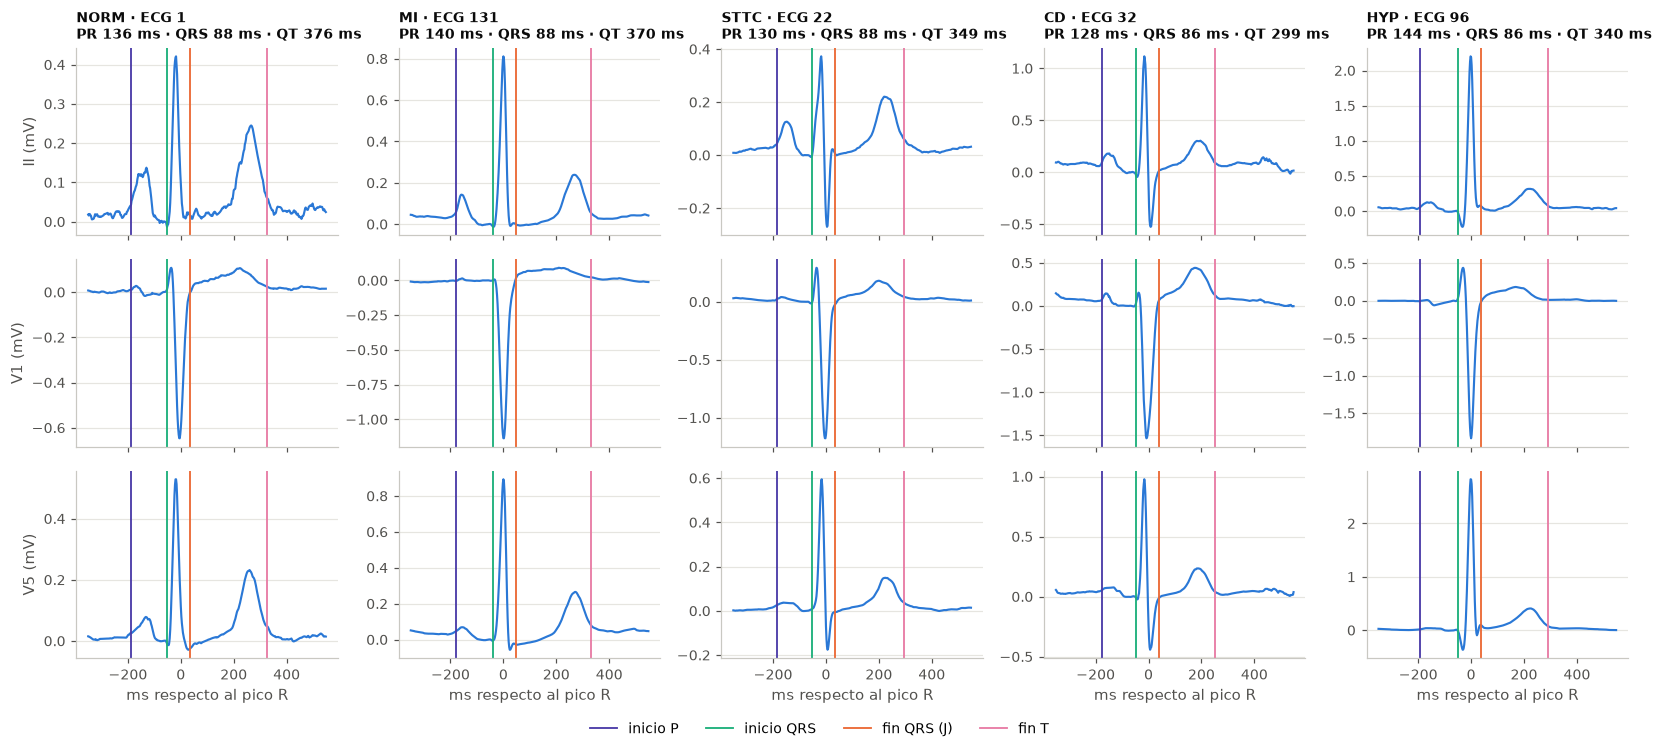

In [11]:
MARKS = {"inicio P": ("p_onset", VIOLET), "inicio QRS": ("onset", AQUA), "fin QRS (J)": ("offset", ORANGE), "fin T": ("t_end", MAGENTA)}
shown_leads = ["II", "V1", "V5"]
class_examples = {c: meta.index[(meta.split == "train") & (meta.dx_group == c) & delineated & (quality.implausible == "")][0] for c in SUPERCLASSES}
fig, axes = plt.subplots(len(shown_leads), len(SUPERCLASSES), figsize=(15, 6.6), sharex=True)
for column, (name, ecg_id) in enumerate(class_examples.items()):
    _, _, _, m = beat_of(ecg_id)
    for row, lead in enumerate(shown_leads):
        ax = axes[row, column]
        ax.plot(milliseconds, m["centered"][:, LEADS.index(lead)], color=BLUE, linewidth=1.4)
        for label, (key, color) in MARKS.items():
            if np.isfinite(m[key]):
                ax.axvline(milliseconds[int(round(m[key]))], color=color, linewidth=1.2, label=label)
        ax.set_ylabel(f"{lead} (mV)" if column == 0 else "")
        ax.grid(axis="x", visible=False)
    pr = primary.pr_ms[ecg_id]
    axes[0, column].set_title(f"{name} · ECG {ecg_id}\nPR {'no medible' if np.isnan(pr) else f'{pr:.0f} ms'} · QRS {primary.qrs_dur_ms[ecg_id]:.0f} ms · QT {primary.qt_ms[ecg_id]:.0f} ms", fontsize=9)
    axes[-1, column].set_xlabel("ms respecto al pico R")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=4, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
plt.show()

La figura muestra el latido mediano del primer ECG de entrenamiento de cada superclase (con una sola superclase) en II, V1 y V5. Las marcas caen donde las pondría un lector de ECG: el inicio de la P al comenzar la onda P, el inicio del QRS antes de la primera deflexión, el punto J cuando termina la S y el fin de la T cuando vuelve a la línea base. En los cinco ejemplos el PR va de 128 a 144 ms y el QRS de 86 a 88 ms. En el ejemplo de `HYP` la R en V5 supera 2.5 mV, la más alta de los cinco, como corresponde a una hipertrofia.

Esta revisión visual no sustituye una validación clínica. La comprobación que sigue es más exigente porque usa todos los ECG.

### Comprobación contra las lecturas del cardiólogo

Las lecturas del cardiólogo, que descartamos como predictores, sirven ahora de referencia independiente: si la frecuencia calculada es correcta, los ECG anotados como bradicardia deben quedar por debajo de 60 latidos por minuto; si la duración del QRS es correcta, los bloqueos completos de rama deben superar 120 ms. La columna `AUROC_separación` resume cada comparación: 1.0 significa que la medición separa por completo los ECG anotados de los normales.

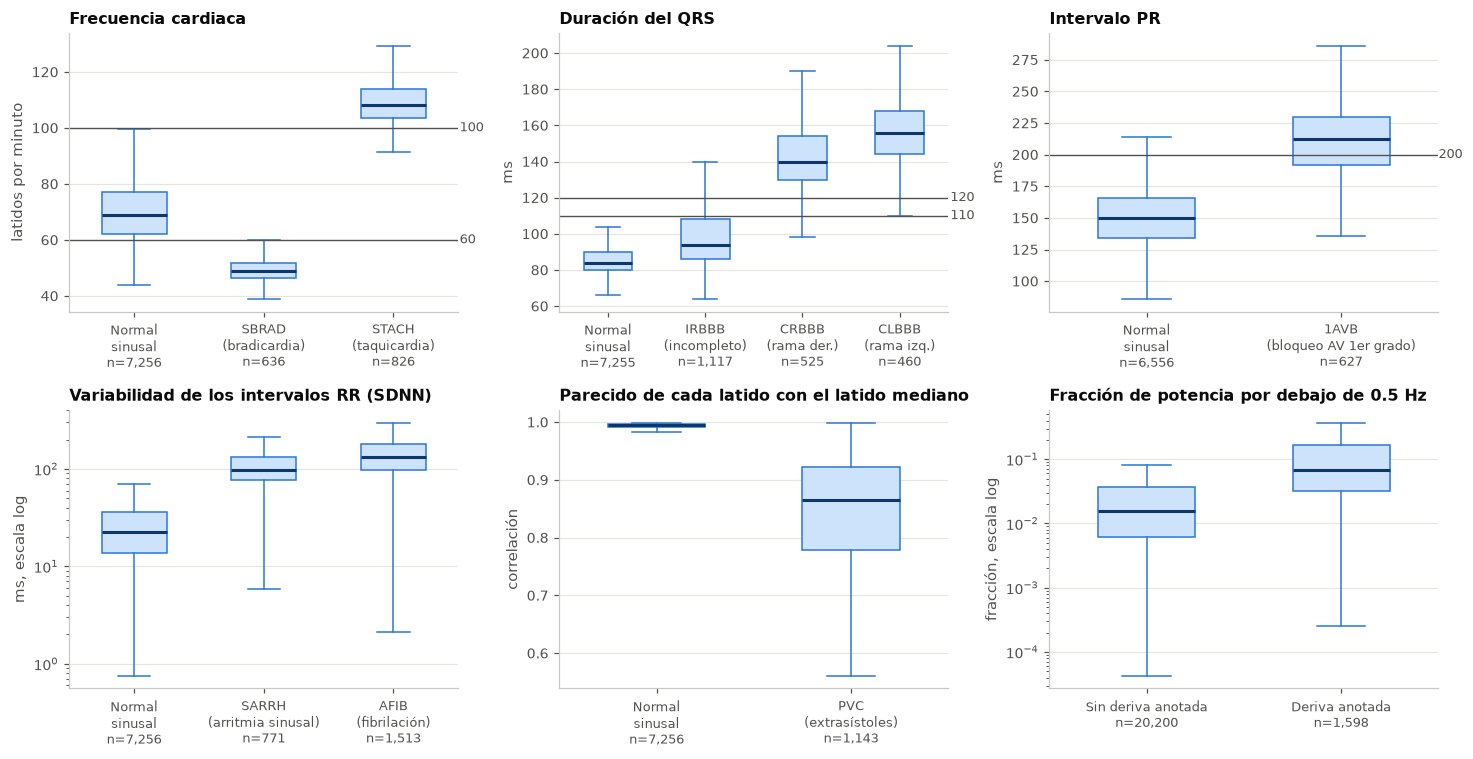

n_anotados  normal_sinusal  anotados  AUROC_separación
característica   anotación del cardiólogo                                                        
hr_bpm           SBRAD                            637          68.902    48.758             0.967
                 STACH                            826          68.902   108.232             0.998
qrs_dur_ms       CRBBB                            541          84.000   140.000             0.991
                 CLBBB                            536          84.000   156.000             0.999
pr_ms            1AVB                             793         150.000   212.000             0.879
pq_peak_ms       1AVB                             793         106.000   182.000             0.964
flag_no_p_wave   AFIB                            1514           0.097     0.907             0.905
rr_sdnn_ms       AFIB                            1514          22.290   131.591             0.967
beat_similarity  PVC                             1143           0.995     0.865             0.956
noise_drift_frac baseline_drift anotada          1598           0.017     0.067             0.807

Las columnas normal_sinusal y anotados muestran la mediana de cada grupo; en los indicadores 0/1, la proporción de unos.
ECG con 1AVB anotado y PR no medible: 20.9%


In [12]:
def has_code(code: str) -> pd.Series:
    return codes.apply(lambda d: code in d)


def box_groups(ax, groups: dict[str, pd.Series], title: str, ylabel: str, reference: tuple = (), log: bool = False) -> None:
    values = [g.dropna().to_numpy() for g in groups.values()]
    labels = [f"{name}\nn={len(v):,}" for name, v in zip(groups, values)]
    ax.boxplot(values, tick_labels=labels, widths=0.5, showfliers=False, patch_artist=True,
               boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE}, medianprops={"color": "#0d366b", "linewidth": 2},
               whiskerprops={"color": BLUE}, capprops={"color": BLUE})
    for level in reference:
        ax.axhline(level, color=MUTED, linewidth=0.9)
        ax.text(len(values) + 0.48, level, f" {level:g}", va="center", ha="left", fontsize=8.5, color=MUTED)
    if log:
        ax.set_yscale("log")
    ax.set(title=title, ylabel=ylabel)
    ax.tick_params(axis="x", labelsize=8.5)
    ax.grid(axis="x", visible=False)


drift_noted = meta.baseline_drift.notna()
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7))
box_groups(axes[0, 0], {"Normal\nsinusal": primary.hr_bpm[is_normal_sinus], "SBRAD\n(bradicardia)": primary.hr_bpm[has_code("SBRAD")],
                        "STACH\n(taquicardia)": primary.hr_bpm[has_code("STACH")]},
           "Frecuencia cardiaca", "latidos por minuto", reference=(60, 100))
box_groups(axes[0, 1], {"Normal\nsinusal": primary.qrs_dur_ms[is_normal_sinus], "IRBBB\n(incompleto)": primary.qrs_dur_ms[has_code("IRBBB")],
                        "CRBBB\n(rama der.)": primary.qrs_dur_ms[has_code("CRBBB")], "CLBBB\n(rama izq.)": primary.qrs_dur_ms[has_code("CLBBB")]},
           "Duración del QRS", "ms", reference=(110, 120))
box_groups(axes[0, 2], {"Normal\nsinusal": primary.pr_ms[is_normal_sinus], "1AVB\n(bloqueo AV 1er grado)": primary.pr_ms[has_code("1AVB")]},
           "Intervalo PR", "ms", reference=(200,))
box_groups(axes[1, 0], {"Normal\nsinusal": primary.rr_sdnn_ms[is_normal_sinus], "SARRH\n(arritmia sinusal)": primary.rr_sdnn_ms[has_code("SARRH")],
                        "AFIB\n(fibrilación)": primary.rr_sdnn_ms[has_code("AFIB")]},
           "Variabilidad de los intervalos RR (SDNN)", "ms, escala log", log=True)
box_groups(axes[1, 1], {"Normal\nsinusal": primary.beat_similarity[is_normal_sinus], "PVC\n(extrasístoles)": primary.beat_similarity[has_code("PVC")]},
           "Parecido de cada latido con el latido mediano", "correlación")
box_groups(axes[1, 2], {"Sin deriva anotada": primary.noise_drift_frac[~drift_noted], "Deriva anotada": primary.noise_drift_frac[drift_noted]},
           "Fracción de potencia por debajo de 0.5 Hz", "fracción, escala log", log=True)
plt.tight_layout()
plt.show()

checks = [
    ("hr_bpm", "SBRAD", has_code("SBRAD")), ("hr_bpm", "STACH", has_code("STACH")),
    ("qrs_dur_ms", "CRBBB", has_code("CRBBB")), ("qrs_dur_ms", "CLBBB", has_code("CLBBB")),
    ("pr_ms", "1AVB", has_code("1AVB")), ("pq_peak_ms", "1AVB", has_code("1AVB")),
    ("flag_no_p_wave", "AFIB", has_code("AFIB")), ("rr_sdnn_ms", "AFIB", has_code("AFIB")),
    ("beat_similarity", "PVC", has_code("PVC")), ("noise_drift_frac", "baseline_drift anotada", drift_noted),
]


def agreement(table: pd.DataFrame, items: list) -> pd.DataFrame:
    rows = []
    for feature, name, mask in items:
        reference = is_normal_sinus & ~mask
        values = pd.concat([table.loc[reference, feature], table.loc[mask, feature]])
        is_case = np.r_[np.zeros(reference.sum()), np.ones(mask.sum())]
        present = values.notna().to_numpy()
        auc = roc_auc_score(is_case[present], values[present])
        rows.append({"característica": feature, "anotación del cardiólogo": name, "n_anotados": int(mask.sum()),
                     "normal_sinusal": table.loc[reference, feature].agg("mean" if feature.startswith(("flag_", "low_")) else "median"),
                     "anotados": table.loc[mask, feature].agg("mean" if feature.startswith(("flag_", "low_")) else "median"),
                     "AUROC_separación": max(auc, 1 - auc)})
    return pd.DataFrame(rows).set_index(["característica", "anotación del cardiólogo"])


display(agreement(primary, checks))
print("Las columnas normal_sinusal y anotados muestran la mediana de cada grupo; en los indicadores 0/1, la proporción de unos.")
print(f"ECG con 1AVB anotado y PR no medible: {100 * primary.pr_ms[has_code('1AVB') & delineated].isna().mean():.1f}%")

Las mediciones coinciden con las anotaciones del cardiólogo:

- Frecuencia: la mediana baja de 68.9 a 48.8 latidos por minuto en la bradicardia (AUROC 0.967) y sube a 108.2 en la taquicardia (0.998).
- Duración del QRS: de 84 ms en los normales a 140 ms en el bloqueo completo de rama derecha (0.991) y 156 ms en el de rama izquierda (0.999).
- Conducción auriculoventricular: el PR pasa de 150 a 212 ms en el bloqueo de primer grado, por encima del umbral clínico de 200 ms (0.879), pero no se puede medir en el 20.9% de esos ECG. `pq_peak_ms` siempre se puede medir y separa mejor (de 106 a 182 ms, 0.964). Las dos se complementan: una está en unidades clínicas y la otra no falla.
- Ausencia de onda P: el indicador se activa en el 9.7% de los ECG normales sinusales y en el 90.7% de las fibrilaciones auriculares (0.905). Que el PR no se pueda medir es en sí una medición.
- Ritmo irregular: la variabilidad RR pasa de 22.3 a 131.6 ms en la fibrilación auricular (0.967) y el parecido entre latidos baja de 0.995 a 0.865 cuando hay extrasístoles (0.956).
- Calidad: la fracción de potencia por debajo de 0.5 Hz pasa de 0.017 a 0.067 en los registros con deriva de la línea base anotada (0.807).

Con esto consideramos válidas las características primarias para construir sobre ellas.

## 5. Características derivadas con criterio clínico

Generamos características nuevas combinando las existentes. Cada una reproduce un índice que la cardiología ya usa:

| Característica | Cómo se calcula | Razón clínica |
| --- | --- | --- |
| `sokolow_lyon_mv` | S en V1 + la mayor R entre V5 y V6 | Criterio de voltaje para hipertrofia ventricular izquierda (sospecha desde 3.5 mV) |
| `cornell_mv`, `cornell_product_mvms` | R en aVL + S en V3; ese voltaje por la duración del QRS | Segundo criterio de hipertrofia; el producto añade que el QRS se ensancha |
| `qtc_bazett_ms`, `qtc_fridericia_ms` | QT / √RR y QT / ∛RR | El QT se acorta al subir la frecuencia; sin corregir no es comparable entre pacientes |
| `qrs_axis_deg`, `t_axis_deg` | Ángulo a partir del área neta del QRS (o de la amplitud de la T) en I y aVF | Dirección media de la despolarización y de la repolarización |
| `qrs_t_angle_deg` | Diferencia entre los dos ejes (0 a 180°) | En un corazón sano ambos apuntan casi al mismo lado |
| `st_elev_*_mv`, `st_dep_*_mv` | Mayor elevación y mayor depresión del ST en cada territorio: anterior (V1-V4), inferior (II, III, aVF) y lateral (I, aVL, V5, V6) | Territorios de las arterias coronarias |
| `st_min_mv`, `st_max_mv` | Mayor descenso y mayor elevación del ST en todo el ECG (sin aVR) | La isquemia se manifiesta en la derivación más afectada |
| `n_t_inverted` | Derivaciones entre I, II, V3-V6 con T menor de -0.1 mV | En un adulto la T debe ser positiva en esas derivaciones |
| `n_q_pathologic` | Derivaciones con Q de al menos 25% de la R y 0.1 mV | Huella de un infarto antiguo |
| `r_frac_V1`, `r_transition_lead`, `r_prog_slope_mv` | R / (R + S) en V1; primera precordial donde la R supera a la S; pendiente de la altura de la R de V1 a V4 | Progresión de la onda R de V1 a V6 |
| `low_voltage_limb` | QRS menor de 0.5 mV en las seis derivaciones de extremidades | Bajo voltaje |

El ST de cada territorio se resume con el máximo y el mínimo, no con la media. La media del ST en II, III y aVF es algebraicamente el ST en aVF (porque III = II - I y aVF = II - I/2), así que sería una columna repetida; lo comprobamos más abajo.

Dejamos fuera a propósito las interacciones con metadatos (por ejemplo, el índice de Cornell dividido entre el umbral de cada sexo), porque el conjunto principal solo usa la señal.

In [13]:
features = primary.copy()
measured = (quality.status == "ok")
rr_seconds = features.rr_mean_ms / 1000.0

# Criterios de voltaje para hipertrofia ventricular izquierda
features["sokolow_lyon_mv"] = features.s_depth_V1 + features[["r_amp_V5", "r_amp_V6"]].max(axis=1)
features["cornell_mv"] = features.r_amp_aVL + features.s_depth_V3
features["cornell_product_mvms"] = features.cornell_mv * features.qrs_dur_ms

# QT corregido por frecuencia cardiaca
features["qtc_bazett_ms"] = features.qt_ms / np.sqrt(rr_seconds)
features["qtc_fridericia_ms"] = features.qt_ms / np.cbrt(rr_seconds)

# Ejes eléctricos en el plano frontal y ángulo entre despolarización y repolarización
features["qrs_axis_deg"] = np.degrees(np.arctan2(2 * features.qrs_area_aVF, np.sqrt(3) * features.qrs_area_I))
features["t_axis_deg"] = np.degrees(np.arctan2(2 * features.t_amp_aVF, np.sqrt(3) * features.t_amp_I))
gap = (features.qrs_axis_deg - features.t_axis_deg).abs()
features["qrs_t_angle_deg"] = gap.where(gap <= 180, 360 - gap)

# Segmento ST por territorio coronario: mayor elevación y mayor depresión de cada uno
TERRITORIES = {"anterior": ["V1", "V2", "V3", "V4"], "inferior": ["II", "III", "aVF"], "lateral": ["I", "aVL", "V5", "V6"]}
st = features[[f"st_{lead}" for lead in LEADS]].set_axis(LEADS, axis=1)
for territory, leads in TERRITORIES.items():
    features[f"st_elev_{territory}_mv"] = st[leads].max(axis=1)
    features[f"st_dep_{territory}_mv"] = st[leads].min(axis=1)
features["st_min_mv"] = st.drop(columns="aVR").min(axis=1)
features["st_max_mv"] = st.drop(columns="aVR").max(axis=1)

# Conteos de hallazgos por derivación
upright = ["I", "II", "V3", "V4", "V5", "V6"]  # derivaciones donde la onda T de un adulto debe ser positiva
features["n_t_inverted"] = (features[[f"t_amp_{lead}" for lead in upright]] < -0.1).sum(axis=1).where(measured)
q_leads = ["I", "II", "aVL", "aVF", "V2", "V3", "V4", "V5", "V6"]
q_depth = features[[f"q_depth_{lead}" for lead in q_leads]].to_numpy()
r_height = features[[f"r_amp_{lead}" for lead in q_leads]].to_numpy()
features["n_q_pathologic"] = pd.Series(((q_depth >= 0.25 * r_height) & (q_depth >= 0.1)).sum(axis=1), index=features.index).where(measured)

# Progresión de la onda R en las precordiales
precordial = ["V1", "V2", "V3", "V4", "V5", "V6"]
r_share = np.stack([features[f"r_amp_{lead}"] / (features[f"r_amp_{lead}"] + features[f"s_depth_{lead}"] + 1e-9) for lead in precordial], axis=1)
features["r_frac_V1"] = r_share[:, 0]
dominant = r_share >= 0.5
features["r_transition_lead"] = pd.Series(np.where(dominant.any(axis=1), dominant.argmax(axis=1) + 1, 7), index=features.index).where(measured)
features["r_prog_slope_mv"] = (-1.5 * features.r_amp_V1 - 0.5 * features.r_amp_V2 + 0.5 * features.r_amp_V3 + 1.5 * features.r_amp_V4) / 5

# Bajo voltaje en el plano frontal
limb = ["I", "II", "III", "aVR", "aVL", "aVF"]
qrs_height = pd.concat([(features[f"r_amp_{lead}"] + features[f"s_depth_{lead}"]).rename(lead) for lead in limb], axis=1)
features["low_voltage_limb"] = (qrs_height.max(axis=1) < 0.5).astype(float).where(measured)

derived = [c for c in features.columns if c not in primary.columns]
print(f"Características derivadas: {len(derived)} | total: {features.shape[1]}")
print(", ".join(derived))

Características derivadas: 22 | total: 154
sokolow_lyon_mv, cornell_mv, cornell_product_mvms, qtc_bazett_ms, qtc_fridericia_ms, qrs_axis_deg, t_axis_deg, qrs_t_angle_deg, st_elev_anterior_mv, st_dep_anterior_mv, st_elev_inferior_mv, st_dep_inferior_mv, st_elev_lateral_mv, st_dep_lateral_mv, st_min_mv, st_max_mv, n_t_inverted, n_q_pathologic, r_frac_V1, r_transition_lead, r_prog_slope_mv, low_voltage_limb


Son 22 características derivadas y 154 en total. Repetimos la comprobación de la sección 4 con la anotación que corresponde a cada índice (por ejemplo, Sokolow-Lyon contra el código de hipertrofia `LVH`). Además comparamos el eje calculado con el que anotó el cardiólogo y comprobamos numéricamente la relación entre las derivaciones de extremidades.

In [14]:
derived_checks = [
    ("sokolow_lyon_mv", "LVH", has_code("LVH")), ("cornell_product_mvms", "LVH", has_code("LVH")),
    ("qtc_bazett_ms", "LNGQT", has_code("LNGQT")), ("qt_ms", "LNGQT", has_code("LNGQT")),
    ("st_min_mv", "STD_", has_code("STD_")), ("st_dep_lateral_mv", "STD_", has_code("STD_")),
    ("n_t_inverted", "INVT", has_code("INVT")), ("n_q_pathologic", "QWAVE", has_code("QWAVE")),
    ("r_transition_lead", "ASMI", has_code("ASMI")), ("r_prog_slope_mv", "ASMI", has_code("ASMI")),
    ("qrs_t_angle_deg", "ISC_", has_code("ISC_")), ("low_voltage_limb", "LVOLT", has_code("LVOLT")),
]
display(agreement(features, derived_checks))

computed_axis = pd.cut(features.qrs_axis_deg, [-180, -90, -30, 90, 180], labels=["extrema (-180 a -90)", "izquierda (-90 a -30)", "normal (-30 a 90)", "derecha (90 a 180)"], include_lowest=True)
axis_table = pd.crosstab(meta.heart_axis, computed_axis).loc[["MID", "LAD", "ALAD", "RAD", "ARAD"]]
axis_table.index = ["MID: normal", "LAD: izquierda (-30 a +30 en la convención alemana)", "ALAD: izquierda marcada", "RAD: derecha", "ARAD: derecha marcada"]
axis_table.index.name, axis_table.columns.name = "Eje anotado por el cardiólogo", "Eje calculado de la señal"
display(axis_table)

x = read_ecg(DATA / meta.filename_hr[example_id])
identity = pd.Series({
    "III - (II - I)": np.abs(x[:, 2] - (x[:, 1] - x[:, 0])).max(),
    "aVR + (I + II)/2": np.abs(x[:, 3] + (x[:, 0] + x[:, 1]) / 2).max(),
    "aVL - (I - II/2)": np.abs(x[:, 4] - (x[:, 0] - x[:, 1] / 2)).max(),
    "aVF - (II - I/2)": np.abs(x[:, 5] - (x[:, 1] - x[:, 0] / 2)).max(),
}, name=f"diferencia máxima en mV (ECG {example_id})").to_frame()
display(identity)
st_inferior_mean = st[TERRITORIES["inferior"]].mean(axis=1)
print(f"Media del ST en II, III y aVF contra el ST en aVF: diferencia máxima en todo el dataset {(st_inferior_mean - st.aVF).abs().max():.2e} mV, "
      f"correlación {st_inferior_mean.corr(st.aVF):.4f}")

,,n_anotados,normal_sinusal,anotados,AUROC_separación
característica,anotación del cardiólogo,,,,
sokolow_lyon_mv,LVH,2132,2.127e+00,3.481,0.884
cornell_product_mvms,LVH,2132,9.786e+01,176.749,0.802
qtc_bazett_ms,LNGQT,117,3.934e+02,461.396,0.958
qt_ms,LNGQT,117,3.661e+02,411.410,0.793
st_min_mv,STD_,1009,-1.109e-02,-0.080,0.976
st_dep_lateral_mv,STD_,1009,-5.291e-04,-0.075,0.972
n_t_inverted,INVT,294,0.000e+00,2.000,0.886
n_q_pathologic,QWAVE,548,0.000e+00,1.000,0.819
r_transition_lead,ASMI,2357,3.000e+00,5.000,0.757


Eje calculado de la señal,extrema (-180 a -90),izquierda (-90 a -30),normal (-30 a 90),derecha (90 a 180)
Eje anotado por el cardiólogo,,,,
MID: normal,2,17,7500,165
LAD: izquierda (-30 a +30 en la convención alemana),40,1032,2681,9
ALAD: izquierda marcada,70,1192,119,1
RAD: derecha,5,0,15,201
ARAD: derecha marcada,46,9,1,66


,diferencia máxima en mV (ECG 4)
III - (II - I),0.001
aVR + (I + II)/2,0.001
aVL - (I - II/2),0.002
aVF - (II - I/2),0.002


Media del ST en II, III y aVF contra el ST en aVF: diferencia máxima en todo el dataset 3.13e-02 mV, correlación 0.9991


Después del análisis concluimos que:

- Las combinaciones añaden información que sus partes no tienen. El QT sin corregir separa los ECG con QT largo con AUROC 0.793; el QT corregido de Bazett llega a 0.958.
- Los índices de voltaje responden a la hipertrofia: Sokolow-Lyon pasa de 2.13 a 3.48 mV (0.884), justo en el umbral clínico de 3.5 mV, y el producto de Cornell de 97.9 a 176.7 (0.802).
- Repolarización: el mayor descenso del ST separa los ECG con depresión del ST con AUROC 0.976 y su versión lateral con 0.972; el ángulo QRS-T pasa de unos 20° a 132° en la isquemia (0.911) y el conteo de ondas T invertidas va de 0 a 2 (0.886).
- Infarto: el conteo de ondas Q patológicas va de 0 a 1 (0.819). En el infarto anteroseptal la transición de la onda R se retrasa de V3 a V5 (0.757) y la pendiente de la R de V1 a V4 cae de 0.37 a 0.10 mV por derivación (0.842): la pendiente describe mejor la pérdida de progresión que la derivación de transición.
- `low_voltage_limb` es la más débil (0.609): se activa en el 0.7% de los normales y solo en el 22.5% de los ECG con el código `LVOLT`.
- Eje eléctrico: el 97.6% de los ECG anotados con eje normal (7,500 de 7,684) cae en el intervalo normal calculado, el 86.3% de los de desviación izquierda marcada cae en izquierda y el 91.0% de los de desviación derecha en derecha. El grupo `LAD` se reparte entre normal e izquierda porque la nomenclatura alemana de los informes llama "tipo izquierdo" al intervalo de -30° a +30°, que la convención internacional considera normal.
- Las derivaciones de extremidades no son independientes. En la señal cruda, III = II - I y las tres aumentadas se obtienen de I y II con un error máximo de 0.002 mV, que es el redondeo del archivo. De las 12 derivaciones solo 8 llevan información propia. La consecuencia que anticipamos se confirma: la media del ST en II, III y aVF y el ST en aVF tienen una correlación de 0.9991 (difieren hasta 0.031 mV solo porque la mediana de los latidos se toma por derivación). Las características por derivación se construyeron completas a propósito; las secciones 11 y 12 miden esa redundancia y la eliminan con pruebas, no a mano.

### Perfil por tipo de cardiopatía

Si las características tienen sentido clínico, cada superclase debe mover características distintas. Tomamos los ECG de entrenamiento con una sola superclase y calculamos cuánto se desplaza su mediana respecto a los normales, en unidades de dispersión de los normales (rojo: más alto que en normales; azul: más bajo).

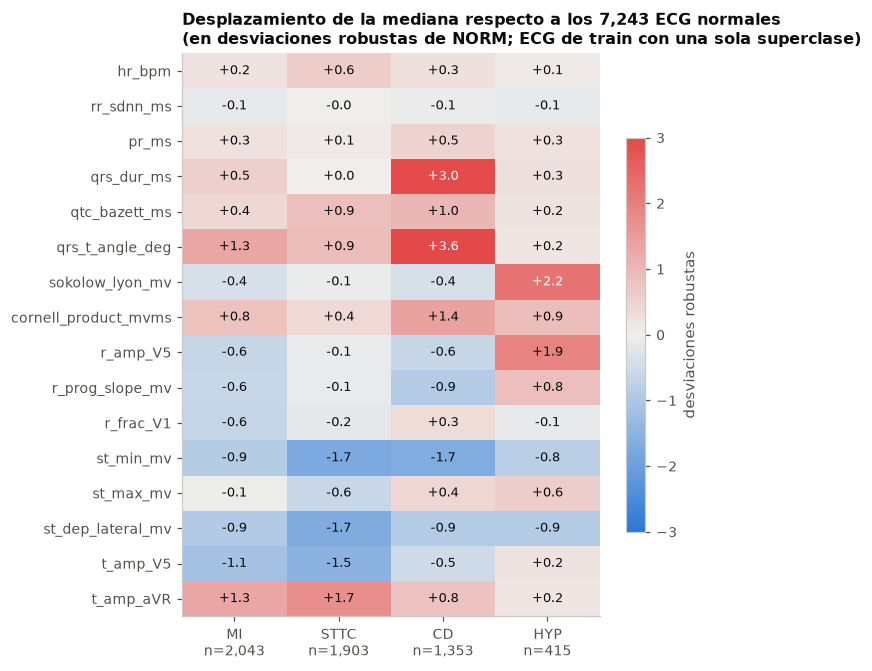

In [15]:
profile_features = ["hr_bpm", "rr_sdnn_ms", "pr_ms", "qrs_dur_ms", "qtc_bazett_ms", "qrs_t_angle_deg",
                    "sokolow_lyon_mv", "cornell_product_mvms", "r_amp_V5", "r_prog_slope_mv", "r_frac_V1",
                    "st_min_mv", "st_max_mv", "st_dep_lateral_mv", "t_amp_V5", "t_amp_aVR"]
train_single = (meta.split == "train") & meta.dx_group.isin(SUPERCLASSES) & supervised
normal_rows = train_single & (meta.dx_group == "NORM")
center = features.loc[normal_rows, profile_features].median()
spread = (features.loc[normal_rows, profile_features].quantile(0.75) - features.loc[normal_rows, profile_features].quantile(0.25)) / 1.349
shift = (features.loc[train_single, profile_features].groupby(meta.dx_group[train_single]).median() - center) / spread
shift = shift.loc[PATHOLOGY].T

fig, ax = plt.subplots(figsize=(6.6, 6.2))
image = ax.imshow(shift.to_numpy(), cmap=DIVERGING, vmin=-3, vmax=3, aspect="auto")
counts = meta.dx_group[train_single].value_counts()
ax.set_xticks(range(len(PATHOLOGY)), [f"{c}\nn={counts[c]:,}" for c in PATHOLOGY])
ax.set_yticks(range(len(profile_features)), profile_features)
for i in range(shift.shape[0]):
    for j in range(shift.shape[1]):
        value = shift.iat[i, j]
        ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=8.5, color="white" if abs(value) > 2 else INK)
ax.grid(False)
ax.set_title(f"Desplazamiento de la mediana respecto a los {counts['NORM']:,} ECG normales\n(en desviaciones robustas de NORM; ECG de train con una sola superclase)")
fig.colorbar(image, ax=ax, shrink=0.7, label="desviaciones robustas")
plt.tight_layout()
plt.show()

Cada enfermedad deja su propia huella. En `CD` se disparan la duración del QRS (+3.0) y el ángulo QRS-T (+3.6). En `HYP` suben Sokolow-Lyon (+2.2) y la R en V5 (+1.9). En `STTC` bajan el ST (-1.7) y la onda T en V5 (-1.5), y la T en aVR se vuelve positiva (+1.7). En `MI` cambian sobre todo el ángulo QRS-T (+1.3) y las ondas T, y cae la progresión de la R (-0.6).

Hay un detalle que importa para la selección: Sokolow-Lyon sube en la hipertrofia (+2.2) pero baja en el infarto y en los trastornos de conducción (-0.4). Como la clase "cardiopatía" junta a todos, esos efectos opuestos se pueden cancelar al comparar solo "normal contra cardiopatía". Por eso en la sección 11 medimos la relevancia de cada característica también frente a cada superclase.

### ¿Conviene normalizar el índice de Cornell por sexo?

El criterio de Cornell usa umbrales distintos en hombres (2.8 mV) y en mujeres (2.0 mV). La versión de Emiliano propuso dividir el índice entre el umbral de cada sexo, de modo que un valor mayor que 1 cumpla el criterio en ambos. Es una interacción con un metadato, así que antes de aceptarla comprobamos si separa mejor la hipertrofia anotada por el cardiólogo (`LVH`) que el índice sin normalizar.

In [16]:
female = meta.sex == 1  # PTB-XL: 0 = hombre, 1 = mujer
cornell_check = pd.DataFrame({
    "cornell_mv": features.cornell_mv,
    "cornell_entre_umbral_del_sexo": features.cornell_mv / np.where(female, 2.0, 2.8),
    "cornell_product_mvms": features.cornell_product_mvms,
    "sokolow_lyon_mv": features.sokolow_lyon_mv,
})
lvh = has_code("LVH")
display(agreement(cornell_check, [(c, "LVH", lvh) for c in cornell_check]))

over = cornell_check.cornell_entre_umbral_del_sexo > 1
by_sex = pd.DataFrame({
    "umbral_mV": {"hombre": 2.8, "mujer": 2.0},
    "normales_sobre_el_umbral_%": {s: 100 * over[is_normal_sinus & ~lvh & (female == f)].mean() for s, f in [("hombre", False), ("mujer", True)]},
    "LVH_sobre_el_umbral_%": {s: 100 * over[lvh & (female == f)].mean() for s, f in [("hombre", False), ("mujer", True)]},
    "ECG_con_LVH": {s: int((lvh & (female == f)).sum()) for s, f in [("hombre", False), ("mujer", True)]},
})
display(by_sex)

,,n_anotados,normal_sinusal,anotados,AUROC_separación
característica,anotación del cardiólogo,,,,
cornell_mv,LVH,2132,1.154,2.021,0.804
cornell_entre_umbral_del_sexo,LVH,2132,0.493,0.823,0.781
cornell_product_mvms,LVH,2132,97.865,176.749,0.802
sokolow_lyon_mv,LVH,2132,2.127,3.481,0.884


,umbral_mV,normales_sobre_el_umbral_%,LVH_sobre_el_umbral_%,ECG_con_LVH
hombre,2.8,0.520,22.451,1216
mujer,2.0,2.859,51.419,916


La normalización por sexo no mejora la separación. El índice sin normalizar separa los ECG con hipertrofia anotada con un AUROC de 0.804, y dividido entre el umbral de cada sexo, con 0.781.

La segunda tabla muestra por qué. Con su umbral propio de 2.0 mV, el criterio se cumple en el 2.9% de las mujeres normales y en el 51.4% de las que tienen hipertrofia; en los hombres, con 2.8 mV, en el 0.5% y en el 22.5%. El umbral de las mujeres detecta más casos, pero también marca a más mujeres sanas, y al juntar a todos los ECG el índice normalizado ordena peor.

Por eso no se incluye. Así además el sexo queda fuera de las características de la señal, como se decidió en la sección 3. Entre los índices de voltaje, Sokolow-Lyon sigue siendo el que mejor separa la hipertrofia (0.884).

### Una precaución para la población del proyecto: el segmento ST en jóvenes

El proyecto se dirige a estudiantes universitarios, y PTB-XL tiene pocos ECG de esa edad. Una elevación pequeña del segmento ST es frecuente en hombres jóvenes sanos, sobre todo en V2 y V3; por eso los criterios clínicos de infarto usan umbrales distintos según el sexo y la edad. Si nuestras características de ST la registran, en la población del proyecto se activarán en muchos ECG normales. Lo medimos en los ECG que el cardiólogo leyó como normales y en ritmo sinusal, por sexo y por edad.

In [17]:
normal_ecg = is_normal_sinus & supervised
st_leads = [f"st_{lead}" for lead in LEADS if lead != "aVR"]
st_view = pd.DataFrame({
    "sexo": np.where(meta.sex == 1, "mujer", "hombre"),
    "edad": pd.cut(meta.age, [0, 30, 45, 60, 200], right=False, labels=["< 30", "30-44", "45-59", "60 o más"]),
    "st_V2_mv": features.st_V2,
    "derivaciones_con_ST_elevado": (features[st_leads] >= 0.1).sum(axis=1),
})[normal_ecg]
st_by_group = st_view.groupby(["sexo", "edad"], observed=True).agg(
    ECG_normales=("st_V2_mv", "size"),
    ST_V2_mediana_mv=("st_V2_mv", "median"),
    ST_V2_elevado_pct=("st_V2_mv", lambda s: 100 * (s >= 0.1).mean()),
    derivaciones_con_ST_elevado_media=("derivaciones_con_ST_elevado", "mean"),
)
print("ST elevado: 0.1 mV o más entre 60 y 80 ms después del final del QRS. Solo ECG normales en ritmo sinusal.")
display(st_by_group)

ST elevado: 0.1 mV o más entre 60 y 80 ms después del final del QRS. Solo ECG normales en ritmo sinusal.


ECG_normales  ST_V2_mediana_mv  ST_V2_elevado_pct  derivaciones_con_ST_elevado_media
sexo   edad                                                                                          
hombre < 30               324             0.235             95.062                              3.250
       30-44              728             0.193             88.462                              2.662
       45-59             1118             0.149             79.159                              2.043
       60 o más          1098             0.124             64.390                              1.536
mujer  < 30               552             0.109             57.790                              1.029
       30-44              727             0.100             50.069                              0.842
       45-59             1294             0.091             41.731                              0.702
       60 o más          1411             0.087             39.263                              0.741

En los ECG normales, la elevación del ST es frecuente y depende mucho de la edad y del sexo:

- En los hombres menores de 30 años, el 95.1% tiene el ST de V2 en 0.1 mV o más (mediana de 0.235 mV), y en promedio 3.25 derivaciones superan ese nivel.
- En los hombres de 60 años o más, la proporción en V2 baja a 64.4%.
- En las mujeres es menor en todas las edades: 57.8% entre las menores de 30 años, con 1.03 derivaciones elevadas en promedio.

En PTB-XL esto pesa poco, porque los hombres menores de 30 años son 324 de los 7,252 ECG normales de la tabla (4.5%). En una población universitaria serán una parte grande de los ECG. Características como `st_max_mv` o `st_elev_anterior_mv` describen bien la isquemia en PTB-XL, pero en jóvenes sanos tomarán valores altos con frecuencia. Es un riesgo que pasa a la fase de modelado: los parámetros ajustados aquí no se pueden trasladar sin revisar esta diferencia.

## 6. Limpieza: valores faltantes y atípicos

- Faltantes. Aparecen cuando no se pudo delinear el latido, no hay una onda P medible o un intervalo salió del rango plausible. Imputamos la mediana de entrenamiento, que no se deja arrastrar por valores extremos, y los dos indicadores de la sección 4 conservan el hecho de que la medición faltó. Eliminar esas filas no es opción: en uso real el modelo tiene que responder para todos los ECG.
- Atípicos. Contamos qué fracción de cada característica queda fuera de las cercas de Tukey (1.5 veces el rango intercuartílico) y comparamos los máximos con el percentil 99.5. En un ECG los valores extremos tienen dos orígenes: una medición fallida o una enfermedad real. Por eso no se borran filas: se recortan los valores a los percentiles 0.5 y 99.5 de entrenamiento (winsorización). Un QRS muy ancho sigue siendo "muy ancho", pero un artefacto de 8 mV deja de dominar la media y la varianza.

In [18]:
rows = meta.index[supervised]
y = meta.target.loc[rows].astype(int)
split = meta.split.loc[rows]
train, val, test = split == "train", split == "val", split == "test"
patient = meta.patient_id.loc[rows]

X = features.loc[rows].copy()
CYCLIC_SOURCE = ["qrs_axis_deg", "t_axis_deg"]
COUNTS = ["n_t_inverted", "n_q_pathologic", "r_transition_lead"]
BINARY = ["low_voltage_limb", "flag_no_p_wave", "flag_medicion_fallida"]
continuous = [c for c in X.columns if c not in CYCLIC_SOURCE + COUNTS + BINARY]

missing = 100 * X.loc[train].isna().mean()
print(f"Vista supervisada: {len(X):,} ECG (train {train.sum():,}, val {val.sum():,}, test {test.sum():,}) x {X.shape[1]} características")
print(f"Columnas con algún faltante en train: {(missing > 0).sum()} de {X.shape[1]} | ECG de train con algún faltante: {int(X.loc[train].isna().any(axis=1).sum())}")
display(missing.sort_values(ascending=False).head(8).rename("faltantes en train (%)").to_frame().T)

imputer = SimpleImputer(strategy="median").set_output(transform="pandas").fit(X.loc[train])
X_imputed = imputer.transform(X)

quartile_1, quartile_3 = X_imputed.loc[train, continuous].quantile(0.25), X_imputed.loc[train, continuous].quantile(0.75)
fence = 1.5 * (quartile_3 - quartile_1)
outside = (X_imputed.loc[train, continuous] < quartile_1 - fence) | (X_imputed.loc[train, continuous] > quartile_3 + fence)
lower, upper = X_imputed.loc[train, continuous].quantile(0.005), X_imputed.loc[train, continuous].quantile(0.995)
X_clean = X_imputed.copy()
X_clean[continuous] = X_imputed[continuous].clip(lower, upper, axis=1)

outliers = pd.DataFrame({
    "fuera_de_Tukey_%": 100 * outside.mean(), "P0.5": lower, "mediana": X_imputed.loc[train, continuous].median(),
    "P99.5": upper, "máximo": X_imputed.loc[train, continuous].max(),
    "curtosis_antes": X_imputed.loc[train, continuous].kurt(), "curtosis_después": X_clean.loc[train, continuous].kurt(),
})
print(f"Características continuas: {len(continuous)} | mediana del % fuera de las cercas de Tukey: {outliers['fuera_de_Tukey_%'].median():.1f}% "
      f"| con más del 10%: {(outliers['fuera_de_Tukey_%'] > 10).sum()}")
display(outliers.loc[["qrs_dur_ms", "st_V5", "std_I", "ptp_V6", "rr_sdnn_ms", "qtc_bazett_ms", "q_depth_I", "hr_bpm"]])
print(f"ECG de train recortados en al menos una característica: {100 * (X_imputed.loc[train, continuous] != X_clean.loc[train, continuous]).any(axis=1).mean():.1f}%")

Vista supervisada: 21,387 ECG (train 17,083, val 2,146, test 2,158) x 154 características
Columnas con algún faltante en train: 107 de 154 | ECG de train con algún faltante: 3020


,p_amp_II,pr_ms,cornell_product_mvms,qrs_dur_ms,qtc_fridericia_ms,qtc_bazett_ms,qt_ms,q_depth_II
faltantes en train (%),17.321,17.321,0.585,0.585,0.082,0.082,0.082,0.023


Características continuas: 146 | mediana del % fuera de las cercas de Tukey: 4.5% | con más del 10%: 10


,fuera_de_Tukey_%,P0.5,mediana,P99.5,máximo,curtosis_antes,curtosis_después
qrs_dur_ms,7.265,68.000,88.000,178.000,220.000,7.121,5.684
st_V5,6.568,-0.320,0.009,0.208,8.925,3440.805,4.005
std_I,3.202,0.041,0.122,0.374,4.334,911.515,2.705
ptp_V6,4.127,0.409,1.306,4.362,48.843,1038.387,3.881
rr_sdnn_ms,12.662,1.882,22.689,338.484,1085.940,12.728,5.995
qtc_bazett_ms,3.050,332.900,401.389,608.731,1189.944,30.757,7.403
q_depth_I,4.139,0.000,0.027,0.254,4.717,1970.023,3.489
hr_bpm,3.032,44.368,71.274,141.903,214.054,3.805,1.903


ECG de train recortados en al menos una característica: 35.7%


- Faltantes: se concentran en la onda P. El PR y la amplitud de la P faltan en el 17.3% de los ECG de entrenamiento. Después vienen la duración del QRS y el producto de Cornell, que depende de ella (0.59%), y el QT con sus versiones corregidas (0.08%); ninguna otra columna llega a 0.03%. En total 3,020 ECG de entrenamiento tienen algún faltante.
- Atípicos: son frecuentes y algunos son errores. La mediana del porcentaje fuera de las cercas de Tukey es 4.5% y 10 características superan el 10%. En `st_V5` el máximo es 8.9 mV cuando el percentil 99.5 es 0.21 mV, y en `ptp_V6` el máximo es 48.8 mV contra 4.4 mV: son artefactos de electrodo, no fisiología. Tras el recorte, la curtosis de `st_V5` baja de 3,441 a 4.0.
- Recortar el 1% de cada una de las 146 características continuas toca al 35.7% de los ECG de entrenamiento en alguna de ellas, pero ningún registro se elimina.

La vista supervisada queda en 21,387 ECG: 17,083 de entrenamiento, 2,146 de validación y 2,158 de prueba.

## 7. Discretización

Discretizar convierte una variable continua en categorías. Pierde detalle, así que solo se aplica donde hay una razón: existen umbrales clínicos con significado propio, la relación con el objetivo no es lineal, o los valores altos son tan escasos que conviene agruparlos.

Primero comparamos dos formas de fijar los cortes de la frecuencia cardiaca: igual frecuencia (terciles) y umbrales clínicos (60 y 100 latidos por minuto).

In [19]:
def prevalence_by(category: pd.Series) -> pd.DataFrame:
    table = pd.DataFrame({"ECG_train": category[train].value_counts(sort=False),
                          "cardiopatia_%": 100 * y[train].groupby(category[train], observed=True).mean()})
    table["ECG_%"] = 100 * table.ECG_train / table.ECG_train.sum()
    return table[["ECG_train", "ECG_%", "cardiopatia_%"]]


hr = X_imputed.hr_bpm
equal_frequency = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile", quantile_method="averaged_inverted_cdf").fit(hr[train].to_frame())
edges = equal_frequency.bin_edges_[0]
by_tertile = pd.cut(hr, [-np.inf, edges[1], edges[2], np.inf], labels=[f"< {edges[1]:.0f}", f"{edges[1]:.0f} a {edges[2]:.0f}", f"> {edges[2]:.0f}"])
by_clinic = pd.cut(hr, [-np.inf, 60, 100, np.inf], right=False, labels=["< 60 (bradicardia)", "60 a 100 (normal)", "100 o más (taquicardia)"])
comparison = pd.concat({"Igual frecuencia (terciles de train)": prevalence_by(by_tertile), "Umbrales clínicos": prevalence_by(by_clinic)})
comparison.index.names = ["método", "intervalo de hr_bpm (lpm)"]
display(comparison)

ECG_train   ECG_%  cardiopatia_%
método                               intervalo de hr_bpm (lpm)                                  
Igual frecuencia (terciles de train) < 66                            5696  33.343         50.035
                                     66 a 78                         5697  33.349         53.572
                                     > 78                            5690  33.308         69.209
Umbrales clínicos                    < 60 (bradicardia)              3112  18.217         50.739
                                     60 a 100 (normal)              12777  74.794         56.915
                                     100 o más (taquicardia)         1194   6.989         82.831

Los terciles reparten los ECG en tres partes iguales, pero cortan en 66 y 78 latidos por minuto, valores sin significado clínico, y diluyen a los pacientes con taquicardia: el tercio alto tiene 69.2% de cardiopatía. Los umbrales clínicos dejan grupos desiguales (18%, 75% y 7% de los ECG), pero cada uno se puede nombrar y el de taquicardia concentra un 82.8% de cardiopatía. Usamos umbrales clínicos en todas las variables.

A continuación discretizamos las demás y miramos la prevalencia de cardiopatía en cada categoría. Esa gráfica decide dos cosas: cómo agrupar los conteos y, en la sección siguiente, cómo codificar cada variable.

| Variable nueva | Cortes | Origen |
| --- | --- | --- |
| `hr_class` | menos de 60, 60 a 99, 100 o más lpm | `hr_bpm` |
| `qrs_class` | menos de 110, 110 a 119, 120 ms o más | `qrs_dur_ms` (110 y 120 ms son los límites del bloqueo incompleto y completo de rama) |
| `qtc_class` | menos de 450, 450 a 479, 480 ms o más | `qtc_bazett_ms` |
| `axis_class` | normal (-30° a 90°), izquierda, derecha, extrema | `qrs_axis_deg` |
| `r_transition_class` | temprana (V1-V2), normal (V3-V4), tardía (V5 o después) | `r_transition_lead` |
| `q_patho_class` | 0, 1, 2, 3 o más derivaciones | `n_q_pathologic` |
| `t_inverted_any` | ninguna, alguna | `n_t_inverted` |
| `age_group` | 0-17, 18-29, 30-44, 45-59, 60-74, 75-89 y 90 o más (los grupos del Avance 1) | `age` (bloque de metadatos) |

El grupo de 90 o más resuelve la censura de la edad sin inventar un número: es una categoría válida.

ECG_train   ECG_%  cardiopatia_%
conteo original   valor                                  
n_t_inverted      0          14175  82.977         48.988
                  1            884   5.175         98.982
                  2            660   3.863         99.848
                  3            604   3.536         99.834
                  4            397   2.324         99.748
                  5            262   1.534        100.000
                  6            101   0.591        100.000
n_q_pathologic    0          12822  75.057         47.855
                  1           2385  13.961         77.778
                  2           1108   6.486         97.653
                  3            405   2.371         99.753
                  4            192   1.124        100.000
                  5             89   0.521        100.000
                  6             54   0.316        100.000
                  7             19   0.111        100.000
                  8              8   0.047        100.000
                  9              1   0.006        100.000
r_transition_lead 1            876   5.128         93.493
                  2           1876  10.982         54.744
                  3           4926  28.836         39.992
                  4           6195  36.264         53.172
                  5           2446  14.318         81.766
                  6            486   2.845         93.621
                  7            278   1.627         98.921

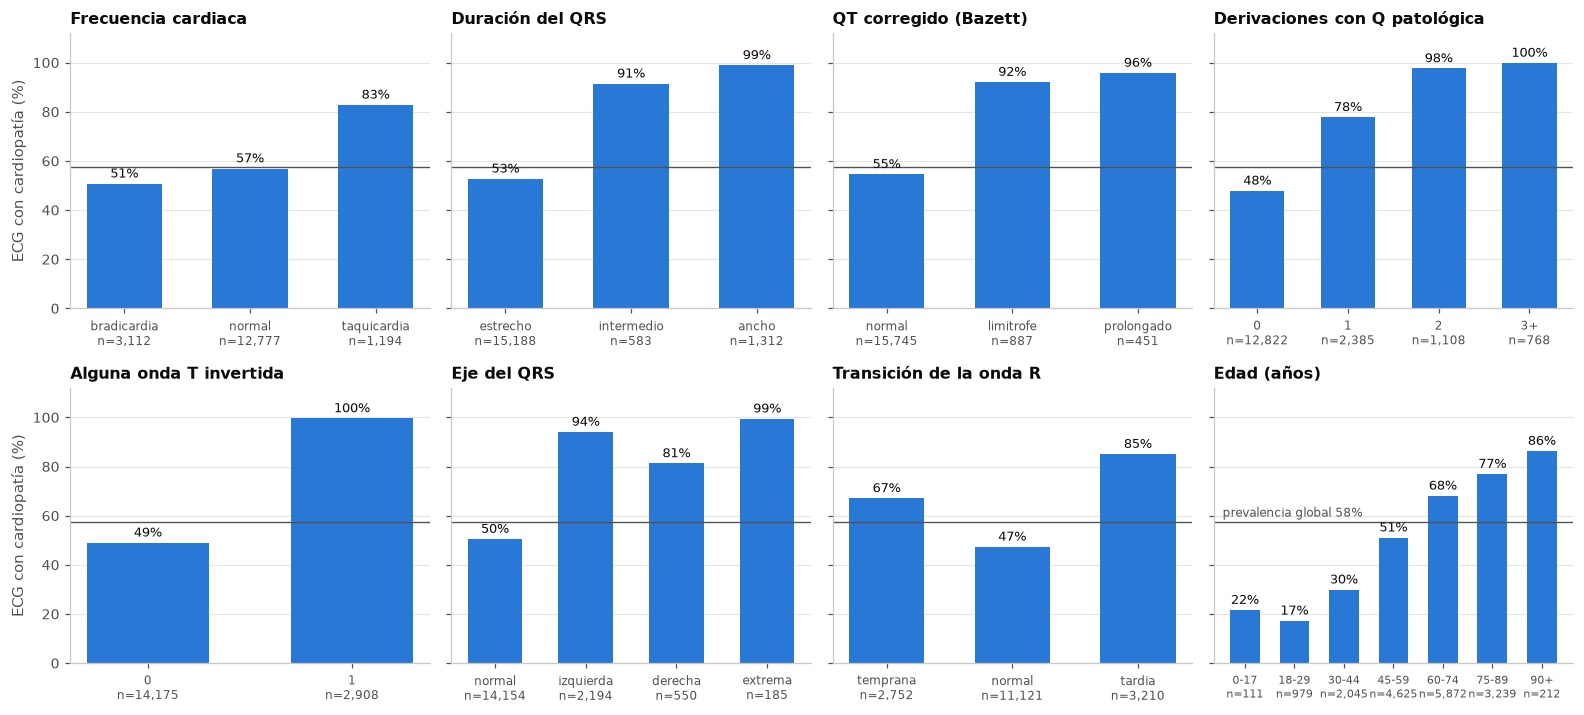

MI_%  STTC_%  CD_%  HYP_%
variable   categoría                            
qrs_class  estrecho    23.1    25.1  15.3   11.4
           intermedio  52.8    30.2  63.3   23.0
           ancho       43.0    15.2  92.0   19.1
axis_class normal      21.0    25.0  13.0   12.2
           izquierda   49.3    24.2  71.5   12.3
           derecha     38.0    17.3  62.2   16.5
           extrema     62.2     7.6  86.5   15.1

In [20]:
categorical = pd.DataFrame(index=X.index)
categorical["hr_class"] = np.select([X_imputed.hr_bpm < 60, X_imputed.hr_bpm >= 100], ["bradicardia", "taquicardia"], "normal")
categorical["qrs_class"] = np.select([X_imputed.qrs_dur_ms < 110, X_imputed.qrs_dur_ms < 120], ["estrecho", "intermedio"], "ancho")
categorical["qtc_class"] = np.select([X_imputed.qtc_bazett_ms < 450, X_imputed.qtc_bazett_ms < 480], ["normal", "limitrofe"], "prolongado")
axis = X_imputed.qrs_axis_deg
categorical["axis_class"] = np.select([(axis >= -30) & (axis <= 90), (axis < -30) & (axis >= -90), axis > 90], ["normal", "izquierda", "derecha"], "extrema")
categorical["r_transition_class"] = np.select([X_imputed.r_transition_lead <= 2, X_imputed.r_transition_lead <= 4], ["temprana", "normal"], "tardia")
categorical["q_patho_class"] = X_imputed.n_q_pathologic.clip(upper=3).astype(int).astype(str).replace("3", "3+")
categorical["t_inverted_any"] = (X_imputed.n_t_inverted >= 1).astype(int)
AGE_GROUPS = ["0-17", "18-29", "30-44", "45-59", "60-74", "75-89", "90+"]
categorical["age_group"] = pd.cut(meta.age.loc[rows], [0, 18, 30, 45, 60, 75, 90, 200], right=False, labels=AGE_GROUPS).astype(str)

ORDER = {
    "hr_class": ["bradicardia", "normal", "taquicardia"], "qrs_class": ["estrecho", "intermedio", "ancho"],
    "qtc_class": ["normal", "limitrofe", "prolongado"], "q_patho_class": ["0", "1", "2", "3+"],
    "t_inverted_any": [0, 1], "axis_class": ["normal", "izquierda", "derecha", "extrema"],
    "r_transition_class": ["temprana", "normal", "tardia"], "age_group": AGE_GROUPS,
}
TITLES = {
    "hr_class": "Frecuencia cardiaca", "qrs_class": "Duración del QRS", "qtc_class": "QT corregido (Bazett)",
    "q_patho_class": "Derivaciones con Q patológica", "t_inverted_any": "Alguna onda T invertida",
    "axis_class": "Eje del QRS", "r_transition_class": "Transición de la onda R", "age_group": "Edad (años)",
}
display(pd.concat({v: prevalence_by(X_imputed[v].astype(int)).sort_index() for v in COUNTS}).rename_axis(["conteo original", "valor"]))

overall = 100 * y[train].mean()
fig, axes = plt.subplots(2, 4, figsize=(14.5, 6.6), sharey=True)
for ax, (variable, order) in zip(axes.flat, ORDER.items()):
    table = prevalence_by(categorical[variable]).loc[order]
    bars = ax.bar(range(len(order)), table["cardiopatia_%"], width=0.6, color=BLUE)
    ax.bar_label(bars, labels=[f"{v:.0f}%" for v in table["cardiopatia_%"]], padding=2, fontsize=8.5, color=INK)
    ax.axhline(overall, color=MUTED, linewidth=0.9)
    ax.set_xticks(range(len(order)), [f"{c}\nn={n:,}" for c, n in zip(order, table.ECG_train)], fontsize=7.5 if len(order) > 5 else 8)
    ax.set(title=TITLES[variable], ylim=(0, 112))
    ax.grid(axis="x", visible=False)
axes[1, 3].text(-0.45, overall + 2, f"prevalencia global {overall:.0f}%", fontsize=8, color=MUTED)
for ax in axes[:, 0]:
    ax.set_ylabel("ECG con cardiopatía (%)")
plt.tight_layout()
plt.show()
by_class = pd.concat({v: 100 * meta.loc[rows[train.to_numpy()], PATHOLOGY].groupby(categorical.loc[train, v].to_numpy()).mean().loc[ORDER[v]]
                      for v in ["qrs_class", "axis_class"]}).round(1)
display(by_class.rename_axis(["variable", "categoría"]).rename(columns=lambda c: f"{c}_%"))

De aquí observamos:

- Los conteos se agrupan donde dejan de informar. Con una sola onda T invertida la cardiopatía pasa de 49.0% a 99.0%, y con más ya no puede subir: la información es "ninguna o alguna", y por eso `t_inverted_any` es binaria. Con las ondas Q patológicas la prevalencia sube 47.9%, 77.8%, 97.7% y 99.8%; los 363 ECG con cuatro o más están todos en la clase positiva, así que se agrupan en "3 o más".
- La transición de la onda R tiene forma de U. Por derivación: 93.5% si la R ya domina en V1, 40.0% en V3 y 98.9% si no domina nunca. Agrupada: 67% temprana, 47% normal y 85% tardía. Tanto adelantarse como retrasarse es anormal; un número del 1 al 7 no puede expresar eso en un modelo lineal.
- Cuatro variables de la señal son monótonas: frecuencia (51%, 57%, 83%), duración del QRS (53%, 91%, 99%), QTc (55%, 92%, 96%) y ondas Q (48%, 78%, 98%, 100%). En ellas el orden de las categorías coincide con el orden del riesgo. La edad también crece casi sin excepción, de 17% entre los 18 y 29 años a 86% en los de 90 o más.
- El corte de 110 ms separa un grupo con significado propio. Los 583 ECG de QRS intermedio ya tienen 63.3% de `CD` y 52.8% de `MI`, contra 15.3% y 23.1% en los de QRS estrecho; con 120 ms o más el 92.0% tiene `CD`.
- El eje no tiene orden: normal 50%, izquierda 94%, derecha 81%, extrema 99%. Son direcciones alrededor de un círculo, no una escala.
- La bradicardia queda por debajo de la prevalencia global (51% contra 58%): en esta cohorte una frecuencia baja no indica enfermedad.

## 8. Codificación de variables categóricas

La técnica se elige con la gráfica anterior:

- Codificación ordinal (0, 1, 2, ...) cuando las categorías tienen orden y la prevalencia crece con él: `hr_class`, `qrs_class`, `qtc_class`, `q_patho_class` y `age_group`. Usa una sola columna y conserva el orden.
- One-hot cuando no hay orden (`axis_class`) o la relación tiene forma de U (`r_transition_class`). Una codificación ordinal afirmaría que "derecha" está entre "izquierda" y "extrema", lo que es falso. Se omite la categoría `normal` de cada variable: con k categorías bastan k - 1 columnas, la columna sobrante sería una combinación exacta de las otras, y así cada coeficiente se lee como "frente a un ECG normal".
- Binaria 0/1 para las variables de dos valores.
- Codificación cíclica (seno y coseno) para los ángulos. El eje del QRS es una dirección en un círculo: -179° y +179° son casi la misma dirección, pero como números están a 358 de distancia.

In [21]:
ORDINAL = {v: ORDER[v] for v in ["hr_class", "qrs_class", "qtc_class", "q_patho_class", "age_group"]}
NOMINAL = {v: ORDER[v] for v in ["axis_class", "r_transition_class"]}

ordinal_encoder = OrdinalEncoder(categories=list(ORDINAL.values())).set_output(transform="pandas")
ordinal_codes = ordinal_encoder.fit(categorical.loc[train, list(ORDINAL)]).transform(categorical[list(ORDINAL)])

onehot_encoder = OneHotEncoder(categories=list(NOMINAL.values()), drop=["normal", "normal"], sparse_output=False).set_output(transform="pandas")
dummies = onehot_encoder.fit(categorical.loc[train, list(NOMINAL)]).transform(categorical[list(NOMINAL)])

binary = pd.concat([categorical[["t_inverted_any"]].astype(float), X_imputed[BINARY], meta.sex.loc[rows].astype(float).rename("sex")], axis=1)

cyclic = pd.DataFrame({
    "qrs_axis_sin": np.sin(np.radians(X_imputed.qrs_axis_deg)), "qrs_axis_cos": np.cos(np.radians(X_imputed.qrs_axis_deg)),
    "t_axis_sin": np.sin(np.radians(X_imputed.t_axis_deg)), "t_axis_cos": np.cos(np.radians(X_imputed.t_axis_deg)),
})

encoding_summary = pd.DataFrame([
    {"variable": v, "técnica": "Ordinal", "columnas": v, "valores": " < ".join(f"{c}={i}" for i, c in enumerate(order))}
    for v, order in ORDINAL.items()
] + [
    {"variable": v, "técnica": "One-hot sin la categoría de referencia", "columnas": ", ".join(c for c in dummies.columns if c.startswith(v)),
     "valores": "referencia: normal"} for v in NOMINAL
] + [
    {"variable": "t_inverted_any, low_voltage_limb, flag_*, sex", "técnica": "Binaria 0/1", "columnas": ", ".join(binary.columns), "valores": "sex: 0 = hombre, 1 = mujer"},
    {"variable": "qrs_axis_deg, t_axis_deg", "técnica": "Cíclica (seno y coseno)", "columnas": ", ".join(cyclic.columns), "valores": "entre -1 y 1"},
]).set_index("variable")
with pd.option_context("display.max_colwidth", 120):
    display(encoding_summary)

a, b = X_imputed.qrs_axis_deg.idxmin(), X_imputed.qrs_axis_deg.idxmax()
print(f"Dos ejes casi idénticos: {X_imputed.qrs_axis_deg[a]:.1f}° y {X_imputed.qrs_axis_deg[b]:.1f}°")
print(f"  distancia con los grados crudos: {abs(X_imputed.qrs_axis_deg[a] - X_imputed.qrs_axis_deg[b]):.1f}")
print(f"  distancia con seno y coseno:     {np.hypot(cyclic.qrs_axis_sin[a] - cyclic.qrs_axis_sin[b], cyclic.qrs_axis_cos[a] - cyclic.qrs_axis_cos[b]):.3f} (el máximo posible es 2)")

,técnica,columnas,valores
variable,,,
hr_class,Ordinal,hr_class,bradicardia=0 < normal=1 < taquicardia=2
qrs_class,Ordinal,qrs_class,estrecho=0 < intermedio=1 < ancho=2
qtc_class,Ordinal,qtc_class,normal=0 < limitrofe=1 < prolongado=2
q_patho_class,Ordinal,q_patho_class,0=0 < 1=1 < 2=2 < 3+=3
age_group,Ordinal,age_group,0-17=0 < 18-29=1 < 30-44=2 < 45-59=3 < 60-74=4 < 75-89=5 < 90+=6
axis_class,One-hot sin la categoría de referencia,"axis_class_izquierda, axis_class_derecha, axis_class_extrema",referencia: normal
r_transition_class,One-hot sin la categoría de referencia,"r_transition_class_temprana, r_transition_class_tardia",referencia: normal
"t_inverted_any, low_voltage_limb, flag_*, sex",Binaria 0/1,"t_inverted_any, low_voltage_limb, flag_no_p_wave, flag_medicion_fallida, sex","sex: 0 = hombre, 1 = mujer"
"qrs_axis_deg, t_axis_deg",Cíclica (seno y coseno),"qrs_axis_sin, qrs_axis_cos, t_axis_sin, t_axis_cos",entre -1 y 1


Dos ejes casi idénticos: -179.5° y 179.5°
  distancia con los grados crudos: 359.0
  distancia con seno y coseno:     0.017 (el máximo posible es 2)


El ejemplo del final muestra el efecto de la codificación cíclica con dos ECG reales: sus ejes, -179.5° y 179.5°, quedan a 359 de distancia en grados y a 0.017 con seno y coseno.

## 9. Transformación de las distribuciones

Varias pruebas de las secciones siguientes suponen variables aproximadamente simétricas: el ANOVA compara medias, y la correlación de Pearson, el PCA y el análisis factorial se basan en relaciones lineales que una cola larga distorsiona. La transformación solo se justifica donde hace falta, así que procedemos en dos pasos.

Dónde. Medimos la asimetría (sesgo) de cada característica continua en entrenamiento y transformamos solo las que superan 0.5 en valor absoluto, el límite habitual de una distribución aproximadamente simétrica. Las demás se dejan como están.

Con qué. Comparamos cinco transformaciones sobre esas características:

- Raíz cuadrada y logaritmo: fáciles de interpretar, pero de fuerza fija y solo para valores positivos.
- Box-Cox: estima por máxima verosimilitud el exponente que mejor normaliza cada variable; solo admite valores estrictamente positivos.
- Yeo-Johnson: la misma idea, pero admite ceros y negativos. La probamos de dos formas, directa y dividiendo antes cada característica por su desviación estándar. La razón es que la fórmula suma 1 a cada valor antes de elevar al exponente, así que el resultado depende de las unidades: no es lo mismo sumar 1 a una amplitud de 0.1 mV que a una duración de 90 ms.

In [22]:
SKEW_MIN = 0.5
skew_before = X_clean.loc[train, continuous].skew()
to_transform = list(skew_before.index[skew_before.abs() > SKEW_MIN])
positive = [c for c in to_transform if X_clean.loc[train, c].min() > 0]
signed = [c for c in to_transform if c not in positive]
print(f"Continuas: {len(continuous)} | |sesgo| > 1 en {(skew_before.abs() > 1).sum()}; entre 0.5 y 1 en "
      f"{((skew_before.abs() > 0.5) & (skew_before.abs() <= 1)).sum()}; menor de 0.5 en {(skew_before.abs() <= 0.5).sum()}")
print(f"Se transforman las {len(to_transform)} con |sesgo| > {SKEW_MIN}: {len(positive)} estrictamente positivas y {len(signed)} con ceros o negativos")

power_scale = X_clean.loc[train, continuous].std()
train_raw, train_unit = X_clean.loc[train, to_transform], X_clean.loc[train, to_transform] / power_scale[to_transform]


def fitted_skew(method: str, table: pd.DataFrame) -> pd.Series:
    transformer = PowerTransformer(method=method, standardize=False).set_output(transform="pandas")
    return transformer.fit_transform(table).skew()


options = pd.DataFrame({
    "Original": skew_before[to_transform], "Raíz cuadrada": np.sqrt(train_raw[positive]).skew(), "Logaritmo": np.log(train_raw[positive]).skew(),
    "Box-Cox": fitted_skew("box-cox", train_raw[positive]), "Yeo-Johnson directa": fitted_skew("yeo-johnson", train_raw),
    "Yeo-Johnson tras dividir por la desviación": fitted_skew("yeo-johnson", train_unit),
})
summary = pd.DataFrame({
    f"positivas ({len(positive)})": options.loc[positive].abs().mean(),
    f"con ceros o negativos ({len(signed)})": options.loc[signed].abs().mean(),
    f"todas ({len(to_transform)})": options.abs().mean().where(options.notna().all()),
}).rename_axis("transformación")
print("Media del |sesgo| en train después de cada transformación (0 = simétrica; vacío = no aplicable):")
display(summary)
display(options.loc[["rr_sdnn_ms", "qrs_dur_ms", "cornell_product_mvms", "noise_drift_frac", "std_V2", "hr_bpm", "st_V2", "st_dep_lateral_mv"]])

Continuas: 146 | |sesgo| > 1 en 91; entre 0.5 y 1 en 32; menor de 0.5 en 23
Se transforman las 123 con |sesgo| > 0.5: 67 estrictamente positivas y 56 con ceros o negativos


Media del |sesgo| en train después de cada transformación (0 = simétrica; vacío = no aplicable):


,positivas (67),con ceros o negativos (56),todas (123)
transformación,,,
Original,1.537,1.873,1.690
Raíz cuadrada,0.762,NaN,NaN
Logaritmo,0.694,NaN,NaN
Box-Cox,0.050,NaN,NaN
Yeo-Johnson directa,0.083,0.371,0.214
Yeo-Johnson tras dividir por la desviación,0.069,0.253,0.153


,Original,Raíz cuadrada,Logaritmo,Box-Cox,Yeo-Johnson directa,Yeo-Johnson tras dividir por la desviación
rr_sdnn_ms,2.406,1.405,0.246,0.012,0.026,0.340
qrs_dur_ms,2.184,1.830,1.491,0.041,0.042,0.053
cornell_product_mvms,2.707,1.232,-0.102,0.008,0.006,-0.017
noise_drift_frac,3.837,1.756,-0.134,-0.004,0.605,0.338
std_V2,2.376,1.236,0.277,-0.010,0.063,0.002
hr_bpm,1.112,0.746,0.411,0.003,0.003,0.006
st_V2,2.019,NaN,NaN,NaN,-0.194,0.110
st_dep_lateral_mv,-2.372,NaN,NaN,NaN,0.011,0.116


Observamos:

- La asimetría es la regla: 91 de las 146 características continuas tienen un sesgo mayor de 1 en valor absoluto, 32 están entre 0.5 y 1 y solo 23 quedan por debajo de 0.5. Se transforman las 123 primeras.
- Raíz y logaritmo se quedan cortos: dejan un sesgo medio de 0.76 y 0.69 en las positivas, cerca de la mitad del original (1.54). En `qrs_dur_ms` el logaritmo aún deja un sesgo de 1.49.
- Box-Cox es la mejor en las positivas (0.050), pero no se puede aplicar a 56 características que tienen ceros o valores negativos: niveles del ST, amplitudes de la onda T, profundidades de Q.
- Yeo-Johnson, dividiendo antes por la desviación, casi iguala a Box-Cox en las positivas (0.069) y funciona en las demás (0.253). Sin esa división es peor en los dos grupos (0.083 y 0.371).

Decisión: una sola transformación, Yeo-Johnson tras dividir por la desviación estándar de entrenamiento, para las 123 características asimétricas. La preferimos a combinar Box-Cox y Yeo-Johnson porque la diferencia en las positivas es mínima y un solo transformador es más simple de mantener y de aplicar a datos nuevos.

|sesgo| > 1: antes 91 características, después 4
|sesgo| > 0.5: antes 123, después 8


Diferencia media entre la correlación de Pearson y la de Spearman (pares de continuas, train): antes 0.061, después 0.021


,sesgo_antes,sesgo_después,lambda,ceros_%
q_depth_V2,3.941,2.187,-6.857,70.725
q_depth_V3,5.138,2.147,-8.052,64.432
beat_similarity,-3.619,-1.583,26.787,0.000
q_depth_V1,2.881,1.536,-4.529,71.773
q_depth_V4,7.229,0.865,-4.732,42.317
q_depth_III,2.763,0.575,-2.220,38.073
q_depth_aVF,4.421,0.563,-2.509,38.799
rr_rmssd_ms,2.683,0.506,-2.356,0.000


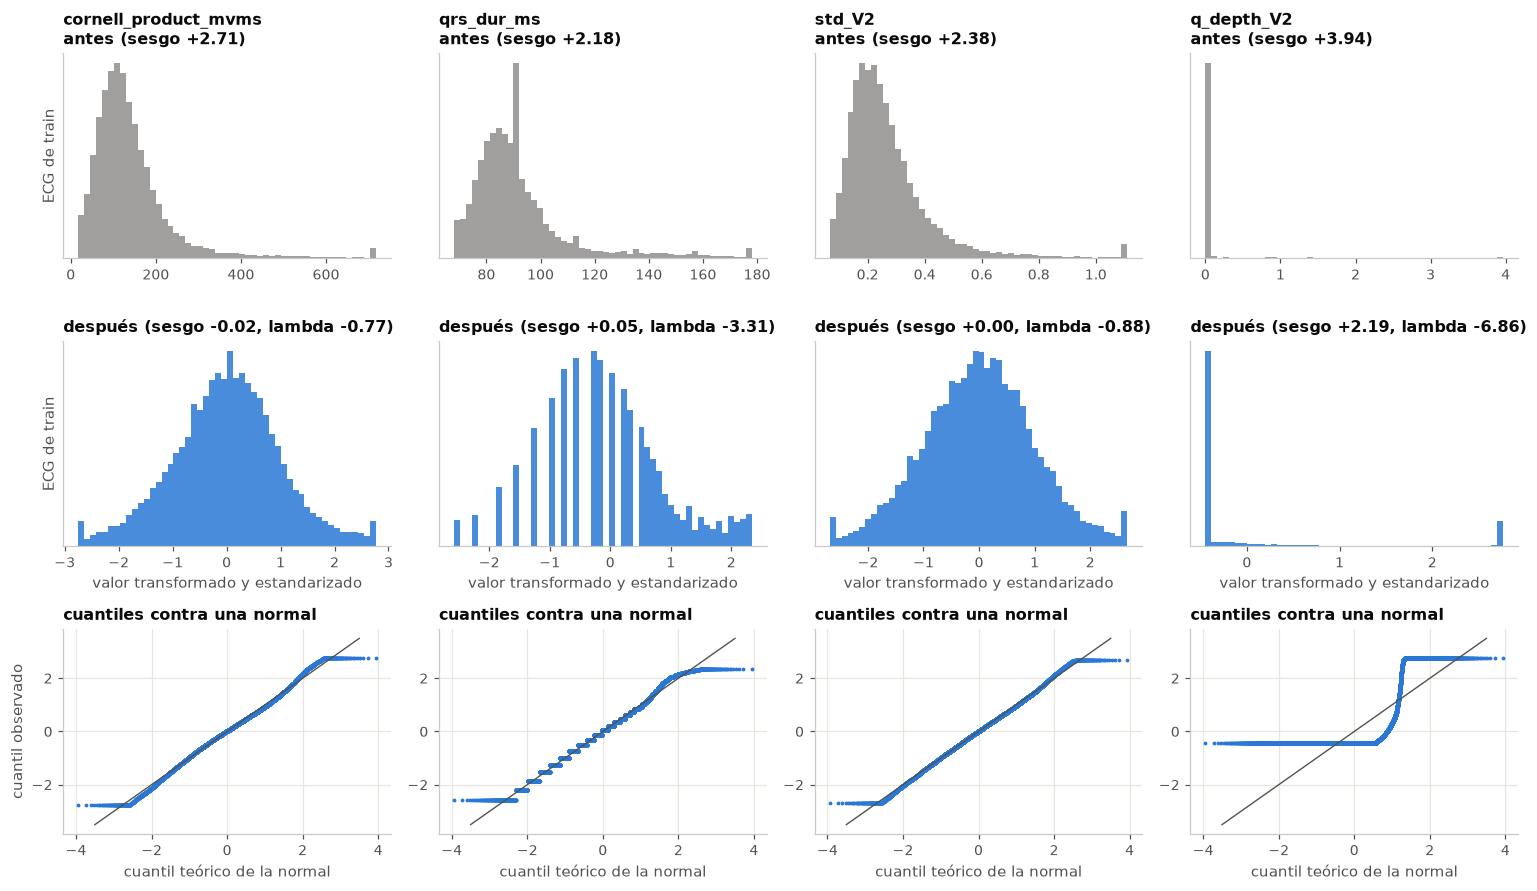

In [23]:
power = PowerTransformer(method="yeo-johnson", standardize=False).set_output(transform="pandas").fit(train_unit)
X_power = X_clean[continuous] / power_scale
X_power[to_transform] = power.transform(X_power[to_transform])

skew_after = X_power.loc[train].skew()
lambdas = pd.Series(power.lambdas_, index=to_transform)
print(f"|sesgo| > 1: antes {(skew_before.abs() > 1).sum()} características, después {(skew_after.abs() > 1).sum()}")
print(f"|sesgo| > 0.5: antes {(skew_before.abs() > 0.5).sum()}, después {(skew_after.abs() > 0.5).sum()}")


def pearson_spearman_gap(table: pd.DataFrame) -> float:
    upper_triangle = np.triu_indices(table.shape[1], k=1)
    return float(np.abs(table.corr().to_numpy() - table.rank().corr().to_numpy())[upper_triangle].mean())


print(f"Diferencia media entre la correlación de Pearson y la de Spearman (pares de continuas, train): "
      f"antes {pearson_spearman_gap(X_clean.loc[train, continuous]):.3f}, después {pearson_spearman_gap(X_power.loc[train]):.3f}")

still_skewed = skew_after[skew_after.abs() > 0.5].index
display(pd.DataFrame({"sesgo_antes": skew_before[still_skewed], "sesgo_después": skew_after[still_skewed], "lambda": lambdas.reindex(still_skewed),
                      "ceros_%": 100 * (X_clean.loc[train, still_skewed] == 0).mean()}).sort_values("sesgo_después", key=abs, ascending=False))

shown = ["cornell_product_mvms", "qrs_dur_ms", "std_V2", "q_depth_V2"]
fig, axes = plt.subplots(3, 4, figsize=(14, 8.2))
for column, name in enumerate(shown):
    axes[0, column].hist(X_clean.loc[train, name], bins=50, color=MUTED, alpha=0.55, linewidth=0)
    axes[0, column].set_title(f"{name}\nantes (sesgo {skew_before[name]:+.2f})")
    standardized = stats.zscore(X_power.loc[train, name])
    axes[1, column].hist(standardized, bins=50, color=BLUE, alpha=0.85, linewidth=0)
    axes[1, column].set_title(f"después (sesgo {skew_after[name]:+.2f}, lambda {lambdas[name]:+.2f})")
    axes[1, column].set_xlabel("valor transformado y estandarizado")
    (theoretical, ordered), _ = stats.probplot(standardized, dist="norm")
    axes[2, column].plot(theoretical, ordered, ".", color=BLUE, markersize=3)
    axes[2, column].plot([-3.5, 3.5], [-3.5, 3.5], color=MUTED, linewidth=0.9)
    axes[2, column].set(title="cuantiles contra una normal", xlabel="cuantil teórico de la normal")
for ax in axes[:2].flat:
    ax.set_yticks([])
    ax.grid(False)
axes[0, 0].set_ylabel("ECG de train")
axes[1, 0].set_ylabel("ECG de train")
axes[2, 0].set_ylabel("cuantil observado")
plt.tight_layout()
plt.show()

Las características con sesgo mayor de 1 bajan de 91 a 4, y las de sesgo mayor de 0.5, de 123 a 8. La diferencia media entre la correlación de Pearson y la de Spearman (que no supone linealidad) baja de 0.061 a 0.021: después de transformar, la correlación lineal describe bien las relaciones, y eso es lo que necesitan el filtro de correlación y el PCA.

En la fila de abajo, cada punto compara un cuantil observado con el que tendría una distribución normal. En `cornell_product_mvms` y `std_V2` los puntos siguen la diagonal; los tramos planos de los extremos son los valores recortados en la sección 6. `qrs_dur_ms` avanza en escalones porque se mide en pasos de 2 ms (una muestra a 500 Hz).

Lo que no se arregla, y por qué: `q_depth_V1`, `q_depth_V2` y `q_depth_V3` siguen sesgadas porque entre el 64% y el 72% de sus valores son exactamente cero (no hay onda Q): ninguna transformación monótona puede repartir un valor repetido, como se ve en el último panel. Esa información de "hay o no hay onda Q" ya está recogida en `q_patho_class`. `beat_similarity` tiene un techo en 1.

## 10. Escalamiento

Las características están en unidades distintas: mV, ms, latidos por minuto, fracciones. En los métodos que dependen de distancias o de la magnitud de los coeficientes (regresión logística regularizada, PCA, redes neuronales), una variable con números grandes pesaría más solo por su unidad. Cada bloque recibe el escalador que le corresponde:

- Continuas: estandarización (media 0, desviación 1). Después de la transformación son aproximadamente simétricas, que es el caso para el que está pensada. No hace falta un escalador robusto porque los extremos ya se recortaron, y min-max haría depender toda la escala de esos dos valores recortados.
- Ordinales: min-max a [0, 1], para que compartan rango con las binarias.
- Binarias, one-hot y cíclicas: sin cambio. Ya están entre 0 y 1 o entre -1 y 1, y estandarizar el seno y el coseno por separado deformaría el círculo que representan.

Además de comprobar el resultado, medimos el efecto práctico sobre dos optimizadores. L-BFGS es un método cuasi-Newton, que tolera mejor las diferencias de escala. SAGA es un método de gradiente estocástico, sensible a la escala igual que el entrenamiento de las redes neuronales de la línea principal del proyecto. Con cada uno ajustamos la misma regresión logística sobre las características sin escalar, solo estandarizadas, y transformadas y estandarizadas.

,mín_antes,máx_antes,desv_antes,mín_después,máx_después,desv_después
hr_bpm,4.437e+01,141.903,1.631e+01,-2.710,2.692,1.0
qrs_dur_ms,6.800e+01,178.000,1.855e+01,-2.583,2.337,1.0
cornell_product_mvms,1.750e+01,717.359,9.699e+01,-2.750,2.768,1.0
st_V2,-1.905e-01,0.822,1.201e-01,-4.360,4.195,1.0
noise_powerline_frac,2.480e-05,0.005,7.296e-04,-2.174,2.445,1.0
kurt_V1,1.211e+00,37.705,7.270e+00,-2.070,2.950,1.0


Desviación estándar antes de escalar: de 0.0007 (noise_powerline_frac) a 171.1 (rr_mean_ms); razón 234,483 a 1
Después de escalar (train): media máxima en valor absoluto 8.1e-12, desviación entre 1.000 y 1.000
Validación con los parámetros de train: |media| mediana 0.032 y máxima 0.166 (noise_drift_frac); desviación entre 0.93 y 1.06


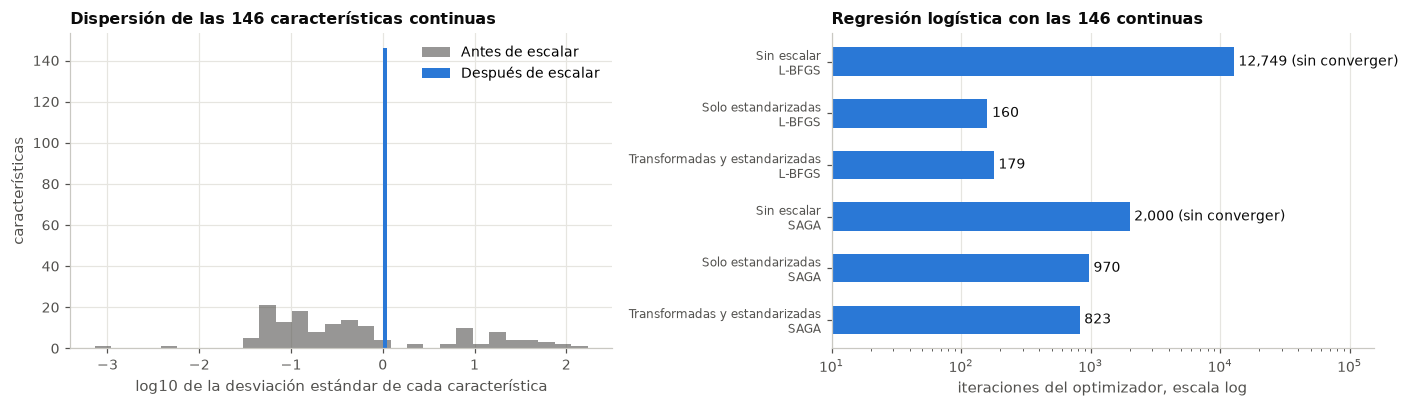

columnas iteraciones convergió ajuste_s AUROC_val esp_a_sens_95 esp_a_sens_99
optimizador                  entrada                                                                                                     
L-BFGS (cuasi-Newton)        Sin escalar                         146       12749     False    8.908     0.921         0.555         0.302
                             Solo estandarizadas                 146         160      True    0.114     0.924         0.566         0.329
                             Transformadas y estandarizadas      146         179      True    0.132     0.922         0.562          0.35
SAGA (gradiente estocástico) Sin escalar                         146        2000     False   24.271     0.889         0.455         0.164
                             Solo estandarizadas                 146         970      True   11.726     0.924         0.569         0.329
                             Transformadas y estandarizadas      146         823      True   10.025     0.922         0.561          0.35

In [24]:
scaler = StandardScaler().set_output(transform="pandas").fit(X_power.loc[train])
Z = scaler.transform(X_power)
ordinal_scaler = MinMaxScaler().set_output(transform="pandas").fit(ordinal_codes.loc[train])
ordinal_scaled = ordinal_scaler.transform(ordinal_codes)

examples = ["hr_bpm", "qrs_dur_ms", "cornell_product_mvms", "st_V2", "noise_powerline_frac", "kurt_V1"]
before_after = pd.DataFrame({
    "mín_antes": X_clean.loc[train, examples].min(), "máx_antes": X_clean.loc[train, examples].max(),
    "desv_antes": X_clean.loc[train, examples].std(), "mín_después": Z.loc[train, examples].min(),
    "máx_después": Z.loc[train, examples].max(), "desv_después": Z.loc[train, examples].std(),
})
display(before_after)
spread_before = X_clean.loc[train, continuous].std()
print(f"Desviación estándar antes de escalar: de {spread_before.min():.4f} ({spread_before.idxmin()}) a {spread_before.max():.1f} "
      f"({spread_before.idxmax()}); razón {spread_before.max() / spread_before.min():,.0f} a 1")
print(f"Después de escalar (train): media máxima en valor absoluto {Z.loc[train].mean().abs().max():.1e}, desviación entre "
      f"{Z.loc[train].std().min():.3f} y {Z.loc[train].std().max():.3f}")
print(f"Validación con los parámetros de train: |media| mediana {Z.loc[val].mean().abs().median():.3f} y máxima {Z.loc[val].mean().abs().max():.3f} "
      f"({Z.loc[val].mean().abs().idxmax()}); desviación entre {Z.loc[val].std().min():.2f} y {Z.loc[val].std().max():.2f}")


def specificity_at(y_true, score, sensitivity: float) -> float:
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(1 - fpr[np.searchsorted(tpr, sensitivity)])


def fit_logistic(table, solver: str = "lbfgs", max_iter: int = 20000, fit_rows: np.ndarray | None = None) -> dict:
    """Ajusta una regresión logística en train (o en las filas indicadas) y la mide en validación."""
    table = np.asarray(table, dtype=float)
    fit_rows = np.flatnonzero(train.to_numpy()) if fit_rows is None else fit_rows
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        start = time.perf_counter()
        model = LogisticRegression(solver=solver, max_iter=max_iter, random_state=SEED).fit(table[fit_rows], y.to_numpy()[fit_rows])
        seconds = time.perf_counter() - start
    score = model.predict_proba(table[val.to_numpy()])[:, 1]
    return {"columnas": table.shape[1], "iteraciones": int(model.n_iter_[0]),
            "convergió": not any(issubclass(w.category, ConvergenceWarning) for w in caught), "ajuste_s": seconds,
            "AUROC_val": roc_auc_score(y[val], score), "esp_a_sens_95": specificity_at(y[val], score, 0.95),
            "esp_a_sens_99": specificity_at(y[val], score, 0.99), "score": score}


inputs = {"Sin escalar": X_clean[continuous],
          "Solo estandarizadas": StandardScaler().fit(X_clean.loc[train, continuous]).transform(X_clean[continuous]),
          "Transformadas y estandarizadas": Z}
SOLVERS = {"L-BFGS (cuasi-Newton)": ("lbfgs", 20000), "SAGA (gradiente estocástico)": ("saga", 2000)}
convergence = pd.DataFrame({(solver_name, name): fit_logistic(table, solver, max_iter)
                            for solver_name, (solver, max_iter) in SOLVERS.items() for name, table in inputs.items()}).T.drop(columns="score")
convergence.index.names = ["optimizador", "entrada"]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(np.log10(spread_before), bins=30, color=MUTED, alpha=0.6, linewidth=0, label="Antes de escalar")
axes[0].hist(np.log10(Z.loc[train].std()), bins=np.linspace(-0.05, 0.05, 3), color=BLUE, linewidth=0, label="Después de escalar")
axes[0].set(xlabel="log10 de la desviación estándar de cada característica", ylabel="características",
            title=f"Dispersión de las {len(continuous)} características continuas")
axes[0].legend()
shown = convergence.iloc[::-1]
bars = axes[1].barh([f"{entry}\n{solver.split(' ')[0]}" for solver, entry in shown.index], shown.iteraciones.astype(int), height=0.55, color=BLUE)
axes[1].bar_label(bars, labels=[f"{int(n):,}" + ("" if ok else " (sin converger)") for n, ok in zip(shown.iteraciones, shown["convergió"])],
                  padding=3, fontsize=9, color=INK)
axes[1].set(xlabel="iteraciones del optimizador, escala log", xscale="log", title=f"Regresión logística con las {len(continuous)} continuas")
axes[1].grid(axis="y", visible=False)
axes[1].set_xlim(10, convergence.iteraciones.max() * 12)
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
display(convergence)

Antes de escalar, la desviación estándar de las características va de 0.0007 (`noise_powerline_frac`) a 171.1 (`rr_mean_ms`), una razón de 234,483 a 1. Después todas valen 1 en entrenamiento, y en validación, con los parámetros de entrenamiento, quedan entre 0.93 y 1.06: los parámetros se trasladan bien a datos que no se usaron para ajustarlos.

El efecto sobre la convergencia se repite en los dos optimizadores:

- L-BFGS: sin escalar se detiene sin converger tras 12,749 iteraciones; con las características estandarizadas converge en 160, unas 80 veces menos.
- SAGA: sin escalar agota las 2,000 pasadas sin converger y el modelo que deja es peor (AUROC 0.889 contra 0.924, y especificidad a 95% de sensibilidad de 0.455 contra 0.569). Estandarizado converge en 970 pasadas, y transformado y estandarizado en 823.

La transformación de potencia no cambia el desempeño de este clasificador. Con L-BFGS el AUROC es 0.922 con Yeo-Johnson y 0.924 sin ella. Su aporte a la convergencia es menor (un 15% menos de pasadas con SAGA) y se conserva sobre todo por lo que aporta a las pruebas de las secciones siguientes.

In [25]:
signal_binary = ["t_inverted_any", "low_voltage_limb", "flag_no_p_wave", "flag_medicion_fallida"]
signal_ordinal = ["hr_class", "qrs_class", "qtc_class", "q_patho_class"]
ready = pd.concat([Z, cyclic, ordinal_scaled[signal_ordinal], dummies, binary[signal_binary]], axis=1)
metadata_block = pd.concat([ordinal_scaled[["age_group"]], binary[["sex"]]], axis=1).add_prefix("meta_")

blocks = pd.DataFrame([
    {"bloque": "Continuas (potencia donde hace falta + estandarización)", "columnas": Z.shape[1]},
    {"bloque": "Cíclicas (seno y coseno)", "columnas": cyclic.shape[1]},
    {"bloque": "Ordinales en [0, 1]", "columnas": len(signal_ordinal)},
    {"bloque": "One-hot", "columnas": dummies.shape[1]},
    {"bloque": "Binarias", "columnas": len(signal_binary)},
]).set_index("bloque")
display(blocks)
print(f"Matriz lista para modelar: {ready.shape[0]:,} ECG x {ready.shape[1]} características de la señal | faltantes: {int(ready.isna().sum().sum())}")
print(f"Bloque de metadatos, guardado aparte: {list(metadata_block.columns)}")

,columnas
bloque,
Continuas (potencia donde hace falta + estandarización),146
Cíclicas (seno y coseno),4
"Ordinales en [0, 1]",4
One-hot,5
Binarias,4


Matriz lista para modelar: 21,387 ECG x 163 características de la señal | faltantes: 0
Bloque de metadatos, guardado aparte: ['meta_age_group', 'meta_sex']


Matriz lista para modelar. Reunimos los bloques: 146 continuas, 4 cíclicas, 4 ordinales, 5 one-hot y 4 binarias, 163 características de la señal sin ningún faltante. La edad y el sexo quedan aparte en `meta_age_group` y `meta_sex`.

## 11. Selección de características por filtros

Con 163 características hay más de las necesarias: muchas se miden en 12 derivaciones que, como vimos, no son independientes. Los métodos de filtro evalúan cada característica con una prueba estadística, sin entrenar un modelo, y los aplicamos en este orden:

1. Varianza: quitar lo que casi no cambia entre ECG.
2. Relevancia: quitar lo que no se relaciona con ninguna etiqueta (ANOVA para las numéricas, chi-cuadrado para las categóricas).
3. Redundancia: de cada grupo de características que dicen lo mismo, conservar una (correlación).

La relevancia va antes que la redundancia para que, al elegir un representante de cada grupo redundante, ya se sepa cuál es el más informativo. Todas las pruebas usan solo entrenamiento.

### Umbral de varianza

Una característica con el mismo valor en casi todos los ECG no puede distinguir nada. El detalle es cuándo medir la varianza: después de estandarizar todas valen 1 y el filtro quedaría ciego. La medimos con todas las características llevadas al intervalo [0, 1] antes de estandarizar, y el umbral es la varianza de una variable binaria que vale 1 en el 1% de los casos (0.01 × 0.99 = 0.0099). Así el criterio tiene una lectura directa: se descarta lo que es prácticamente constante en más del 99% de los ECG.

In [26]:
before_scaling = pd.concat([X_clean[continuous], cyclic, ordinal_codes[signal_ordinal], dummies, binary[signal_binary]], axis=1)
unit = MinMaxScaler().set_output(transform="pandas").fit_transform(before_scaling.loc[train])
THRESHOLD_VARIANCE = 0.01 * 0.99
variance_filter = VarianceThreshold(threshold=THRESHOLD_VARIANCE).fit(unit)
variance = pd.DataFrame({"varianza_en_[0,1]": variance_filter.variances_, "valor_más_frecuente_%": [100 * unit[c].round(6).value_counts(normalize=True).iloc[0] for c in unit]},
                        index=unit.columns)
low_variance = list(unit.columns[~variance_filter.get_support()])
print(f"Umbral: {THRESHOLD_VARIANCE:.4f} (la varianza de una binaria con 1% de unos)")
print(f"Eliminadas por varianza: {len(low_variance)} de {unit.shape[1]} -> {low_variance}")
display(variance.sort_values("varianza_en_[0,1]").head(8))
print(f"Varianza de Z (estandarizada) en train: mínimo {Z.loc[train].var().min():.3f}, máximo {Z.loc[train].var().max():.3f}")

Umbral: 0.0099 (la varianza de una binaria con 1% de unos)
Eliminadas por varianza: 1 de 163 -> ['flag_medicion_fallida']


,"varianza_en_[0,1]",valor_más_frecuente_%
flag_medicion_fallida,0.006,99.374
axis_class_extrema,0.011,98.917
q_depth_V4,0.011,42.317
st_V1,0.012,0.503
qrs_area_V1,0.013,0.503
st_dep_anterior_mv,0.013,0.503
p_rms_mv,0.014,0.503
st_III,0.014,0.503


Varianza de Z (estandarizada) en train: mínimo 1.000, máximo 1.000


Se elimina 1 de 163: `flag_medicion_fallida`, que tiene el mismo valor en el 99.4% de los ECG. No entra como predictor, pero no se desecha: la sección 4 mostró que el 96.1% de esos ECG tiene cardiopatía, así que queda como regla de control de calidad (un ECG que no se pudo medir debe ir a revisión). La sección 13 comprueba que el modelo no los pierde.

Las siguientes en la lista sobreviven por poco: `axis_class_extrema` y `q_depth_V4` (0.011).

### Relevancia: ANOVA y chi-cuadrado

El ANOVA de un factor pregunta si la media de una característica numérica cambia entre grupos; su estadístico F compara la variación entre grupos con la variación dentro de ellos. La chi-cuadrado de independencia hace la pregunta equivalente para una variable categórica: compara las frecuencias observadas en la tabla con las que se esperarían si no hubiera relación. Tomamos cinco decisiones:

- Cinco objetivos, no uno. Cada prueba se repite frente al objetivo binario y frente a cada superclase de enfermedad (el ECG la tiene o no). La sección 5 mostró que la clase positiva mezcla enfermedades con efectos opuestos; una prueba solo de "normal contra cardiopatía" puede no ver una característica que distingue muy bien a una de ellas. Una variable se conserva si es relevante para al menos un objetivo.
- Un ECG por paciente. Las dos pruebas suponen observaciones independientes y hay pacientes con varios ECG. Usamos el primer ECG de cada paciente de entrenamiento.
- Tamaño del efecto en lugar de valor p. Con miles de ECG casi cualquier diferencia resulta significativa. Medimos la proporción de variabilidad explicada: eta² en el ANOVA y V² de Cramér en la chi-cuadrado, que están en la misma escala. El umbral es 0.01, el efecto "pequeño" de Cohen (equivale a V = 0.10).
- Corrección por comparaciones múltiples. Son casi 800 pruebas. Los valores p se corrigen con el método de Benjamini-Hochberg, que controla la proporción de falsos hallazgos; al valor corregido lo llamamos q.
- Comprobación de supuestos. La chi-cuadrado pide frecuencias esperadas de al menos 5. El ANOVA supone normalidad, así que comparamos su ordenamiento con el de Kruskal-Wallis, la prueba equivalente que no la supone. Las variables one-hot se juzgan completas, con todas sus categorías: eliminar una sola de sus columnas equivaldría a fusionar esa categoría con la de referencia sin decirlo.

In [27]:
EFFECT_MIN = 0.01
first_ecg = meta.loc[rows[train.to_numpy()]].sort_values("recording_date").groupby("patient_id").head(1).index
TARGETS = {"Cardiopatía": y, **{c: meta.loc[rows, c] for c in PATHOLOGY}}
numeric = [c for c in continuous + list(cyclic.columns) if c not in low_variance]
categorical_tested = {**{v: categorical[v] for v in ["hr_class", "qrs_class", "qtc_class", "q_patho_class", "axis_class", "r_transition_class"]},
                      **{v: binary[v] for v in signal_binary if v not in low_variance}}

records = []
for target_name, target in TARGETS.items():
    t = target.loc[first_ecg]
    f_value, p_value = f_classif(ready.loc[first_ecg, numeric], t)
    records += [{"variable": c, "objetivo": target_name, "prueba": "ANOVA", "estadístico": f, "p": p, "efecto": f / (f + len(t) - 2), "esperada_min": np.nan}
                for c, f, p in zip(numeric, f_value, p_value)]
    for name, column in categorical_tested.items():
        result = cramers_v(column.loc[first_ecg], t)
        records.append({"variable": name, "objetivo": target_name, "prueba": "chi-cuadrado", "estadístico": result["chi2"], "p": result["p"],
                        "efecto": result["V_Cramer"] ** 2, "esperada_min": result["esperada_min"]})
tests = pd.DataFrame(records)
tests["q"] = stats.false_discovery_control(tests.p.clip(lower=1e-300), method="bh")
tests["relevante"] = (tests.q < 0.05) & (tests.efecto >= EFFECT_MIN) & ~(tests.esperada_min < 5)

effect = tests.pivot(index="variable", columns="objetivo", values="efecto")[list(TARGETS)]
relevance = effect.copy()
relevance.insert(0, "familia", [family(c) for c in relevance.index])
relevance.insert(1, "prueba", tests.drop_duplicates("variable").set_index("variable").prueba)
relevance["efecto_max"] = effect.max(axis=1)
relevance["objetivo_max"] = effect.idxmax(axis=1)
relevance["relevante"] = tests.groupby("variable").relevante.any()
kruskal = pd.Series({c: stats.kruskal(ready.loc[first_ecg, c][y[first_ecg] == 0], ready.loc[first_ecg, c][y[first_ecg] == 1]).statistic for c in numeric})
f_binary = tests[(tests.objetivo == "Cardiopatía") & (tests.prueba == "ANOVA")].set_index("variable").estadístico

print(f"ECG usados en las pruebas (uno por paciente, train): {len(first_ecg):,} de {int(train.sum()):,}")
print(f"Pruebas: {len(tests)} ({len(numeric)} numéricas y {len(categorical_tested)} categóricas por {len(TARGETS)} objetivos) | "
      f"con q < 0.05 tras Benjamini-Hochberg: {(tests.q < 0.05).sum()} | menor frecuencia esperada en chi-cuadrado: {tests.esperada_min.min():.1f}")
print("Variables con efecto de al menos 0.01 según el objetivo: " + " | ".join(f"{t}: {(effect[t] >= EFFECT_MIN).sum()}" for t in TARGETS)
      + f" | en alguno: {int(relevance.relevante.sum())} de {len(relevance)}")
print(f"Correlación de Spearman entre F y Kruskal-Wallis (objetivo binario, {len(numeric)} numéricas): {stats.spearmanr(f_binary[numeric], kruskal[numeric]).statistic:.3f}")
print("Variables sin efecto suficiente en ningún objetivo:")
display(relevance.loc[~relevance.relevante].sort_values("efecto_max", ascending=False).drop(columns="relevante"))
irrelevant = [c for c in numeric if not relevance.relevante[c]]
weak_variables = [v for v in categorical_tested if not relevance.relevante[v]]
print(f"Eliminadas por relevancia: {len(irrelevant)} numéricas -> {irrelevant} | {len(weak_variables)} categóricas -> {weak_variables}")
print("Mediciones de la onda P y del intervalo PR:")
display(relevance.loc[["pr_ms", "pq_peak_ms", "flag_no_p_wave", "p_amp_II", "p_rms_mv"], list(TARGETS) + ["efecto_max", "relevante"]])

ECG usados en las pruebas (uno por paciente, train): 14,822 de 17,083
Pruebas: 795 (150 numéricas y 9 categóricas por 5 objetivos) | con q < 0.05 tras Benjamini-Hochberg: 724 | menor frecuencia esperada en chi-cuadrado: 18.5
Variables con efecto de al menos 0.01 según el objetivo: Cardiopatía: 99 | MI: 93 | STTC: 84 | CD: 96 | HYP: 84 | en alguno: 147 de 159
Correlación de Spearman entre F y Kruskal-Wallis (objetivo binario, 150 numéricas): 0.973
Variables sin efecto suficiente en ningún objetivo:


objetivo,familia,prueba,Cardiopatía,MI,STTC,CD,HYP,efecto_max,objetivo_max
variable,,,,,,,,,
q_depth_aVR,QRS: amplitud y eje,ANOVA,8.554e-04,9.643e-03,7.884e-03,3.792e-03,8.346e-03,0.010,MI
qt_ms,Intervalos,ANOVA,1.636e-03,6.522e-04,2.213e-03,8.754e-03,5.496e-04,0.009,CD
noise_drift_frac,Calidad,ANOVA,8.681e-03,3.917e-03,2.854e-03,4.899e-04,6.524e-03,0.009,Cardiopatía
low_voltage_limb,QRS: amplitud y eje,chi-cuadrado,2.706e-03,7.703e-03,2.344e-06,1.066e-04,8.984e-04,0.008,MI
rr_range_rel,Ritmo,ANOVA,2.688e-03,1.128e-04,6.954e-03,2.116e-04,2.808e-05,0.007,STTC
rr_rmssd_ms,Ritmo,ANOVA,2.635e-03,2.309e-04,6.276e-03,2.980e-04,9.110e-05,0.006,STTC
p_rms_mv,Onda P,ANOVA,2.662e-04,5.138e-05,2.549e-03,2.243e-03,6.149e-03,0.006,HYP
p_amp_II,Onda P,ANOVA,7.864e-04,5.347e-04,2.903e-04,1.220e-03,4.750e-03,0.005,HYP
t_amp_III,Repolarización (ST-T),ANOVA,3.401e-04,5.071e-05,1.445e-03,4.650e-03,6.169e-04,0.005,CD


Eliminadas por relevancia: 11 numéricas -> ['noise_drift_frac', 'rr_sdnn_ms', 'rr_rmssd_ms', 'rr_range_rel', 'qt_ms', 'p_rms_mv', 'p_amp_II', 'q_depth_I', 't_amp_III', 'q_depth_aVR', 'q_depth_V4'] | 1 categóricas -> ['low_voltage_limb']
Mediciones de la onda P y del intervalo PR:


objetivo,Cardiopatía,MI,STTC,CD,HYP,efecto_max,relevante
variable,,,,,,,
pr_ms,1.973e-02,1.096e-02,1.379e-03,0.023,5.731e-03,0.023,True
pq_peak_ms,7.240e-02,2.243e-02,3.187e-02,0.038,1.448e-02,0.072,True
flag_no_p_wave,1.675e-02,4.903e-03,1.641e-02,0.005,4.087e-04,0.017,True
p_amp_II,7.864e-04,5.347e-04,2.903e-04,0.001,4.750e-03,0.005,False
p_rms_mv,2.662e-04,5.138e-05,2.549e-03,0.002,6.149e-03,0.006,False


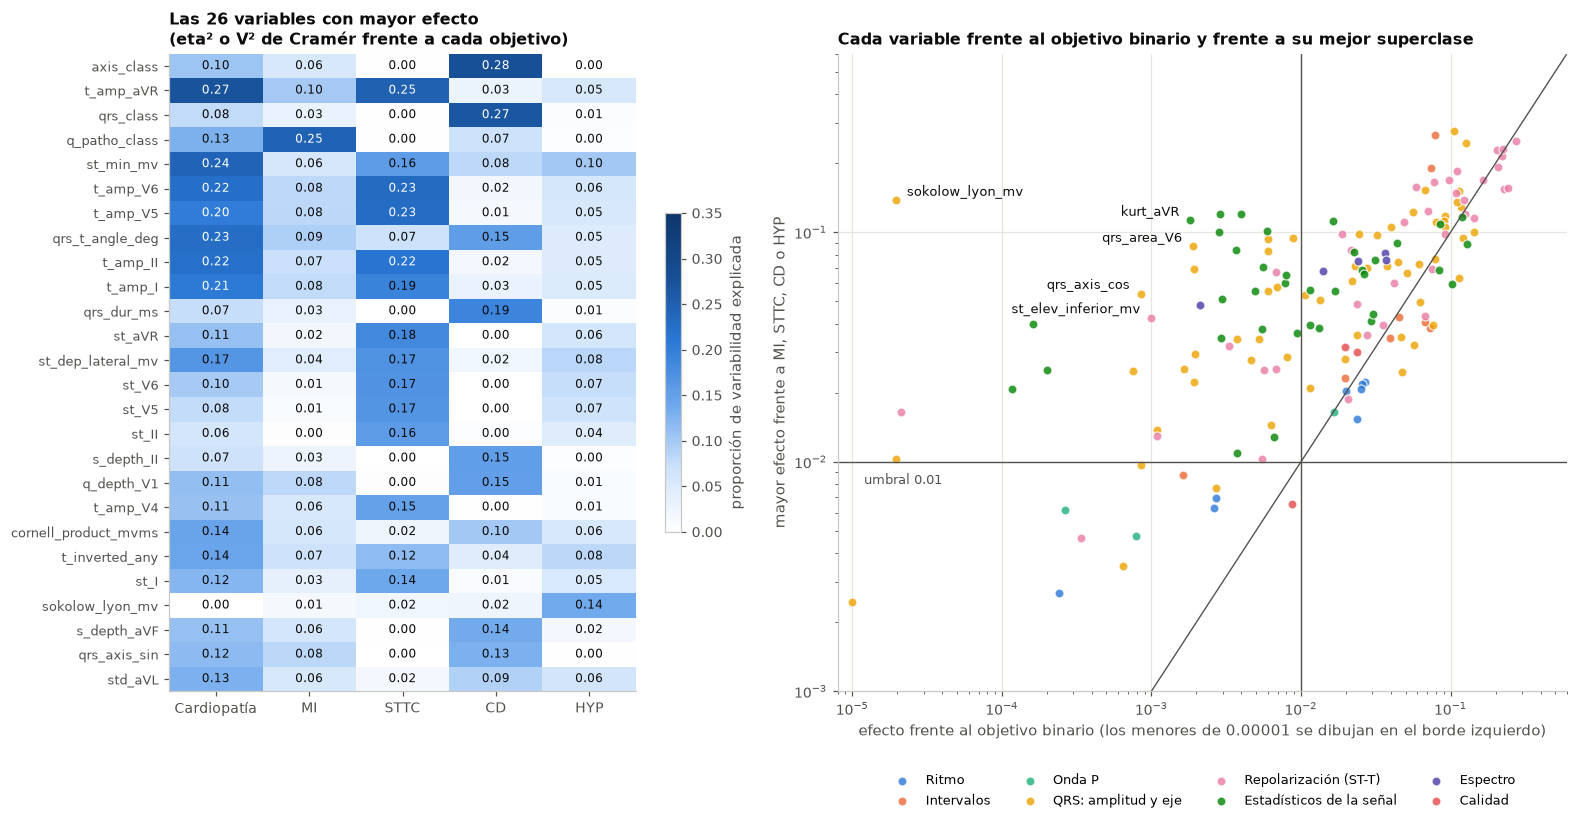

Variables por debajo del umbral frente al objetivo binario y con efecto de 0.04 o más en alguna superclase:


objetivo,Cardiopatía,MI,STTC,CD,HYP,objetivo_max
variable,,,,,,
sokolow_lyon_mv,1.967e-05,1.494e-02,0.021,0.022,1.376e-01,HYP
qrs_axis_cos,8.455e-04,4.593e-05,0.006,0.054,4.862e-04,CD
kurt_aVR,1.815e-03,7.006e-03,0.044,0.113,6.861e-03,CD
qrs_area_V6,1.884e-03,2.928e-02,0.013,0.036,8.674e-02,HYP
st_elev_inferior_mv,9.971e-04,1.829e-03,0.042,0.038,1.712e-03,STTC


Variable con mayor efecto en cada objetivo:


,1,2,3,4
Cardiopatía,t_amp_aVR (0.272),st_min_mv (0.242),qrs_t_angle_deg (0.227),t_amp_V6 (0.223)
MI,q_patho_class (0.245),q_depth_V2 (0.117),r_amp_II (0.109),t_amp_aVR (0.099)
STTC,t_amp_aVR (0.249),t_amp_V6 (0.230),t_amp_V5 (0.229),t_amp_II (0.216)
CD,axis_class (0.278),qrs_class (0.266),qrs_dur_ms (0.190),qrs_t_angle_deg (0.154)
HYP,sokolow_lyon_mv (0.138),std_V5 (0.120),std_V6 (0.120),ptp_V5 (0.101)


In [28]:
FAMILY_COLOR = dict(zip(FAMILY_PREFIXES, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]))
top = relevance.sort_values("efecto_max", ascending=False).head(26)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 7.6), width_ratios=[0.8, 1])
ax = axes[0]
image = ax.imshow(effect.loc[top.index].to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=0.35, aspect="auto")
ax.set_xticks(range(len(TARGETS)), list(TARGETS))
ax.set_yticks(range(len(top)), top.index, fontsize=8.5)
for i in range(len(top)):
    for j in range(len(TARGETS)):
        value = effect.loc[top.index[i]].iloc[j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white" if value > 0.2 else INK)
ax.grid(False)
ax.set_title("Las 26 variables con mayor efecto\n(eta² o V² de Cramér frente a cada objetivo)")
fig.colorbar(image, ax=ax, shrink=0.5, label="proporción de variabilidad explicada")

ax = axes[1]
floor = 1e-5
best_class = effect[PATHOLOGY].max(axis=1)
for name, color in FAMILY_COLOR.items():
    members = relevance.index[relevance.familia == name]
    ax.scatter(effect.loc[members, "Cardiopatía"].clip(lower=floor), best_class[members], s=34, color=color, alpha=0.8, edgecolor="white", linewidth=0.8, label=name)
ax.plot([floor, 1], [floor, 1], color=MUTED, linewidth=0.9)
ax.axhline(EFFECT_MIN, color=MUTED, linewidth=0.9)
ax.axvline(EFFECT_MIN, color=MUTED, linewidth=0.9)
ax.text(1.2e-5, EFFECT_MIN * 0.8, "umbral 0.01", fontsize=8.5, color=MUTED)
hidden = (best_class / effect.Cardiopatía.clip(lower=floor))[(effect.Cardiopatía < EFFECT_MIN) & (best_class >= 0.04)].sort_values(ascending=False).head(5).index
for name in hidden:
    x_value = max(effect.loc[name, "Cardiopatía"], floor)
    ax.annotate(name, (x_value, best_class[name]), xytext=(7, 3) if x_value < 1e-4 else (-7, 3), ha="left" if x_value < 1e-4 else "right",
                textcoords="offset points", fontsize=8.5, color=INK)
ax.set(xscale="log", yscale="log", xlim=(floor * 0.8, 0.6), ylim=(1e-3, 0.6),
       xlabel="efecto frente al objetivo binario (los menores de 0.00001 se dibujan en el borde izquierdo)",
       ylabel="mayor efecto frente a MI, STTC, CD o HYP", title="Cada variable frente al objetivo binario y frente a su mejor superclase")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), fontsize=8.5, ncols=4)
plt.tight_layout()
plt.show()
print("Variables por debajo del umbral frente al objetivo binario y con efecto de 0.04 o más en alguna superclase:")
display(relevance.loc[hidden, list(TARGETS) + ["objetivo_max"]])
print("Variable con mayor efecto en cada objetivo:")
display(pd.DataFrame({t: [f"{c} ({effect.loc[c, t]:.3f})" for c in effect[t].sort_values(ascending=False).head(4).index] for t in TARGETS}, index=["1", "2", "3", "4"]).T)

In [29]:
chi_variables = pd.DataFrame({v: cramers_v(s[train], y[train]) for v, s in categorical_tested.items()}).T
chi_variables.insert(0, "categorías", [s[train].nunique() for s in categorical_tested.values()])
chi_variables["V2_max_uno_por_paciente"] = relevance.efecto_max[chi_variables.index]
chi_variables["objetivo_max"] = relevance.objetivo_max[chi_variables.index]
chi_variables["relevante"] = relevance.relevante[chi_variables.index]
print("Chi-cuadrado de cada variable categórica contra el objetivo binario (todos los ECG de train):")
display(chi_variables.sort_values("V_Cramer", ascending=False))

chi_dummies = pd.DataFrame({c: cramers_v(dummies.loc[train, c], y[train]) for c in dummies.columns}).T
chi_dummies["ECG_con_la_categoría_%"] = 100 * dummies.loc[train].mean()
chi_dummies["cardiopatia_%_en_la_categoría"] = [100 * y[train][dummies.loc[train, c] == 1].mean() for c in dummies.columns]
print("Detalle por categoría de las variables one-hot (cada categoría contra el resto):")
display(chi_dummies[["ECG_con_la_categoría_%", "cardiopatia_%_en_la_categoría", "chi2", "V_Cramer"]])

continuous_vs_class = pd.DataFrame({"continua": {"qrs_class": "qrs_dur_ms", "qtc_class": "qtc_bazett_ms", "hr_class": "hr_bpm", "q_patho_class": "n_q_pathologic"}})
count_effect = {t: f_classif(X_imputed.loc[first_ecg, ["n_q_pathologic"]], TARGETS[t].loc[first_ecg])[0][0] for t in TARGETS}
for t in TARGETS:
    continuous_vs_class[f"clase_{t}"] = effect.loc[continuous_vs_class.index, t].to_numpy()
    continuous_vs_class[f"continua_{t}"] = [effect.loc[c, t] if c in effect.index else count_effect[t] / (count_effect[t] + len(first_ecg) - 2) for c in continuous_vs_class.continua]
print("Efecto de la versión discretizada (clase) y de la continua frente a cada objetivo:")
display(continuous_vs_class[["continua", "clase_Cardiopatía", "continua_Cardiopatía", "clase_CD", "continua_CD", "clase_MI", "continua_MI"]])

Chi-cuadrado de cada variable categórica contra el objetivo binario (todos los ECG de train):


,categorías,chi2,gl,p,V_Cramer,esperada_min,V2_max_uno_por_paciente,objetivo_max,relevante
t_inverted_any,2,2529.669,1.0,0.000e+00,0.385,1232.959,0.142,Cardiopatía,True
q_patho_class,4,2185.864,3.0,0.000e+00,0.358,325.623,0.245,MI,True
axis_class,4,1747.889,3.0,0.000e+00,0.320,78.438,0.278,CD,True
r_transition_class,3,1571.311,2.0,0.000e+00,0.303,1166.817,0.105,CD,True
qrs_class,3,1338.234,2.0,2.548e-291,0.280,247.185,0.266,CD,True
qtc_class,3,761.240,2.0,4.998e-166,0.211,191.219,0.045,Cardiopatía,True
hr_class,3,373.669,2.0,7.226e-82,0.148,506.243,0.020,STTC,True
flag_no_p_wave,2,327.842,1.0,2.836e-73,0.139,1254.583,0.017,Cardiopatía,True
low_voltage_limb,2,60.718,1.0,6.586e-15,0.060,139.068,0.008,MI,False


Detalle por categoría de las variables one-hot (cada categoría contra el resto):


,ECG_con_la_categoría_%,cardiopatia_%_en_la_categoría,chi2,V_Cramer
axis_class_izquierda,12.843,94.075,1371.222,0.283
axis_class_derecha,3.220,81.273,130.390,0.087
axis_class_extrema,1.083,99.459,134.177,0.089
r_transition_class_temprana,16.110,67.078,120.650,0.084
r_transition_class_tardia,18.791,85.047,1219.156,0.267


Efecto de la versión discretizada (clase) y de la continua frente a cada objetivo:


,continua,clase_Cardiopatía,continua_Cardiopatía,clase_CD,continua_CD,clase_MI,continua_MI
qrs_class,qrs_dur_ms,0.079,0.074,0.266,0.190,0.029,0.032
qtc_class,qtc_bazett_ms,0.045,0.068,0.043,0.040,0.010,0.017
hr_class,hr_bpm,0.020,0.027,0.003,0.005,0.005,0.005
q_patho_class,n_q_pathologic,0.127,0.104,0.069,0.055,0.245,0.207


De lo anterior observamos:

- El valor p no discrimina. De las 795 pruebas, 724 tienen q < 0.05. Los supuestos se cumplen: la menor frecuencia esperada es 18.5 y el ordenamiento por F coincide con el de Kruskal-Wallis (correlación de 0.973).
- El objetivo binario escondía características útiles. Frente a "normal contra cardiopatía" 99 variables superan el umbral de 0.01; frente a alguno de los cinco objetivos, 147 de 159. El caso más claro es `sokolow_lyon_mv`: su efecto es 0.00002 con el objetivo binario y 0.138 con `HYP`, porque sube en la hipertrofia y baja en `MI` y `CD`. Lo mismo ocurre con `kurt_aVR` (0.002 contra 0.113 en `CD`) y `qrs_area_V6` (0.002 contra 0.087 en `HYP`). En la figura de la derecha son los puntos a la izquierda de la línea vertical y por encima de la horizontal.
- Cada enfermedad tiene sus propias variables, y coinciden con su fisiología: `axis_class` (0.278) y `qrs_class` (0.266) en `CD`, `q_patho_class` (0.245) en `MI`, las ondas T en `STTC` (`t_amp_aVR`, 0.249) y `sokolow_lyon_mv` (0.138) en `HYP`. Frente al objetivo binario domina la repolarización: `t_amp_aVR` (0.272), `st_min_mv` (0.242) y `qrs_t_angle_deg` (0.227).
- Discretizar ayuda donde hay un umbral, no siempre. Para `CD`, `qrs_class` (0.266) supera a la duración continua (0.190): el bloqueo de rama es un fenómeno de umbral. Para `MI`, `q_patho_class` (0.245) supera al conteo (0.207). En cambio el QTc y la frecuencia informan más como variables continuas (0.068 contra 0.045 y 0.027 contra 0.020 frente al objetivo binario). Las dos versiones pasan al filtro de correlación.
- De la onda P informa su ausencia, no su tamaño. `p_amp_II` (0.005) y `p_rms_mv` (0.006) no alcanzan el umbral; `flag_no_p_wave` (0.017), `pr_ms` (0.023) y `pq_peak_ms` (0.072) sí.
- Se eliminan 12 de 159: once numéricas y `low_voltage_limb` (0.008), que ya había sido la derivada más débil en la sección 5.

Dos lecturas de lo eliminado. `qt_ms` sale y su versión corregida `qtc_bazett_ms` se queda, lo que confirma el valor de la derivada. Y las tres medidas de variabilidad del ritmo salen, aunque `rr_sdnn_ms` separaba la fibrilación auricular con AUROC 0.967, porque los trastornos del ritmo no forman parte de este objetivo, construido con superclases diagnósticas. La selección depende de cómo se define la etiqueta: si el proyecto decide que una arritmia también cuenta como hallazgo, este paso debe repetirse.

¿Por qué no se eliminan columnas one-hot sueltas? `axis_class_extrema` tiene una V de 0.089 frente al objetivo binario, por debajo de 0.10, pero el 99.5% de los ECG con eje extremo tiene cardiopatía. La V es baja porque la categoría es rara (1.1% de los ECG), no porque no informe. Para un proyecto que prefiere una falsa alarma a un caso perdido, una señal rara pero casi segura vale la pena.

### Correlación

El filtro recorre las variables de mayor a menor efecto (el mayor de sus cinco efectos) y conserva cada una solo si su correlación absoluta con todas las ya conservadas es menor que el umbral. De cada grupo redundante sobrevive la más relevante. Entran las numéricas y las ordinales, así cada clase discretizada compite con su variable continua.

El umbral se elige con una prueba. Lo barremos de 1.00 (no quitar nada) a 0.60 y para cada valor contamos cuántas variables quedan y cuánto rinde una regresión logística en validación. Además del AUROC miramos la especificidad a 95% y a 99% de sensibilidad: la fracción de ECG normales que el modelo deja pasar correctamente cuando el umbral de decisión se fija para detectar el 95% o el 99% de las cardiopatías. Es la medida que corresponde a un tamizaje que prefiere falsas alarmas a casos perdidos.

In [30]:
encoded_of = {**{v: [v] for v in signal_ordinal}, **{v: [c for c in dummies.columns if c.startswith(v + "_")] for v in NOMINAL},
              **{v: [v] for v in signal_binary if v not in low_variance}}
weak = [c for v in weak_variables for c in encoded_of[v]]
candidates = [c for c in numeric if c not in irrelevant] + [c for c in signal_ordinal if c not in weak]
correlation = ready.loc[train, candidates].corr().abs()
ranking = relevance.efecto_max[candidates].sort_values(ascending=False).index
categorical_kept = [c for v in list(NOMINAL) + signal_binary if v in categorical_tested and v not in weak_variables for c in encoded_of[v]]


def correlation_filter(threshold: float) -> tuple[list[str], dict[str, tuple[str, float]]]:
    """Recorre las variables de mayor a menor efecto y descarta las que repiten a una ya conservada."""
    kept, removed = [], {}
    for name in ranking:
        if kept and correlation.loc[name, kept].max() >= threshold:
            removed[name] = (correlation.loc[name, kept].idxmax(), float(correlation.loc[name, kept].max()))
        else:
            kept.append(name)
    return kept, removed


pairs = np.triu(correlation.to_numpy(), k=1)
sweep = []
for threshold in [1.0, 0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.60]:
    kept, _ = correlation_filter(threshold)
    result = fit_logistic(ready[kept + categorical_kept])
    sweep.append({"umbral_|r|": threshold, "pares_sobre_umbral": int((pairs >= threshold).sum()), "numéricas_y_ordinales": len(kept),
                  "total_con_categóricas": result["columnas"], "AUROC_val": result["AUROC_val"],
                  "esp_a_sens_95": result["esp_a_sens_95"], "esp_a_sens_99": result["esp_a_sens_99"], "iteraciones": result["iteraciones"]})
sweep = pd.DataFrame(sweep).set_index("umbral_|r|")
display(sweep)

,pares_sobre_umbral,numéricas_y_ordinales,total_con_categóricas,AUROC_val,esp_a_sens_95,esp_a_sens_99,iteraciones
umbral_|r|,,,,,,,
1.00,0,143,150,0.930,0.579,0.327,164
0.95,6,138,145,0.930,0.570,0.307,168
0.90,28,121,128,0.929,0.555,0.335,146
0.85,56,104,111,0.929,0.566,0.324,118
0.80,97,86,93,0.925,0.532,0.344,87
0.75,155,77,84,0.923,0.543,0.265,84
0.70,207,65,72,0.922,0.551,0.267,67
0.60,358,52,59,0.919,0.528,0.266,55


Hasta un umbral de 0.85 el AUROC casi no se mueve (0.930 sin filtro, 0.929 con 0.85) mientras las columnas bajan de 150 a 111 y las iteraciones del optimizador de 164 a 118. Por debajo de 0.85 la pérdida es sostenida: 0.925 con 0.80 y 0.919 con 0.60. La especificidad a 99% de sensibilidad oscila sin orden en los primeros umbrales (0.327, 0.307, 0.335, 0.324, 0.344) porque depende de muy pocos ECG; la usamos como señal de tendencia, no para afinar el corte.

Elegimos 0.85: quita 39 variables a cambio de 0.001 de AUROC.

Umbral |r| >= 0.85: se eliminan 39 y quedan 104 numéricas y ordinales


familia,Estadísticos de la señal,QRS: amplitud y eje,Repolarización (ST-T),Espectro,Ritmo,Intervalos,Calidad
eliminadas,13,11,9,2,2,1,1


,representante_conservada,|r|,familia
rr_mean_ms,hr_bpm,0.999,Ritmo
n_beats,hr_bpm,0.981,Ritmo
noise_powerline_frac,noise_hf_frac,0.956,Calidad
cornell_mv,cornell_product_mvms,0.951,QRS: amplitud y eje
r_amp_V4,r_prog_slope_mv,0.940,QRS: amplitud y eje
ptp_V1,std_V1,0.937,Estadísticos de la señal
ptp_aVL,std_aVL,0.934,Estadísticos de la señal
qrs_area_aVL,qrs_area_III,0.930,QRS: amplitud y eje
ptp_III,std_III,0.927,Estadísticos de la señal
ptp_V2,std_V2,0.925,Estadísticos de la señal


Correlación entre cada clase ordinal y su variable continua: qrs_class ~ qrs_dur_ms: 0.64 | qtc_class ~ qtc_bazett_ms: 0.56 | hr_class ~ hr_bpm: 0.82


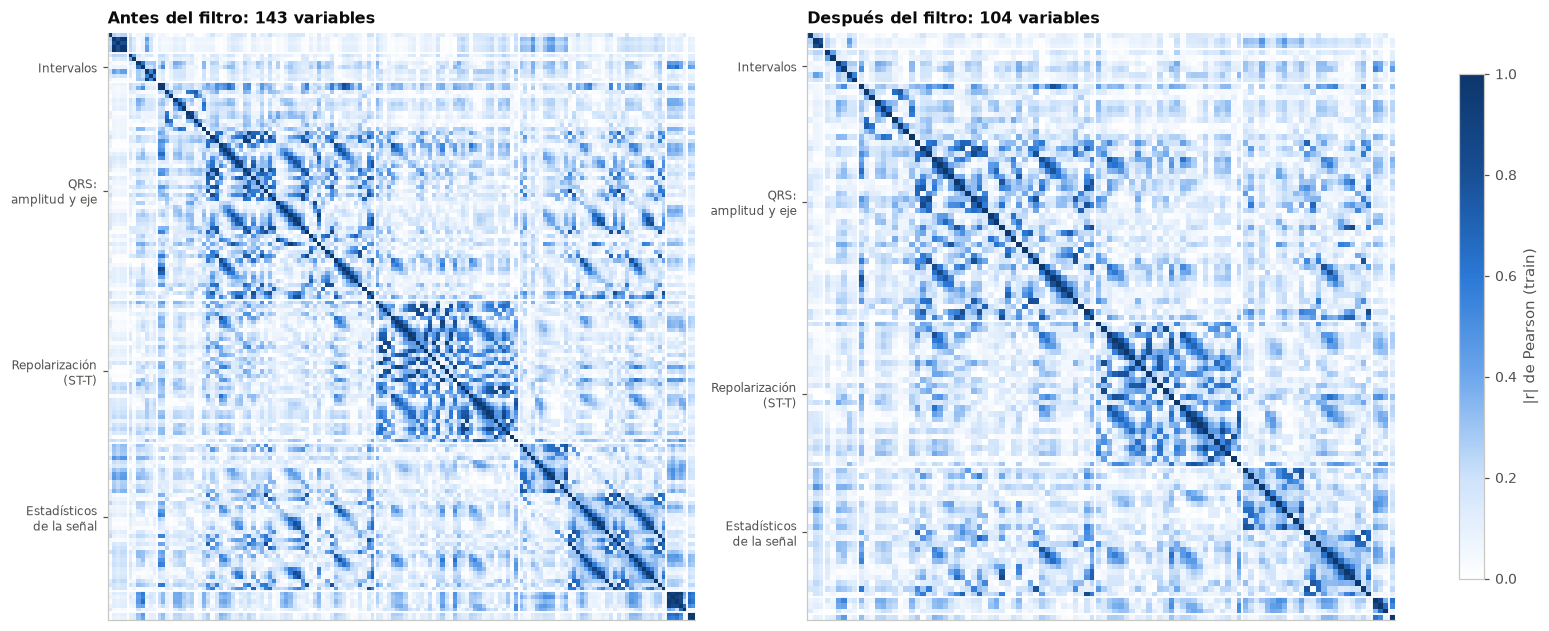

In [31]:
THRESHOLD_CORRELATION = 0.85
numeric_kept, redundant = correlation_filter(THRESHOLD_CORRELATION)
removed_table = pd.DataFrame(redundant, index=["representante_conservada", "|r|"]).T
removed_table["familia"] = [family(c) for c in removed_table.index]
removed_table["|r|"] = removed_table["|r|"].astype(float)
print(f"Umbral |r| >= {THRESHOLD_CORRELATION}: se eliminan {len(redundant)} y quedan {len(numeric_kept)} numéricas y ordinales")
display(removed_table.familia.value_counts().rename("eliminadas").to_frame().T)
with pd.option_context("display.max_rows", 60):
    display(removed_table.sort_values("|r|", ascending=False).head(14))
class_pairs = {"qrs_class": "qrs_dur_ms", "qtc_class": "qtc_bazett_ms", "hr_class": "hr_bpm"}
print("Correlación entre cada clase ordinal y su variable continua: " + " | ".join(
    f"{k} ~ {v}: {ready.loc[train, k].corr(ready.loc[train, v]):.2f}" for k, v in class_pairs.items()))

ordered = sorted(candidates, key=lambda c: (list(FAMILY_PREFIXES).index(family(c)), c))
ordered_kept = [c for c in ordered if c in numeric_kept]
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), layout="constrained")
for ax, columns, title in [(axes[0], ordered, f"Antes del filtro: {len(ordered)} variables"),
                           (axes[1], ordered_kept, f"Después del filtro: {len(ordered_kept)} variables")]:
    image = ax.imshow(correlation.loc[columns, columns], cmap=SEQUENTIAL, vmin=0, vmax=1, interpolation="nearest")
    families = [family(c) for c in columns]
    starts = [i for i, f in enumerate(families) if i == 0 or families[i - 1] != f]
    large = [s for s in starts if families.count(families[s]) >= 6]
    ax.set_xticks([])
    ax.set_yticks([s + (families.count(families[s]) - 1) / 2 for s in large], [families[s].replace(": ", ":\n").replace(" (", "\n(").replace(" de la", "\nde la") for s in large], fontsize=8)
    for s in starts[1:]:
        ax.axhline(s - 0.5, color="white", linewidth=1.2)
        ax.axvline(s - 0.5, color="white", linewidth=1.2)
    ax.grid(False)
    ax.set_title(title)
fig.colorbar(image, ax=axes, shrink=0.75, label="|r| de Pearson (train)")
plt.show()

Algunos puntos sobre lo eliminado:

- Los pares eliminados tienen explicación. `rr_mean_ms` es la frecuencia cardiaca escrita de otra forma (|r| = 0.999) y `n_beats` también (0.981). `cornell_mv` queda representada por su producto (0.951) y `r_amp_V4` por la pendiente de la onda R (0.940). Cada `ptp_*` repite a su `std_*` (0.92 a 0.94): los dos resúmenes por derivación del Avance 1 decían prácticamente lo mismo.
- Las clases discretizadas no repiten a sus variables continuas. Su correlación es 0.64 para el QRS, 0.56 para el QTc y 0.82 para la frecuencia, por debajo del umbral, así que se conservan las dos versiones.
- Lo que este filtro no puede ver. Un filtro por pares no detecta dependencias entre tres o más variables, como las que la física impone entre las 12 derivaciones. Para eso están los métodos de extracción de la sección 12.
- En los mapas de calor, los bloques oscuros dentro de cada familia (izquierda) se aclaran después del filtro (derecha).

In [32]:
selected = numeric_kept + categorical_kept
n_ordinal_candidates = len([c for c in signal_ordinal if c not in weak])
steps = pd.DataFrame([
    {"paso": "Construcción y codificación", "continuas_y_cíclicas": len(continuous) + cyclic.shape[1], "categóricas": len(signal_ordinal) + dummies.shape[1] + len(signal_binary)},
    {"paso": "Umbral de varianza", "continuas_y_cíclicas": len(numeric), "categóricas": sum(len(v) for v in encoded_of.values())},
    {"paso": "Relevancia (ANOVA y chi-cuadrado)", "continuas_y_cíclicas": len(numeric) - len(irrelevant), "categóricas": n_ordinal_candidates + len(categorical_kept)},
    {"paso": f"Correlación (|r| >= {THRESHOLD_CORRELATION})", "continuas_y_cíclicas": len([c for c in numeric_kept if c not in signal_ordinal]),
     "categóricas": len([c for c in numeric_kept if c in signal_ordinal]) + len(categorical_kept)},
]).set_index("paso")
steps["total"] = steps.sum(axis=1)
display(steps)
by_family = pd.DataFrame({"construidas": pd.Series([family(c) for c in ready.columns]).value_counts(),
                          "seleccionadas": pd.Series([family(c) for c in selected]).value_counts()}).fillna(0).astype(int)
by_family["conservadas_%"] = (100 * by_family.seleccionadas / by_family.construidas).round(0)
display(by_family.sort_values("construidas", ascending=False))

,continuas_y_cíclicas,categóricas,total
paso,,,
Construcción y codificación,150,13,163
Umbral de varianza,150,12,162
Relevancia (ANOVA y chi-cuadrado),139,11,150
Correlación (|r| >= 0.85),100,11,111


,construidas,seleccionadas,conservadas_%
QRS: amplitud y eje,62,47,76.0
Repolarización (ST-T),37,27,73.0
Estadísticos de la señal,36,23,64.0
Intervalos,8,6,75.0
Ritmo,8,3,38.0
Espectro,5,3,60.0
Calidad,4,1,25.0
Onda P,3,1,33.0


### Resultado de los filtros

De 163 características quedan 111 (se elimina el 32%): la varianza quita 1, la relevancia 12 y la redundancia 39. La relevancia descarta poco porque las características se construyeron con criterio clínico y casi todas se relacionan con alguna enfermedad; la redundancia descarta mucho porque se midieron en 12 derivaciones que no son independientes. Todas las familias siguen representadas: se conserva el 76% del QRS, el 73% de la repolarización y el 64% de los estadísticos. De la familia de la onda P solo queda el indicador de que no hay onda P.

## 12. Extracción de características

Los filtros eligen un subconjunto de las columnas originales. La extracción construye columnas nuevas que resumen a varias. Probamos tres formas, y la sección 13 las compara con la selección por filtros.

### PCA por bloques de derivaciones

El análisis de componentes principales (PCA) busca las direcciones en las que los datos varían más y las ordena por varianza. No usa la etiqueta, así que se puede ajustar también con ECG sin etiquetar.

En lugar de aplicarlo a todo junto, lo aplicamos por bloques: cada familia medida en las 12 derivaciones (el nivel del ST, la onda T, el área del QRS y las demás) forma un bloque de 12 columnas. Hay dos razones:

- Física. Las 12 derivaciones solo contienen 8 señales independientes, y la actividad eléctrica del corazón se aproxima con un vector que se mueve en tres dimensiones (el modelo de dipolo en el que se basa la vectocardiografía). Esperamos pocas direcciones por bloque.
- Interpretación. Dentro de un bloque homogéneo las cargas se leen anatómicamente. Un PCA sobre todas las variables mezcla voltajes, intervalos y repolarización en cada componente.

Cada bloque se imputa, se recorta y se estandariza con entrenamiento, sin Yeo-Johnson: el PCA aprovecha relaciones lineales entre derivaciones y una transformación no lineal distinta en cada una las deformaría. Conservamos los componentes que reúnen el 90% de la varianza del bloque y después les aplicamos la misma prueba de relevancia de la sección 11.

,variables,varianza_con_3_%,varianza_con_8_%,componentes_para_90%,seleccionadas_por_filtros
bloque,,,,,
ST,12,92.071,99.623,3,8
Onda T,12,91.578,99.054,3,8
Área del QRS,12,90.884,99.858,3,9
Onda R,12,72.218,97.648,6,6
Onda S,12,71.088,96.419,6,12
Onda Q,12,66.215,94.060,7,8
Desviación estándar,12,74.269,98.555,5,12
Pico a pico,12,71.944,98.412,5,0
Curtosis,12,69.255,95.239,6,11


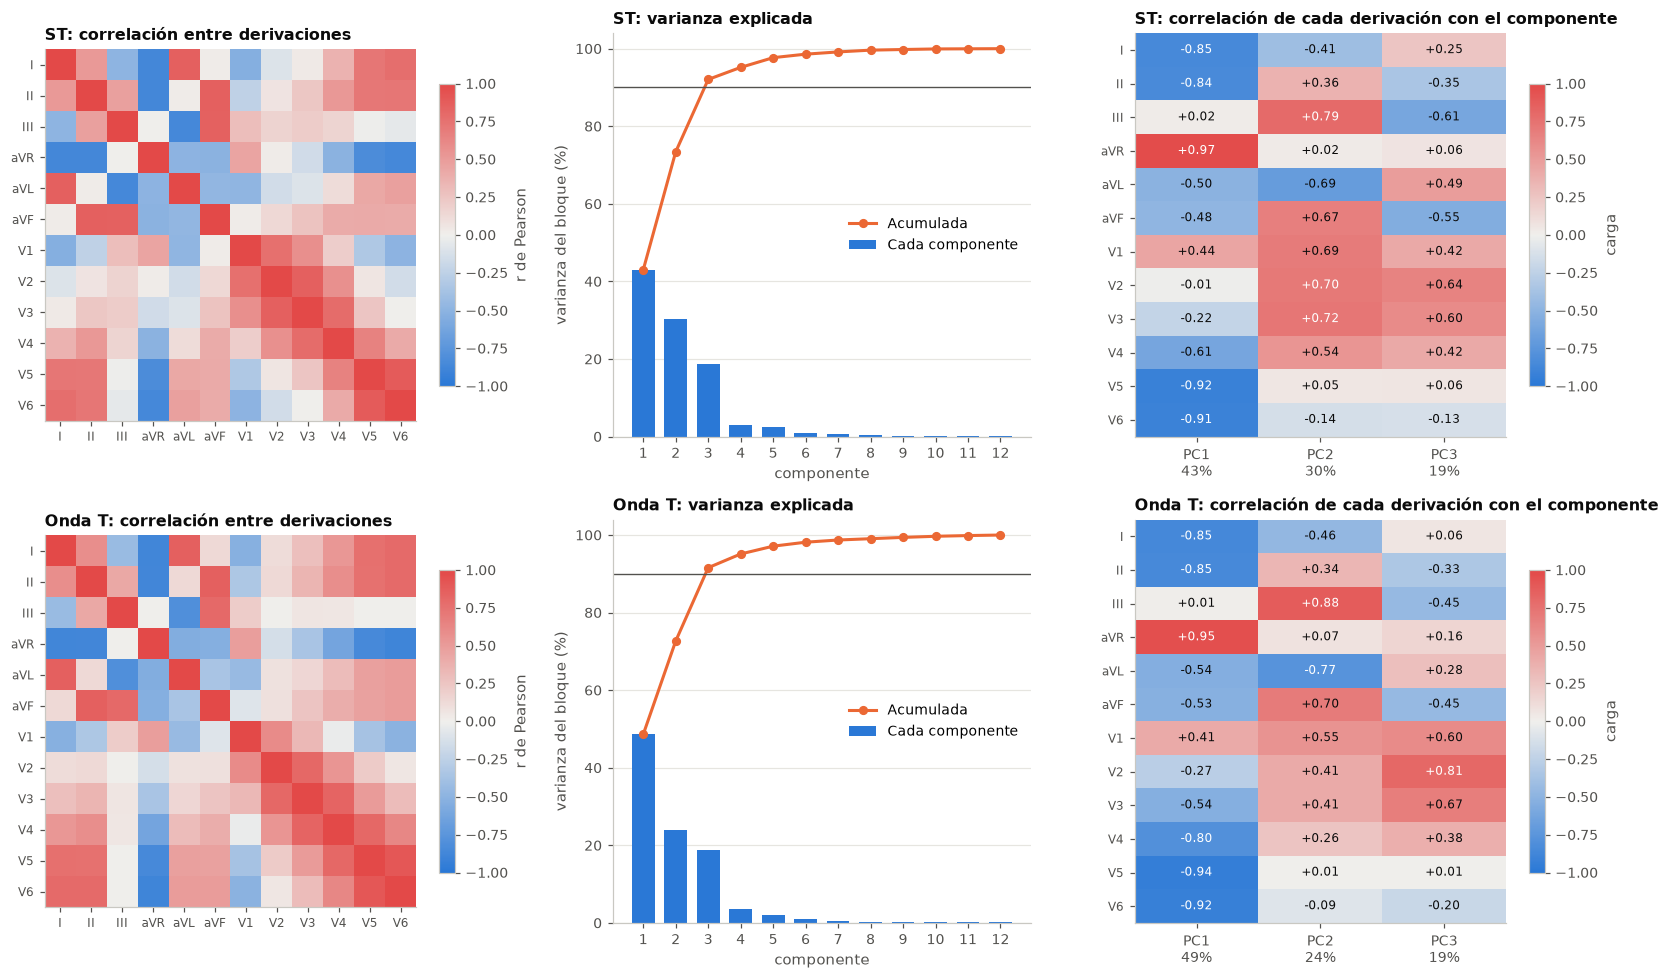

Componentes de los nueve bloques: 44 | con efecto de al menos 0.01 en algún objetivo: 37


objetivo,Cardiopatía,MI,STTC,CD,HYP
st_pc1,0.115,0.016,0.201,0.001,0.080
st_pc2,0.011,0.006,0.005,0.047,0.008
st_pc3,0.005,0.012,0.001,0.005,0.003
t_amp_pc1,0.257,0.099,0.264,0.023,0.056
t_amp_pc2,0.000,0.000,0.001,0.005,0.009
t_amp_pc3,0.002,0.000,0.001,0.000,0.018


Mayor efecto de un componente: t_amp_pc1 = 0.264 | mayor efecto de una variable original: axis_class = 0.278


In [33]:
BLOCKS = {"ST": "st", "Onda T": "t_amp", "Área del QRS": "qrs_area", "Onda R": "r_amp", "Onda S": "s_depth", "Onda Q": "q_depth",
          "Desviación estándar": "std", "Pico a pico": "ptp", "Curtosis": "kurt"}
BLOCK_LEVEL = 0.90
block_models, block_scores, block_rows = {}, [], []
for name, prefix in BLOCKS.items():
    columns = [f"{prefix}_{lead}" for lead in LEADS]
    block_scaler = StandardScaler().set_output(transform="pandas").fit(X_clean.loc[train, columns])
    scaled = block_scaler.transform(X_clean[columns])
    full = PCA().fit(scaled.loc[train])
    cumulative_block = np.cumsum(full.explained_variance_ratio_)
    k = int(np.searchsorted(cumulative_block, BLOCK_LEVEL) + 1)
    model = PCA(n_components=k).fit(scaled.loc[train])
    names = [f"{prefix}_pc{i}" for i in range(1, k + 1)]
    block_scores.append(pd.DataFrame(model.transform(scaled), index=scaled.index, columns=names))
    block_models[name] = {"columns": columns, "scaler": block_scaler, "pca": model, "full": full, "scaled": scaled, "names": names}
    block_rows.append({"bloque": name, "variables": len(columns), "varianza_con_3_%": 100 * cumulative_block[2], "varianza_con_8_%": 100 * cumulative_block[7],
                       f"componentes_para_{int(100 * BLOCK_LEVEL)}%": k, "seleccionadas_por_filtros": len([c for c in columns if c in selected])})
block_table = pd.DataFrame(block_rows).set_index("bloque")
block_scores = pd.concat(block_scores, axis=1)
display(block_table)

fig, axes = plt.subplots(2, 3, figsize=(15, 9), width_ratios=[1, 0.9, 1])
for row, name in enumerate(["ST", "Onda T"]):
    info = block_models[name]
    ax = axes[row, 0]
    image = ax.imshow(info["scaled"].loc[train].corr(), cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(12), LEADS, fontsize=8)
    ax.set_yticks(range(12), LEADS, fontsize=8)
    ax.grid(False)
    ax.set_title(f"{name}: correlación entre derivaciones")
    fig.colorbar(image, ax=ax, shrink=0.75, label="r de Pearson")
    ax = axes[row, 1]
    ratio = 100 * info["full"].explained_variance_ratio_
    ax.bar(range(1, 13), ratio, width=0.7, color=BLUE, label="Cada componente")
    ax.plot(range(1, 13), np.cumsum(ratio), "o-", color=ORANGE, markersize=5, label="Acumulada")
    ax.axhline(100 * BLOCK_LEVEL, color=MUTED, linewidth=0.9)
    ax.set(xlabel="componente", ylabel="varianza del bloque (%)", title=f"{name}: varianza explicada", xticks=range(1, 13), ylim=(0, 104))
    ax.grid(axis="x", visible=False)
    ax.legend(loc="center right")
    ax = axes[row, 2]
    loadings_block = pd.DataFrame(info["pca"].components_[:4].T * np.sqrt(info["pca"].explained_variance_[:4]), index=LEADS, columns=[f"PC{i}" for i in range(1, min(4, len(info["names"])) + 1)])
    image = ax.imshow(loadings_block, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(loadings_block.shape[1]), [f"{c}\n{v:.0f}%" for c, v in zip(loadings_block.columns, ratio)])
    ax.set_yticks(range(12), LEADS, fontsize=8)
    for i in range(12):
        for j in range(loadings_block.shape[1]):
            value = loadings_block.iat[i, j]
            ax.text(j, i, f"{value:+.2f}", ha="center", va="center", fontsize=8, color="white" if abs(value) > 0.7 else INK)
    ax.grid(False)
    ax.set_title(f"{name}: correlación de cada derivación con el componente")
    fig.colorbar(image, ax=ax, shrink=0.75, label="carga")
plt.tight_layout()
plt.show()

component_tests = []
for target_name, target in TARGETS.items():
    f_value, p_value = f_classif(block_scores.loc[first_ecg], target.loc[first_ecg])
    component_tests += [{"variable": c, "objetivo": target_name, "p": p, "efecto": f / (f + len(first_ecg) - 2)} for c, f, p in zip(block_scores.columns, f_value, p_value)]
component_tests = pd.DataFrame(component_tests)
component_tests["q"] = stats.false_discovery_control(component_tests.p.clip(lower=1e-300), method="bh")
component_tests["relevante"] = (component_tests.q < 0.05) & (component_tests.efecto >= EFFECT_MIN)
component_effect = component_tests.pivot(index="variable", columns="objetivo", values="efecto").loc[block_scores.columns, list(TARGETS)]
relevant_components = [c for c in block_scores.columns if component_tests[component_tests.variable == c].relevante.any()]
print(f"Componentes de los nueve bloques: {block_scores.shape[1]} | con efecto de al menos {EFFECT_MIN} en algún objetivo: {len(relevant_components)}")
display(component_effect.loc[[c for c in block_scores.columns if c.startswith(("st_pc", "t_amp_pc"))]].round(3))
print(f"Mayor efecto de un componente: {component_effect.max(axis=1).idxmax()} = {component_effect.max().max():.3f} | "
      f"mayor efecto de una variable original: {relevance.efecto_max.idxmax()} = {relevance.efecto_max.max():.3f}")

El PCA recupera desde los datos la dimensión que predice la física:

- En el ST, la onda T y el área del QRS, tres componentes reúnen más del 90% de la varianza (92.1%, 91.6% y 90.9%) y ocho reúnen más del 99%. Son las medidas que dependen casi linealmente de la señal, y se comportan como un vector en tres dimensiones visto desde 12 ángulos.
- Los demás bloques necesitan de 5 a 7 componentes. La altura de la R, la profundidad de la S o la curtosis son máximos y resúmenes no lineales de cada derivación, y tres componentes solo reúnen entre el 66% y el 74%.
- Los componentes se leen anatómicamente. En el ST, el primero (43% de la varianza) es el nivel del ST en la cara lateral (I, II, V5 y V6, con aVR en espejo); el segundo (30%) agrupa las derivaciones inferiores (III, aVF) y anteriores (V1 a V3) frente a aVL; el tercero (19%) opone las anteriores a las inferiores. En la onda T aparece la misma estructura.

Las 108 columnas de los nueve bloques se resumen en 44 componentes, y 37 superan la prueba de relevancia. El primer componente de la onda T (`t_amp_pc1`) tiene un efecto de 0.257 frente al objetivo binario y de 0.264 frente a `STTC`, casi el de la mejor variable original (`axis_class`, 0.278): una sola columna resume la amplitud y la polaridad de la T en las 12 derivaciones.

### PCA global

Como contraste, ajustamos un solo PCA sobre las 96 características continuas que dejaron los filtros. Revisamos cuántos componentes hacen falta, qué significan los primeros y cuánta señal útil lleva cada uno.

PCA sobre 96 características continuas seleccionadas y estandarizadas de train
Componentes necesarios: 80% de la varianza: 18 | 90% de la varianza: 31 | 95% de la varianza: 44 | 99% de la varianza: 69
Autovalores mayores que 1: 20


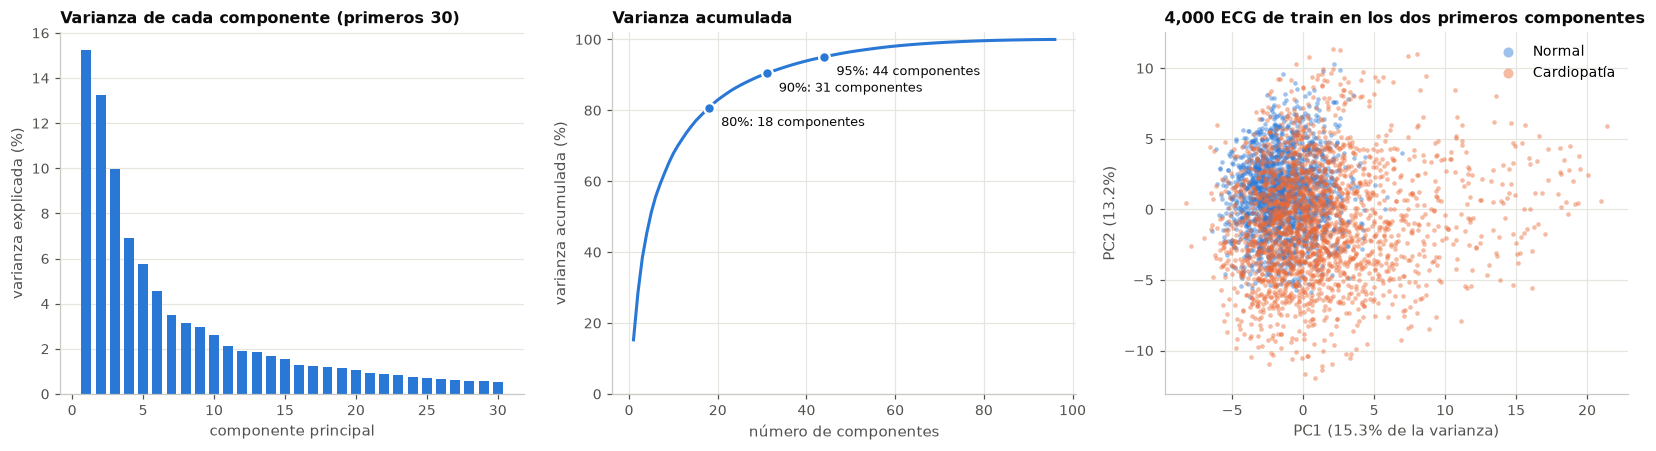

,PC1,PC2,PC3,PC4,PC5
0,cornell_product_mvms (+0.19),qrs_area_II (+0.23),st_V5 (+0.25),s_depth_I (+0.21),s_depth_III (+0.26)
1,qrs_area_V2 (-0.18),r_amp_II (+0.23),st_aVR (-0.25),std_II (+0.20),qrs_area_III (-0.24)
2,std_V2 (+0.18),s_depth_aVR (+0.23),t_amp_V5 (+0.24),s_depth_aVL (+0.20),std_I (+0.23)
3,qrs_area_V1 (-0.17),sokolow_lyon_mv (+0.22),t_amp_V4 (+0.24),std_aVF (+0.20),std_aVL (+0.21)
4,st_max_mv (+0.17),qrs_area_aVR (-0.22),t_amp_aVR (-0.23),s_depth_V6 (+0.20),q_depth_aVL (+0.21)
5,qrs_area_V3 (-0.17),qrs_area_V6 (+0.21),st_V4 (+0.23),r_amp_aVR (+0.20),qrs_area_I (+0.20)
varianza_%,15.3,13.2,10.0,6.9,5.7
AUROC_train_del_componente,0.686,0.661,0.731,0.603,0.505


In [34]:
pca_columns = [c for c in numeric_kept if c in continuous]
pca = PCA().fit(Z.loc[train, pca_columns])
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
needed = {level: int(np.searchsorted(cumulative, level) + 1) for level in (0.80, 0.90, 0.95, 0.99)}
print(f"PCA sobre {len(pca_columns)} características continuas seleccionadas y estandarizadas de train")
print("Componentes necesarios: " + " | ".join(f"{int(100 * level)}% de la varianza: {n}" for level, n in needed.items()))
print(f"Autovalores mayores que 1: {int((pca.explained_variance_ > 1).sum())}")

scores = pd.DataFrame(pca.transform(Z[pca_columns])[:, :2], index=Z.index, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].bar(range(1, 31), 100 * explained[:30], width=0.7, color=BLUE)
axes[0].set(xlabel="componente principal", ylabel="varianza explicada (%)", title="Varianza de cada componente (primeros 30)")
axes[0].grid(axis="x", visible=False)
axes[1].plot(range(1, len(cumulative) + 1), 100 * cumulative, color=BLUE)
for level, n in needed.items():
    if level < 0.99:
        axes[1].plot([n], [100 * cumulative[n - 1]], "o", color=BLUE, markersize=7, markeredgecolor="white", markeredgewidth=1.5)
        axes[1].annotate(f"{int(100 * level)}%: {n} componentes", (n, 100 * cumulative[n - 1]), xytext=(8, -12), textcoords="offset points", fontsize=8.5, color=INK)
axes[1].set(xlabel="número de componentes", ylabel="varianza acumulada (%)", title="Varianza acumulada", ylim=(0, 102))
sample = scores.loc[train].sample(4000, random_state=SEED)
for value, color, label in [(0, BLUE, "Normal"), (1, ORANGE, "Cardiopatía")]:
    part = sample[y.loc[sample.index] == value]
    axes[2].scatter(part.PC1, part.PC2, s=9, color=color, alpha=0.45, linewidth=0, label=label)
axes[2].set(xlabel=f"PC1 ({100 * explained[0]:.1f}% de la varianza)", ylabel=f"PC2 ({100 * explained[1]:.1f}%)", title="4,000 ECG de train en los dos primeros componentes")
axes[2].legend(markerscale=2.2)
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca.components_[:5].T, index=pca_columns, columns=[f"PC{i}" for i in range(1, 6)])
top_loadings = pd.DataFrame({
    pc: [f"{name} ({loadings.loc[name, pc]:+.2f})" for name in loadings[pc].abs().sort_values(ascending=False).head(6).index] for pc in loadings
})
top_loadings.loc["varianza_%"] = [f"{100 * v:.1f}" for v in explained[:5]]
top_loadings.loc["AUROC_train_del_componente"] = [f"{max(a, 1 - a):.3f}" for a in (roc_auc_score(y[train], pca.transform(Z.loc[train, pca_columns])[:, i]) for i in range(5))]
with pd.option_context("display.max_colwidth", 60):
    display(top_loadings)

Hacen falta 18 componentes para reunir el 80% de la varianza, 31 para el 90% y 44 para el 95%: menos de la mitad de las 96 columnas conserva casi toda la variación. La curva no tiene un codo marcado, así que no hay un número "natural" de componentes; en la sección 13 evaluamos 31 y 44.

Dos observaciones:

- Los componentes mezclan familias. El primero combina el producto de Cornell, áreas del QRS, la amplitud en V2 y el ST máximo. No se puede nombrar como los de un bloque.
- Varianza no es utilidad. Como predictor único, PC3 separa las clases mejor (AUROC 0.731) que PC1 (0.686) y PC2 (0.661), pese a tener menos varianza. El PCA ordena por cuánto varían los ECG, no por cuánto distinguen enfermos de sanos; por eso recortar componentes puede tirar información útil.

En la proyección, las clases se solapan casi por completo.

### Análisis factorial

A diferencia del PCA, el análisis factorial separa lo que varias variables comparten (los factores comunes) de lo que es propio de cada una, y con una rotación varimax cada factor queda asociado a pocas variables, lo que lo hace más fácil de nombrar.

Primero comprobamos que los datos se prestan a ello con dos pruebas. La esfericidad de Bartlett pregunta si las correlaciones son, en conjunto, distintas de cero. El índice KMO va de 0 a 1 y por encima de 0.8 indica que las correlaciones se explican bien con factores comunes. El número de factores se decide con dos criterios: Kaiser (autovalores mayores que 1) y el análisis paralelo, que conserva los factores cuyo autovalor supera al que se obtiene con datos aleatorios del mismo tamaño.

Esfericidad de Bartlett: chi2 = 2,434,944 con 4,560 gl, p = 0.0e+00
KMO global: 0.858 | variables con KMO < 0.6: []


Factores sugeridos: Kaiser (autovalor > 1) 20 | análisis paralelo 19


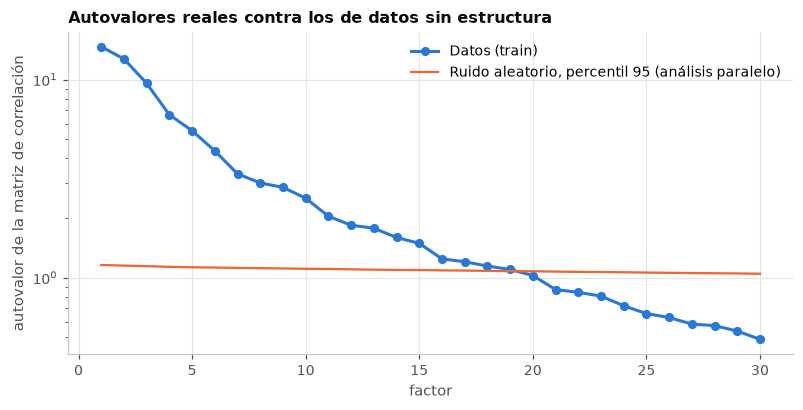

In [35]:
R = np.corrcoef(Z.loc[train, pca_columns].to_numpy(), rowvar=False)
n_obs, p = int(train.sum()), R.shape[0]
bartlett_chi2 = -(n_obs - 1 - (2 * p + 5) / 6) * np.linalg.slogdet(R)[1]
bartlett_dof = p * (p - 1) // 2
inverse = np.linalg.inv(R)
partial = -inverse / np.sqrt(np.outer(np.diag(inverse), np.diag(inverse)))
np.fill_diagonal(partial, 0)
off_diagonal = R - np.eye(p)
kmo_total = (off_diagonal ** 2).sum() / ((off_diagonal ** 2).sum() + (partial ** 2).sum())
kmo_variable = pd.Series((off_diagonal ** 2).sum(axis=0) / ((off_diagonal ** 2).sum(axis=0) + (partial ** 2).sum(axis=0)), index=pca_columns)
print(f"Esfericidad de Bartlett: chi2 = {bartlett_chi2:,.0f} con {bartlett_dof:,} gl, p = {stats.chi2.sf(bartlett_chi2, bartlett_dof):.1e}")
print(f"KMO global: {kmo_total:.3f} | variables con KMO < 0.6: {list(kmo_variable[kmo_variable < 0.6].round(2).to_dict().items())}")

eigenvalues = np.sort(np.linalg.eigvalsh(R))[::-1]
rng = np.random.default_rng(SEED)
random_eigenvalues = np.array([np.sort(np.linalg.eigvalsh(np.corrcoef(rng.standard_normal((n_obs, p)), rowvar=False)))[::-1] for _ in range(20)])
random_p95 = np.percentile(random_eigenvalues, 95, axis=0)
n_kaiser, n_parallel = int((eigenvalues > 1).sum()), int((eigenvalues > random_p95).sum())
print(f"Factores sugeridos: Kaiser (autovalor > 1) {n_kaiser} | análisis paralelo {n_parallel}")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(range(1, 31), eigenvalues[:30], "o-", color=BLUE, markersize=5, label="Datos (train)")
ax.plot(range(1, 31), random_p95[:30], color=ORANGE, linewidth=1.5, label="Ruido aleatorio, percentil 95 (análisis paralelo)")
ax.set(xlabel="factor", ylabel="autovalor de la matriz de correlación", title="Autovalores reales contra los de datos sin estructura", yscale="log")
ax.legend()
plt.show()

Los datos son adecuados: Bartlett rechaza que las correlaciones sean nulas y el KMO global es 0.858, sin ninguna variable por debajo de 0.6. Kaiser sugiere 20 factores y el análisis paralelo 19; usamos 19, el criterio más exigente. En la figura, los autovalores reales cruzan la línea del ruido aleatorio entre el factor 19 y el 20.

19 factores con rotación varimax: explican 75.4% de la varianza | comunalidad media 0.75


,varianza_%,variables_con_carga_>=0.5,cargas_principales
F1,8.527,12,"st_V2 (+0.93), st_V3 (+0.83), st_dep_anterior_mv (+0.78), t_amp_V2 (+0.78), st_V1 (+0.74)"
F2,7.488,9,"st_aVR (-0.91), st_dep_lateral_mv (+0.87), st_V5 (+0.83), t_amp_aVR (-0.76), t_amp_V5 (+0.68)"
F3,6.352,7,"s_depth_III (+0.88), std_aVL (+0.87), qrs_area_III (-0.74), std_I (+0.70), s_depth_aVF (+0.63)"
F4,5.866,7,"kurt_aVR (-0.86), kurt_V6 (-0.82), kurt_I (-0.72), kurt_II (-0.71), hr_bpm (+0.56)"
F5,5.612,6,"r_amp_V6 (+0.89), std_V6 (+0.88), std_V5 (+0.83), sokolow_lyon_mv (+0.71), qrs_area_V6 (+0.67)"
F6,5.591,8,"s_depth_V3 (+0.90), s_depth_V4 (+0.80), cornell_product_mvms (+0.72), qrs_area_V3 (-0.67), s_depth_V2 (+0.62)"
F7,5.102,6,"std_aVR (-0.81), s_depth_aVR (-0.80), qrs_area_aVR (+0.73), qrs_area_II (-0.63), r_amp_II (-0.62)"
F8,4.082,5,"st_III (+0.95), st_elev_inferior_mv (+0.84), st_dep_inferior_mv (+0.79), st_aVL (-0.71), t_amp_aVF (+0.56)"
F9,3.928,4,"r_amp_aVR (+0.84), s_depth_II (+0.70), s_depth_V6 (+0.69), s_depth_V5 (+0.55), s_depth_I (+0.49)"
F10,3.528,3,"sp_low_rel (+0.79), sp_entropy (-0.73), noise_hf_frac (-0.52), qrs_dur_ms (+0.47), sp_mid_rel (-0.41)"


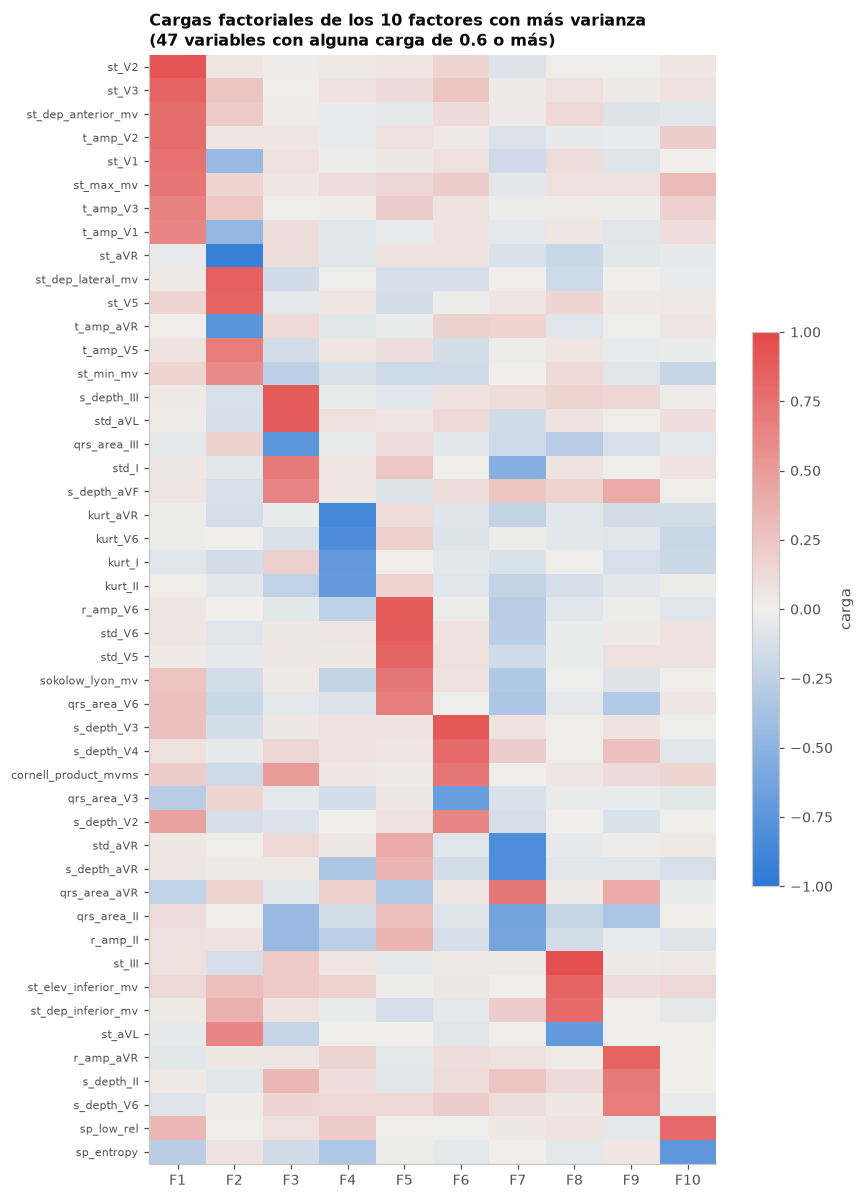

,pr_ms,pq_peak_ms,beat_similarity,q_depth_V3,qtc_bazett_ms,q_depth_V1,q_depth_V2,kurt_III,q_depth_aVL,noise_hf_frac,sp_mid_rel,kurt_aVL
comunalidad,0.078,0.185,0.201,0.244,0.325,0.338,0.365,0.396,0.417,0.423,0.437,0.463
familia,Intervalos,Intervalos,Ritmo,QRS: amplitud y eje,Intervalos,QRS: amplitud y eje,QRS: amplitud y eje,Estadísticos de la señal,QRS: amplitud y eje,Calidad,Espectro,Estadísticos de la señal


In [36]:
N_FACTORS = n_parallel
factor_model = FactorAnalysis(n_components=N_FACTORS, rotation="varimax", random_state=SEED).fit(Z.loc[train, pca_columns])
factor_loadings = pd.DataFrame(factor_model.components_.T, index=pca_columns)
order = (factor_loadings ** 2).sum().sort_values(ascending=False).index
factor_loadings = factor_loadings[order].set_axis([f"F{i}" for i in range(1, N_FACTORS + 1)], axis=1)
communality = (factor_loadings ** 2).sum(axis=1)
factor_variance = (factor_loadings ** 2).sum() / p
print(f"{N_FACTORS} factores con rotación varimax: explican {100 * factor_variance.sum():.1f}% de la varianza | comunalidad media {communality.mean():.2f}")

factor_table = pd.DataFrame({
    "varianza_%": 100 * factor_variance,
    "variables_con_carga_>=0.5": (factor_loadings.abs() >= 0.5).sum(),
    "cargas_principales": [", ".join(f"{name} ({factor_loadings.loc[name, f]:+.2f})" for name in factor_loadings[f].abs().sort_values(ascending=False).head(5).index)
                           for f in factor_loadings],
})
with pd.option_context("display.max_colwidth", 150):
    display(factor_table)

strong = factor_loadings[factor_loadings.iloc[:, :10].abs().max(axis=1) >= 0.6].iloc[:, :10]
strong = strong.loc[sorted(strong.index, key=lambda name: (int(strong.loc[name].abs().idxmax()[1:]), -strong.loc[name].abs().max()))]
fig, ax = plt.subplots(figsize=(8, 0.2 * len(strong) + 1.6))
image = ax.imshow(strong.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(strong.shape[1]), strong.columns)
ax.set_yticks(range(len(strong)), strong.index, fontsize=7.5)
ax.grid(False)
ax.set_title(f"Cargas factoriales de los 10 factores con más varianza\n({len(strong)} variables con alguna carga de 0.6 o más)")
fig.colorbar(image, ax=ax, shrink=0.5, label="carga")
plt.tight_layout()
plt.show()

unique = communality.sort_values().head(12)
display(pd.DataFrame({"comunalidad": unique, "familia": [family(c) for c in unique.index]}).T)

Los 19 factores explican el 75.4% de la varianza. Los 13 primeros agrupan variables de una misma región del corazón o de una misma onda, y se pueden nombrar:

| Factor | Varianza | Variables con mayor carga | Interpretación |
| --- | --- | --- | --- |
| F1 | 8.5% | ST y onda T en V1-V3 | Repolarización anterior |
| F2 | 7.5% | ST y T en aVR contra ST y T en V5 | Repolarización lateral |
| F3 | 6.4% | S en III y aVF, amplitud en aVL e I | Eje del QRS hacia la izquierda |
| F4 | 5.9% | Curtosis de varias derivaciones, frecuencia cardiaca | Proporción del registro que ocupan los QRS |
| F5 | 5.6% | R y amplitud en V5-V6, Sokolow-Lyon | Voltaje lateral |
| F6 | 5.6% | S en V2-V4, producto de Cornell | Voltaje precordial medio |
| F7 | 5.1% | Amplitud en aVR y II | Voltaje en el eje II-aVR |
| F8 | 4.1% | ST en III y en el territorio inferior contra ST en aVL | Repolarización inferior |
| F9 | 3.9% | R en aVR, S en II, V5 y V6 | Fuerzas terminales hacia la derecha |
| F10 | 3.5% | Potencia en baja frecuencia, entropía espectral, duración del QRS | Señal lenta, QRS ancho |
| F11 | 3.4% | Amplitud en aVF, II y III | Voltaje inferior |
| F12 | 3.2% | R en V2-V3, fracción de R en V1 | Onda R en las precordiales derechas |
| F13 | 2.7% | Q en aVF, II y III | Ondas Q inferiores |

Los seis restantes explican 2.3% o menos cada uno y los dos últimos no tienen ninguna carga de 0.5 o más.

Tenemos dos lecturas útiles:

- Los factores reproducen la anatomía. Sin conocer las etiquetas, el análisis separa la repolarización anterior (F1), lateral (F2) e inferior (F8), que son los tres territorios coronarios, y el voltaje lateral del inferior. Coincide con lo que mostró el PCA por bloques y respalda que esos componentes tienen significado clínico.
- No todo es compartido. Las comunalidades más bajas son las de `pr_ms` (0.078), `pq_peak_ms` (0.185), `beat_similarity` (0.201) y `qtc_bazett_ms` (0.325). La conducción auriculoventricular, la regularidad del ritmo y el QT corregido no pertenecen a ningún factor común: cada una aporta información propia que una representación hecha solo de factores perdería.

### Análisis factorial dentro de un bloque de derivaciones

La versión de Emiliano aplicó el análisis factorial a un solo bloque, el nivel del ST y la amplitud de la onda T en las 12 derivaciones, con tres factores (los mismos componentes que pide el PCA de ese bloque) y rotación varimax. Si los factores coinciden con los territorios del corazón (anterior, inferior y lateral) sin que se los indiquemos, eso respalda la lectura anatómica del PCA por bloques. La tabla marca con su carga las derivaciones que pesan al menos 0.5 en cada factor.

In [37]:
territory_of = {lead: name for name, leads in TERRITORIES.items() for lead in leads}
block_fa = {}
for name in ["ST", "Onda T"]:
    info = block_models[name]
    fa = FactorAnalysis(n_components=3, rotation="varimax", random_state=SEED).fit(info["scaled"].loc[train])
    loadings_fa = pd.DataFrame(fa.components_.T, index=LEADS, columns=["F1", "F2", "F3"])
    block_fa[name] = loadings_fa.where(loadings_fa.abs() >= 0.5).round(2).astype(object).fillna("")
    block_fa[name].insert(0, "territorio", [territory_of.get(lead, "(aVR)") for lead in LEADS])
display(pd.concat(block_fa, axis=1))

ST                       Onda T                  
    territorio    F1    F2    F3 territorio    F1    F2    F3
I      lateral       -0.88          lateral       -0.89      
II    inferior       -0.85         inferior       -0.86      
III   inferior  0.99               inferior              0.98
aVR      (aVR)        0.99            (aVR)        0.98      
aVL    lateral -0.84 -0.53          lateral       -0.57  -0.8
aVF   inferior  0.86               inferior       -0.52  0.83
V1    anterior              0.65   anterior        0.57      
V2    anterior               0.9   anterior -0.83            
V3    anterior              0.96   anterior -0.97            
V4    anterior              0.73   anterior -0.74 -0.53      
V5     lateral       -0.82          lateral       -0.82      
V6     lateral       -0.87          lateral        -0.9

Los tres factores de cada bloque coinciden con los territorios del corazón, sin habérselos indicado:

- En el ST, F1 reúne III y aVF, con aVL en sentido opuesto (cara inferior); F2 reúne I, II, V5 y V6, con aVR en espejo (cara lateral), y F3 reúne V1 a V4 (cara anterior).
- En la onda T aparece la misma división en otro orden: F1 reúne V2 a V4 (anterior), F2 las derivaciones laterales con aVR en espejo y F3 III y aVF con aVL opuesta (inferior).

Esto respalda la lectura anatómica de los componentes del PCA por bloques. Para el conjunto final se usa el PCA y no estos factores, porque la sección 13 muestra que el análisis factorial rinde menos como entrada de un modelo.

## 13. Comprobación de la reducción

Hay que comprobar si al reducir se pierde capacidad de distinguir ECG normales de ECG con cardiopatía, y si de verdad se gana en almacenamiento y en tiempo. Entrenamos la misma regresión logística con cada conjunto y medimos en validación:

- AUROC, con un intervalo de 95% obtenido remuestreando pacientes (no ECG), para respetar que algunos tienen varios registros.
- Especificidad a 95% y a 99% de sensibilidad. La de 99% lleva también su intervalo, porque depende de muy pocos ECG.
- Columnas, memoria, iteraciones y tiempo de ajuste.

,columnas,MB,AUROC_val,IC95_inf,IC95_sup,esp_a_sens_95,esp_a_sens_99,esp99_inf,esp99_sup,iteraciones,convergió,ajuste_s
conjunto,,,,,,,,,,,,
A. Resúmenes del Avance 1 (std y ptp por derivación),24,4.106,0.801,0.785,0.821,0.234,0.081,0.053,0.122,62,True,0.030
"B. Construidas, sin transformar ni escalar",163,27.889,0.927,0.917,0.937,0.585,0.303,0.224,0.393,12751,False,10.761
"C. Construidas, solo estandarizadas",163,27.889,0.928,0.918,0.938,0.598,0.332,0.295,0.373,144,True,0.125
"D. Construidas, transformadas y estandarizadas",163,27.889,0.930,0.920,0.939,0.561,0.323,0.236,0.436,160,True,0.127
E. Seleccionadas por filtros,111,18.992,0.929,0.919,0.938,0.566,0.324,0.260,0.395,118,True,0.078
F. PCA por bloques + seleccionadas fuera de los bloques,74,12.661,0.928,0.918,0.938,0.570,0.318,0.249,0.401,108,True,0.090
G. PCA global 95% (44 componentes) + no continuas,59,10.095,0.924,0.913,0.934,0.561,0.257,0.207,0.363,97,True,0.066
H. PCA global 90% (31 componentes) + no continuas,46,7.870,0.918,0.907,0.928,0.519,0.210,0.122,0.276,106,True,0.068
I. Análisis factorial (19 factores) + no continuas,34,5.817,0.908,0.896,0.919,0.472,0.181,0.093,0.237,46,True,0.030


Referencia no lineal (gradient boosting con las 111 seleccionadas): AUROC 0.944 | especificidad a 95% de sensibilidad 0.647 | a 99% 0.415
ECG de validación con medición fallida: 11 (11 con cardiopatía) | con el conjunto E quedan por encima del umbral de 95% de sensibilidad 10 y del de 99% 11


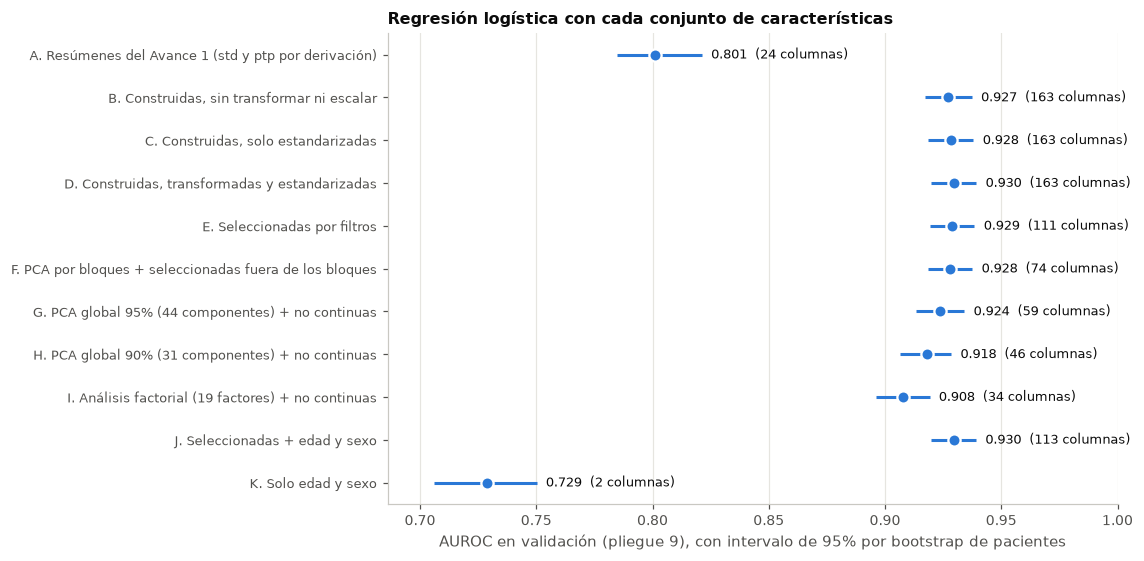

In [38]:
def patient_bootstrap(y_true: np.ndarray, score: np.ndarray, groups: np.ndarray, n_boot: int = 300) -> dict:
    """Intervalos de 95% del AUROC y de la especificidad a 99% de sensibilidad, remuestreando pacientes."""
    rng = np.random.default_rng(SEED)
    ids, inverse = np.unique(groups, return_inverse=True)
    members = [np.flatnonzero(inverse == i) for i in range(len(ids))]
    auroc, specificity = [], []
    for _ in range(n_boot):
        index = np.concatenate([members[i] for i in rng.integers(0, len(ids), len(ids))])
        auroc.append(roc_auc_score(y_true[index], score[index]))
        specificity.append(specificity_at(y_true[index], score[index], 0.99))
    return {"IC95_inf": np.percentile(auroc, 2.5), "IC95_sup": np.percentile(auroc, 97.5),
            "esp99_inf": np.percentile(specificity, 2.5), "esp99_sup": np.percentile(specificity, 97.5)}


SCORES = {}


def evaluate(name: str, table) -> dict:
    result = fit_logistic(table)
    SCORES[name] = result.pop("score")
    return {"conjunto": name, **result, "MB": np.asarray(table).shape[0] * np.asarray(table).shape[1] * 8 / 1e6,
            **patient_bootstrap(y[val].to_numpy(), SCORES[name], patient[val].to_numpy())}


block_columns = [c for info in block_models.values() for c in info["columns"]]
outside_blocks = [c for c in selected if c not in block_columns]
by_blocks = pd.concat([block_scores[relevant_components], ready[outside_blocks]], axis=1)
passthrough = [c for c in selected if c not in pca_columns]
simple_stats = [c for c in continuous if c.startswith(("std_", "ptp_"))]
components = {level: PCA(n_components=n).fit(Z.loc[train, pca_columns]) for level, n in needed.items() if level in (0.90, 0.95)}
factor_scores = factor_model.transform(Z[pca_columns])
not_continuous = [c for c in ready.columns if c not in continuous]
only_standardized = np.hstack([StandardScaler().fit(X_clean.loc[train, continuous]).transform(X_clean[continuous]), ready[not_continuous]])

SETS = {
    "A. Resúmenes del Avance 1 (std y ptp por derivación)": Z[simple_stats],
    "B. Construidas, sin transformar ni escalar": before_scaling,
    "C. Construidas, solo estandarizadas": only_standardized,
    "D. Construidas, transformadas y estandarizadas": ready,
    "E. Seleccionadas por filtros": ready[selected],
    "F. PCA por bloques + seleccionadas fuera de los bloques": by_blocks,
    f"G. PCA global 95% ({needed[0.95]} componentes) + no continuas": np.hstack([components[0.95].transform(Z[pca_columns]), ready[passthrough]]),
    f"H. PCA global 90% ({needed[0.90]} componentes) + no continuas": np.hstack([components[0.90].transform(Z[pca_columns]), ready[passthrough]]),
    f"I. Análisis factorial ({N_FACTORS} factores) + no continuas": np.hstack([factor_scores, ready[passthrough]]),
    "J. Seleccionadas + edad y sexo": pd.concat([ready[selected], metadata_block], axis=1),
    "K. Solo edad y sexo": metadata_block,
}
results = pd.DataFrame([evaluate(name, table) for name, table in SETS.items()]).set_index("conjunto")
display(results[["columnas", "MB", "AUROC_val", "IC95_inf", "IC95_sup", "esp_a_sens_95", "esp_a_sens_99", "esp99_inf", "esp99_sup", "iteraciones", "convergió", "ajuste_s"]])

boosting = HistGradientBoostingClassifier(random_state=SEED).fit(ready.loc[train, selected], y[train])
boosting_score = boosting.predict_proba(ready.loc[val, selected])[:, 1]
print(f"Referencia no lineal (gradient boosting con las {len(selected)} seleccionadas): AUROC {roc_auc_score(y[val], boosting_score):.3f} | "
      f"especificidad a 95% de sensibilidad {specificity_at(y[val], boosting_score, 0.95):.3f} | a 99% {specificity_at(y[val], boosting_score, 0.99):.3f}")
failed_val = (binary.flag_medicion_fallida[val] == 1).to_numpy()
score_selected = SCORES["E. Seleccionadas por filtros"]
cut_95, cut_99 = (np.quantile(score_selected[(y[val] == 1).to_numpy()], q) for q in (0.05, 0.01))
print(f"ECG de validación con medición fallida: {int(failed_val.sum())} ({int(y[val].to_numpy()[failed_val].sum())} con cardiopatía) | con el conjunto E quedan por encima del "
      f"umbral de 95% de sensibilidad {int((score_selected[failed_val] >= cut_95).sum())} y del de 99% {int((score_selected[failed_val] >= cut_99).sum())}")

shown = results[::-1]
fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.hlines(range(len(shown)), shown.IC95_inf, shown.IC95_sup, color=BLUE, linewidth=2)
ax.plot(shown.AUROC_val, range(len(shown)), "o", color=BLUE, markersize=8, markeredgecolor="white", markeredgewidth=1.5)
for i, (auc, n) in enumerate(zip(shown.AUROC_val, shown.columnas)):
    ax.text(shown.IC95_sup.iloc[i] + 0.004, i, f"{auc:.3f}  ({n} columnas)", va="center", fontsize=8.5, color=INK)
ax.set_yticks(range(len(shown)), shown.index, fontsize=8.5)
ax.set(xlabel="AUROC en validación (pliegue 9), con intervalo de 95% por bootstrap de pacientes", xlim=(shown.IC95_inf.min() - 0.02, 1.0),
       title="Regresión logística con cada conjunto de características")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

¿Qué vemos en la tabla y en la gráfica?

- Construcción (A contra D). Los dos resúmenes por derivación del Avance 1 dan un AUROC de 0.801; las características construidas, 0.930. Es el salto más grande de la tabla, y a 99% de sensibilidad la especificidad pasa de 0.081 a 0.323. El conocimiento clínico puesto en las características vale mucho más que cualquier paso posterior.
- Escalamiento (B contra C). Prácticamente el mismo AUROC (0.927 y 0.928), pero sin escalar el optimizador hace 12,751 iteraciones sin converger y estandarizado converge en 144.
- Transformación (C contra D). El AUROC pasa de 0.928 a 0.930, dentro del intervalo de confianza. Se confirma lo dicho en la sección 10: Yeo-Johnson se justifica por las pruebas estadísticas, no por la métrica.
- Selección por filtros (D contra E). Con 52 columnas menos (de 163 a 111, de 27.9 a 19.0 MB) el AUROC pasa de 0.930 a 0.929 y el optimizador necesita una cuarta parte menos de iteraciones (118 contra 160).
- PCA por bloques (F). Con 74 columnas (12.7 MB, menos de la mitad que la matriz completa) el AUROC es 0.928 y la especificidad a 95% de sensibilidad 0.570, casi igual que la del conjunto E (0.566).
- PCA global (G y H). Comprime más y pierde más: 0.924 con 59 columnas y 0.918 con 46. El intervalo de H (0.907 a 0.928) ya no alcanza el valor del conjunto E.
- Análisis factorial (I). Es la representación más compacta (34 columnas) y más fácil de nombrar, y la de menor rendimiento (0.908). Sirve para explicar, no para sustituir a las características.
- Edad y sexo (J y K). Añadirlos a las seleccionadas cambia el AUROC de 0.929 a 0.930. Solos alcanzan 0.729 y no descartan casi a ningún ECG normal con 99% de sensibilidad (0.005). Se dejan fuera sin pérdida, lo que respalda la decisión de la sección 3.
- Referencia no lineal. Un gradient boosting con las mismas 111 columnas alcanza 0.944: las características contienen más información de la que una frontera lineal aprovecha.

Los ECG con medición fallida no se pierden. En validación hay 11 y todos tienen cardiopatía. Con el conjunto E los 11 quedan por encima del umbral de 99% de sensibilidad y 10 por encima del de 95%: imputar la mediana en el intervalo que falló no los hace pasar por normales, porque el resto de sus características sigue siendo anormal.

Nota importante. La especificidad a 99% de sensibilidad es muy incierta con 2,146 ECG de validación: para el conjunto E el intervalo va de 0.260 a 0.395, y los de D, F y G se solapan con él. No permite ordenar esos conjuntos. Lo que sí dice es que detectar el 99% de las cardiopatías cuesta caro con cualquiera de ellos: con una especificidad cercana a 0.33, dos de cada tres ECG normales recibirían una alerta. La ingeniería de características deja ese punto de partida medido; mejorarlo es tarea de la fase de modelado.

### Las cinco superclases del Avance 1

En el Avance 1 tratamos la etiqueta como un problema multietiqueta con cinco superclases (`NORM`, `MI`, `STTC`, `CD` y `HYP`). Para comprobar que la selección y la extracción no pierden información de ninguna de ellas, repetimos la comparación con una regresión logística por superclase y medimos el AUROC de cada una en validación. El promedio de las cinco es el AUROC macro.

In [39]:
def superclass_auroc(table) -> dict:
    """AUROC en validación de una regresión logística por superclase, ajustada en train."""
    table = np.asarray(table, dtype=float)
    fit_rows, val_rows = train.to_numpy(), val.to_numpy()
    aurocs = {}
    for name in SUPERCLASSES:
        target = meta.loc[rows, name].to_numpy()
        model = LogisticRegression(max_iter=20000, random_state=SEED).fit(table[fit_rows], target[fit_rows])
        aurocs[name] = roc_auc_score(target[val_rows], model.predict_proba(table[val_rows])[:, 1])
    aurocs["macro"] = float(np.mean([aurocs[name] for name in SUPERCLASSES]))
    return aurocs


multilabel = pd.DataFrame({name: superclass_auroc(table) for name, table in SETS.items() if name[0] != "B"}).T
multilabel.insert(0, "columnas", results.columnas.loc[multilabel.index].astype(int))
display(multilabel)

,columnas,NORM,MI,STTC,CD,HYP,macro
A. Resúmenes del Avance 1 (std y ptp por derivación),24,0.809,0.782,0.740,0.803,0.854,0.798
"C. Construidas, solo estandarizadas",163,0.929,0.897,0.909,0.904,0.883,0.904
"D. Construidas, transformadas y estandarizadas",163,0.932,0.901,0.911,0.904,0.893,0.908
E. Seleccionadas por filtros,111,0.932,0.899,0.909,0.903,0.887,0.906
F. PCA por bloques + seleccionadas fuera de los bloques,74,0.932,0.885,0.911,0.893,0.882,0.901
G. PCA global 95% (44 componentes) + no continuas,59,0.926,0.891,0.904,0.903,0.871,0.899
H. PCA global 90% (31 componentes) + no continuas,46,0.921,0.888,0.904,0.898,0.870,0.896
I. Análisis factorial (19 factores) + no continuas,34,0.914,0.883,0.894,0.877,0.862,0.886
J. Seleccionadas + edad y sexo,113,0.933,0.899,0.909,0.903,0.888,0.906
K. Solo edad y sexo,2,0.773,0.699,0.679,0.660,0.645,0.691


Con las cinco superclases se repite lo que vimos con el objetivo binario:

- Construcción (A contra D). El AUROC macro pasa de 0.798 con los resúmenes del Avance 1 a 0.908 con las características construidas, y mejoran las cinco superclases. La mayor ganancia es en `STTC` (de 0.740 a 0.911), porque los resúmenes globales no describen el segmento ST ni la onda T. La menor es en `HYP` (de 0.854 a 0.893), porque la amplitud de la señal, que ya medían los resúmenes, es justo lo que cambia en la hipertrofia.
- Selección por filtros (E). Con 52 columnas menos el AUROC macro queda en 0.906, y ninguna superclase baja más de 0.006.
- PCA por bloques (F). Llega a 0.901 y pierde sobre todo en `MI` (0.885 contra 0.899 del conjunto E) y en `CD` (0.893 contra 0.903).
- Análisis factorial (I). Vuelve a quedar último (0.886).
- Edad y sexo. No cambian el AUROC macro de las seleccionadas (0.906 con y sin ellas), aunque solos alcanzan 0.691.

Por eso el conjunto seleccionado por filtros es la entrada principal para la fase de modelado, y el PCA por bloques es su versión compacta.

### Con 2,000 etiquetas

El conjunto del proyecto tendrá muchas menos etiquetas que PTB-XL: del orden de 2,000 ECG etiquetados. ¿Importa más reducir cuando hay pocas etiquetas? Repetimos la comparación entrenando con 20 muestras aleatorias de 2,000 ECG de entrenamiento y midiendo en el mismo pliegue de validación.

Una advertencia sobre el alcance. Los pasos que no usan la etiqueta (imputación, transformación, escalamiento, correlación y PCA) se ajustaron con todo el entrenamiento, como se podrá hacer con los ECG sin etiquetar del proyecto. La prueba de relevancia sí usó todas las etiquetas, así que la comparación es algo optimista para los conjuntos reducidos.

In [40]:
N_LABELS, REPEATS = 2000, 20
train_positions = np.flatnonzero(train.to_numpy())
rng = np.random.default_rng(SEED)
subsets = [rng.choice(train_positions, N_LABELS, replace=False) for _ in range(REPEATS)]
few, reference = [], None
for name in [k for k in SETS if k[0] in "DEFGI"]:
    runs = pd.DataFrame([fit_logistic(SETS[name], fit_rows=subset) for subset in subsets])
    reference = runs if reference is None else reference
    full = results.loc[name]
    few.append({"conjunto": name, "columnas": int(full.columnas), "AUROC_todas": full.AUROC_val, f"AUROC_{N_LABELS}": runs.AUROC_val.mean(), "desv": runs.AUROC_val.std(),
                "muestras_en_que_supera_a_D": int((runs.AUROC_val > reference.AUROC_val).sum()),
                "esp95_todas": full.esp_a_sens_95, f"esp95_{N_LABELS}": runs.esp_a_sens_95.mean(), "esp99_todas": full.esp_a_sens_99, f"esp99_{N_LABELS}": runs.esp_a_sens_99.mean()})
few = pd.DataFrame(few).set_index("conjunto")
print(f"Media de {REPEATS} muestras de {N_LABELS:,} ECG de train con etiqueta; medición en el mismo pliegue de validación")
display(few)

Media de 20 muestras de 2,000 ECG de train con etiqueta; medición en el mismo pliegue de validación


,columnas,AUROC_todas,AUROC_2000,desv,muestras_en_que_supera_a_D,esp95_todas,esp95_2000,esp99_todas,esp99_2000
conjunto,,,,,,,,,
"D. Construidas, transformadas y estandarizadas",163,0.930,0.916,0.004,0,0.561,0.519,0.323,0.242
E. Seleccionadas por filtros,111,0.929,0.919,0.004,20,0.566,0.525,0.324,0.259
F. PCA por bloques + seleccionadas fuera de los bloques,74,0.928,0.921,0.003,19,0.570,0.543,0.318,0.261
G. PCA global 95% (44 componentes) + no continuas,59,0.924,0.917,0.003,9,0.561,0.529,0.257,0.254
I. Análisis factorial (19 factores) + no continuas,34,0.908,0.903,0.003,0,0.472,0.453,0.181,0.154


Con 2,000 etiquetas todos los conjuntos pierden, pero no lo mismo. La matriz completa (D) baja de 0.930 a 0.916; las seleccionadas por filtros (E), de 0.929 a 0.919; el PCA por bloques (F), de 0.928 a 0.921. El orden se invierte: con todas las etiquetas D quedaba ligeramente arriba y con 2,000 queda abajo. E supera a D en las 20 muestras y F en 19. En la especificidad a 95% de sensibilidad pasa lo mismo: 0.519 para D, 0.525 para E y 0.543 para F.

Las diferencias son pequeñas (la desviación entre muestras es de 0.003 a 0.004) pero consistentes. Reducir no mejora el modelo cuando sobran etiquetas; lo protege cuando faltan, que es la situación del proyecto.

## 14. Archivos de la fase

Guardamos lo necesario para que la fase de modelado no tenga que repetir este notebook y para aplicar exactamente la misma preparación a datos nuevos: la tabla de características seleccionadas (con el objetivo binario y las cinco superclases), su versión compacta con PCA por bloques, los transformadores ajustados con entrenamiento, la lista de variables finales con su efecto y el registro de qué se eliminó en cada filtro y con qué umbral. Antes de guardar se comprueba que ningún metadato quedó entre los predictores. La carpeta `outputs/` no se versiona en Git.

In [41]:
identifiers = meta.loc[rows, ["patient_id", "strat_fold", "split", "target"] + SUPERCLASSES]
final = pd.concat([identifiers, ready[selected], metadata_block], axis=1)
compact = pd.concat([identifiers, by_blocks], axis=1)
forbidden = {"report", "scp_codes", "heart_axis", "infarction_stadium1", "infarction_stadium2", "device", "site", "nurse", "validated_by_human", "age", "sex"}
for table in (ready[selected], by_blocks):
    assert forbidden.isdisjoint(table.columns), "Hay una columna de metadatos entre los predictores"
    assert np.isfinite(table.to_numpy(dtype=float)).all()
final.to_csv(OUT / "ptbxl_caracteristicas_seleccionadas.csv", float_format="%.5g")
compact.to_csv(OUT / "ptbxl_pca_por_bloques.csv", float_format="%.5g")

dictionary = relevance.loc[[c if c in relevance.index else next(v for v, encoded in encoded_of.items() if c in encoded) for c in selected],
                           ["familia", "prueba", "efecto_max", "objetivo_max"]].reset_index(names="evaluada_como")
dictionary.insert(0, "variable", selected)
dictionary.to_csv(OUT / "variables_finales.csv", index=False)

joblib.dump({
    "imputer": imputer, "winsor_lower": lower, "winsor_upper": upper, "continuous": continuous, "to_transform": to_transform,
    "power_scale": power_scale, "power": power, "scaler": scaler, "ordinal_encoder": ordinal_encoder, "ordinal_scaler": ordinal_scaler,
    "onehot_encoder": onehot_encoder, "selected": selected,
    "block_pca": {name: {k: info[k] for k in ("columns", "scaler", "pca", "names")} for name, info in block_models.items()},
    "relevant_components": relevant_components, "pca_95": components[0.95], "pca_columns": pca_columns, "factor_model": factor_model,
}, OUT / "transformadores_ajustados_en_train.joblib")
(OUT / "seleccion.json").write_text(json.dumps({
    "dataset": "PTB-XL 1.0.3", "python": platform.python_version(), "versiones": VERSIONS, "codigo_extraccion_sha256_10": code_hash,
    "particion": {"train": "pliegues 1-8", "val": "pliegue 9", "test": "pliegue 10"}, "ecg": split.value_counts().to_dict(),
    "seleccionadas": selected, "eliminadas_varianza": low_variance, "eliminadas_relevancia": irrelevant + weak,
    "eliminadas_correlacion": {k: v[0] for k, v in redundant.items()}, "componentes_por_bloque": relevant_components,
    "umbrales": {"plausibilidad_ms": PLAUSIBLE, "sesgo": SKEW_MIN, "varianza": THRESHOLD_VARIANCE, "efecto": EFFECT_MIN,
                 "correlacion": THRESHOLD_CORRELATION, "varianza_por_bloque": BLOCK_LEVEL},
}, indent=2, ensure_ascii=False))
artifacts = pd.DataFrame([{"archivo": f.name, "MB": f.stat().st_size / 1e6} for f in sorted(OUT.iterdir())]).set_index("archivo")
display(artifacts)
print(f"Tabla seleccionada: {final.shape[0]:,} ECG x {len(selected)} características de la señal + {metadata_block.shape[1]} de metadatos")
print(f"Tabla compacta: {compact.shape[0]:,} ECG x {by_blocks.shape[1]} columnas")
print(f"Reparto: {final.split.value_counts().to_dict()} | el pliegue 10 (test) se transformó con los parámetros de train y no se usó en ninguna decisión")

,MB
archivo,
caracteristicas_primarias_ee39c8f6f7.csv,24.313
ptbxl_caracteristicas_seleccionadas.csv,18.897
ptbxl_pca_por_bloques.csv,12.158
seleccion.json,0.005
transformadores_ajustados_en_train.joblib,0.126
variables_finales.csv,0.008


Tabla seleccionada: 21,387 ECG x 111 características de la señal + 2 de metadatos
Tabla compacta: 21,387 ECG x 74 columnas
Reparto: {'train': 17083, 'test': 2158, 'val': 2146} | el pliegue 10 (test) se transformó con los parámetros de train y no se usó en ninguna decisión


## 15. Conclusiones

En CRISP-ML(Q), la preparación de los datos es la fase que sigue a la comprensión del negocio y de los datos y precede al modelado. Su propósito es entregar un conjunto con el que se pueda entrenar, y dejar documentado y reproducible cómo se obtuvo. La metodología la divide en cuatro tareas. El Avance 1 inició la selección y la limpieza; este Avance 2 las completa junto con la construcción y la estandarización:

| Tarea de CRISP-ML(Q) | Qué hicimos | Evidencia |
| --- | --- | --- |
| Seleccionar datos | Vista supervisada de 21,387 ECG, la misma del Avance 1. Ningún metadato entra como predictor. Filtros de varianza, ANOVA, chi-cuadrado y correlación. | `device` predecía la etiqueta por sí sola (AUROC 0.657). De 163 características quedaron 111; el AUROC pasó de 0.930 a 0.929 con el objetivo binario y de 0.908 a 0.906 con las cinco superclases. Añadir edad y sexo no lo mueve. |
| Limpiar datos | Filtro de 0.5 a 40 Hz, latido mediano, rangos de plausibilidad para PR, QRS y QT, imputación por mediana con dos indicadores y recorte a los percentiles 0.5 y 99.5. | 180 intervalos imposibles tratados como medición fallida; el 96.1% de los ECG con medición fallida tiene cardiopatía. La curtosis de `st_V5` bajó de 3,441 a 4.0. |
| Construir datos | 132 mediciones desde la señal, 22 índices clínicos derivados, 8 discretizaciones con umbrales clínicos y codificación ordinal, one-hot, binaria y cíclica. | Las mediciones separan las anotaciones del cardiólogo con AUROC de 0.76 a 0.999, salvo el bajo voltaje (0.61). Frente a los resúmenes del Avance 1, el AUROC en validación pasó de 0.801 a 0.930 (binario) y de 0.798 a 0.908 (macro de las cinco superclases). |
| Estandarizar datos | Yeo-Johnson en las 123 características asimétricas, estandarización de las continuas, min-max de las ordinales; tablas y transformadores guardados. | Las características con sesgo mayor de 1 bajaron de 91 a 4. L-BFGS converge en 160 iteraciones en vez de detenerse sin converger tras 12,749, y SAGA sin escalar no converge y pierde 0.035 de AUROC. |

### Hallazgos principales

1. El paso que más aporta es construir características con conocimiento del dominio. Construirlas subió el AUROC 0.129 con el objetivo binario (de 0.801 a 0.930) y 0.110 con las cinco superclases (de 0.798 a 0.908); ningún filtro o método de extracción lo movió más de 0.03.
2. Los metadatos de PTB-XL son atajos. El equipo de registro, la edad y las columnas de anotación predicen la etiqueta por la forma en que se reunió el conjunto. El conjunto final depende solo del ECG y se puede aplicar a una población distinta. Por la misma razón no se incluyó el índice de Cornell normalizado por sexo, que además separa peor la hipertrofia (0.781 contra 0.804).
3. La clase "cardiopatía" es heterogénea y eso condiciona la selección. Un índice de hipertrofia válido tenía efecto nulo frente al objetivo binario (0.00002) y claro frente a `HYP` (0.138). Con el objetivo binario solo 99 variables resultaban relevantes; midiendo también cada superclase, 147.
4. Una medición que falla también informa. No hay onda P medible en el 90.7% de las fibrilaciones auriculares, y el 96.1% de los ECG con un intervalo imposible tiene cardiopatía. Por eso las fallas se conservan como indicadores y como regla de control de calidad, en lugar de imputarse en silencio.
5. La redundancia viene de la física del ECG. De las 52 características eliminadas, 39 lo fueron por correlación, y en el ST, la onda T y el área del QRS tres componentes reúnen más del 90% de la varianza de las 12 derivaciones. El análisis factorial de los bloques de ST y de onda T recupera los territorios anterior, inferior y lateral sin conocerlos.
6. Extraer por bloques conserva lo que el PCA global pierde. El PCA por bloques llega a 74 columnas con AUROC 0.928 y componentes que se leen por territorio; el PCA global, a 59 columnas con 0.924 y componentes que mezclan familias.
7. Reducir protege cuando hay pocas etiquetas. Con 2,000 etiquetas la matriz completa baja a 0.916 y los conjuntos reducidos a 0.919 y 0.921.
8. El análisis factorial explica, no sustituye. Sus factores interpretables coinciden con regiones anatómicas y sirven para comunicar el modelo; como entrada rinden menos (0.908 con el objetivo binario y 0.886 de AUROC macro).

Con esto se cumplen los dos objetivos del avance. Las características construidas son útiles para el aprendizaje automático y cubren cada superclase con variables propias (objetivo 2.3). Y se redujo el riesgo de sesgo, al dejar fuera los atajos de los metadatos y corregir la asimetría, y se midió la mejora en la convergencia (objetivo 2.4).

### Qué se entrega a la fase de modelado

- `ptbxl_caracteristicas_seleccionadas.csv`: 111 características de la señal, escaladas y sin faltantes, con el objetivo binario, las cinco superclases y la edad y el sexo en un bloque aparte.
- `ptbxl_pca_por_bloques.csv`: la versión compacta de 74 columnas.
- Los transformadores ajustados con entrenamiento, para aplicar la misma preparación a datos nuevos, y el registro de cada decisión de selección.

### Aseguramiento de calidad y riesgos que pasan a la siguiente fase

- Sin fuga de información. Todos los parámetros se ajustaron con los pliegues 1 a 8, ningún paciente está en dos particiones y el pliegue 10 no se usó. Las pruebas de relevancia usaron un ECG por paciente y corrección por comparaciones múltiples.
- Reproducible. Semilla fija, transformadores guardados, registro de cada característica eliminada con su umbral y caché ligada al código de extracción.
- La etiqueta es una aproximación. Proviene de códigos de lectura del ECG, no de un diagnóstico confirmado, y el 33% de las etiquetas de entrenamiento no fue validado por una persona, contra el 0% en validación y prueba. La selección debe repetirse si cambia la definición (por ejemplo, si se incluyen arritmias).
- La población es distinta a la del proyecto. PTB-XL tiene una mediana de 62 años y solo 6.3% de ECG de menores de 30. El 95.1% de los hombres normales menores de 30 años tiene el ST de V2 elevado 0.1 mV o más, así que las características de ST tomarán valores altos con frecuencia en estudiantes sanos. El procedimiento es transferible; las medianas, los límites de recorte, los exponentes, las cargas del PCA y los umbrales de los filtros deben volver a ajustarse con los datos del patrocinador.
- El delineador es simple y no tiene validación clínica externa. Deja sin QRS válido al 2.1% de los ECG con trastornos de conducción y sin PR medible al 20.9% de los bloqueos auriculoventriculares de primer grado. Es el componente a mejorar si se necesita más precisión.
- El punto de operación exigente sigue lejos. Con 99% de sensibilidad la especificidad ronda 0.32, con un intervalo de 0.26 a 0.40. Las características no bastan por sí solas para un tamizaje con pocas falsas alarmas.